# Modelos de inventario: EOQ, (Q,R) iterativo y (S,T) iterativo

Implementación en Python del documento *Formulación modelos EOQ QR ST*. Cada sección copia la parte del PDF y abajo va el código que la acompaña.

**Importante:** todos los parámetros deben estar en la misma unidad de tiempo (si $\lambda$ es semanal, entonces $h$, $\tau$ y $T$ también son semanales).

### Instalación de librerías
Solo hay que correr esta celda la primera vez (o en un computador nuevo). `%pip` instala las librerías en el mismo Python que usa el cuaderno. Si instala algo nuevo, reinicia el kernel (botón *Restart*) antes de seguir.

In [1]:
%pip install numpy scipy matplotlib
# La línea de arriba instala las 3 librerías en el mismo Python que usa el cuaderno
# (el comentario va aparte porque %pip no acepta comentarios en la misma línea)
# numpy: promedios y rejillas de valores
# scipy: distribución normal (norm.pdf, norm.cdf, norm.ppf)
# matplotlib: gráficas 2D y 3D

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math                    # math trae la raíz cuadrada (sqrt), el infinito (inf) y el redondeo hacia arriba (ceil)
import numpy as np             # numpy (se abrevia np): sirve para promedios y para crear rejillas de valores
from scipy.stats import norm   # distribución normal estándar
# norm.pdf(z) -> densidad phi(z)                     (en Excel: NORM.S.DIST(z, FALSE))
# norm.cdf(z) -> acumulada Phi(z)                    (en Excel: NORM.S.DIST(z, TRUE))
# norm.ppf(F) -> inversa, da z tal que Phi(z) = F    (en Excel: NORM.S.INV(F))


def miles(x, decimales=0):                                       # da formato a un número: coma para miles y punto decimal
    """93265795 -> '93,265,795'; con 3 decimales, 0.9157 -> '0.916'."""
    return f"{x:,.{decimales}f}"                                 # la coma separa los miles y el punto los decimales


def pesos(x):                                                    # número en pesos
    return "$" + miles(x)                                        # signo $ + número con coma de miles

## 0. Notación y elementos comunes

Estas funciones las usan varios modelos, por eso van primero.

| Símbolo | Significado | Nombre en el código |
|---|---|---|
| $\lambda$ | Tasa (media) de demanda por unidad de tiempo | `demanda_media`, `demanda` |
| $\sigma$ | Desviación estándar de la demanda por unidad de tiempo | `desviacion` |
| $K$ | Costo fijo por pedido | `costo_pedido` |
| $c$ | Costo de adquirir una unidad | `costo_unitario`, `precio` |
| $i$ | Tasa de manejo de inventario por unidad de tiempo | `tasa_manejo` |
| $h = i\,c$ | Costo de mantener una unidad por unidad de tiempo | `h` |
| $p$ | Costo por unidad faltante (*backorder*) | `costo_faltante` |
| $\tau$ | Tiempo de entrega (*lead time*) | `lead_time` |
| $T$ | Tiempo entre pedidos (EOQ) o periodo de revisión (S,T) | `T` |

### Costo de mantener
$$h = i\,c$$
Va en una función aparte porque con descuentos cada tramo tiene su propio $h_j = i\,c_j$.

In [3]:
def h_costo_mantener_una_unidad(tasa_manejo, costo_unitario):   # recibe la tasa i y el precio c
    """h = i * c : costo de mantener una unidad por unidad de tiempo."""
    return tasa_manejo * costo_unitario            # h = i * c, y se devuelve el resultado

### Supuesto de demanda en (Q,R) y (S,T)
La demanda por unidad de tiempo es **normal** con media $\lambda$ y desviación $\sigma$, independiente entre periodos. La demanda en un horizonte de duración $t$ es
$$D_t\sim N\big(\mu_t,\ \sigma_t^2\big),\qquad \mu_t=\lambda t,\qquad \sigma_t=\sigma\sqrt{t}$$
con $t=\tau$ en (Q,R) y $t=T+\tau$ en (S,T).

*Justificación:* la demanda del horizonte es la suma de muchos periodos (teorema central del límite). *Limitación:* es poco adecuada si $\sigma_t$ es grande frente a $\mu_t$ o si la demanda es de baja rotación.

In [4]:
def demanda_horizonte_devuelve_media_y_desviacion(demanda_media, desviacion, horizonte):   # recibe lambda, sigma y el tiempo t que dura el horizonte
    """Devuelve (mu_t, sigma_t) de la demanda en un horizonte de duración t."""
    media_horizonte = demanda_media * horizonte                    # mu_t = lambda * t (la media crece proporcional al tiempo)
    desviacion_horizonte = desviacion * math.sqrt(horizonte)       # sigma_t = sigma * raíz(t) (las varianzas se suman, la desviación crece con la raíz)
    return media_horizonte, desviacion_horizonte                   # devuelve los DOS valores juntos

### Faltantes esperados y función de pérdida normal
Para un nivel $x$ ($R$ en (Q,R) o $S$ en (S,T)) y demanda $D_t\sim N(\mu_t,\sigma_t^2)$:
$$z=\frac{x-\mu_t}{\sigma_t},\qquad F(x)=\Phi(z),\qquad L(z)=\phi(z)-z\big(1-\Phi(z)\big)$$
$$n(x)=E\big[(D_t-x)^+\big]=\sigma_t\,L(z),\qquad n'(x)=-\big(1-\Phi(z)\big)$$
$n(x)$ son las unidades que se espera que falten por ciclo.

In [5]:
def perdida_normal_L_de_z(z):                                 # L(z) de la normal estándar
    """Función de pérdida normal estándar L(z)."""
    return norm.pdf(z) - z * (1 - norm.cdf(z))         # L(z) = phi(z) - z * (1 - Phi(z))


def faltantes_esperados_n_por_ciclo(nivel, media_horizonte, desviacion_horizonte):   # n(x): faltantes por ciclo
    """n(x) = sigma_t * L(z): faltantes esperados por ciclo si se protege hasta 'nivel'."""
    z = (nivel - media_horizonte) / desviacion_horizonte  # estandariza: cuántas desviaciones está 'nivel' sobre la media
    return desviacion_horizonte * perdida_normal_L_de_z(z)       # n(x) = sigma_t * L(z): se vuelve a escalar a unidades

### Descuento por cantidad en todas las unidades (función a tramos)
Puntos de quiebre $0=Q_0<Q_1<\dots<Q_{m-1}<Q_m=\infty$ y precios $c_1>c_2>\dots>c_m$. El precio de **todas** las unidades depende del tamaño del pedido:
$$c(Q)=\begin{cases} c_1 & 0\le Q<Q_1\\ c_2 & Q_1\le Q<Q_2\\ \ \vdots & \\ c_m & Q\ge Q_{m-1}\end{cases}\qquad\qquad h_j=i\,c_j$$
Como $c$ y $h$ dependen del tramo, el costo de adquirir $\lambda c_j$ **sí** entra en la comparación entre tramos. Un valor calculado en el tramo $j$ es **realizable** si cae en $[Q_{j-1},Q_j)$.

**En el código** los tramos se escriben como una lista de pares *(desde, precio)*: `[(0, c1), (Q1, c2), (Q2, c3)]`. El número de tramo `j` empieza en 0 (así cuenta Python), mientras que en el PDF empieza en 1.

In [6]:
# Nota: esta función se usará en las gráficas (para saber el precio que le toca a cada punto del eje x).
def tramo_y_precio_devuelve_j_y_precio(cantidad, tramos):                 # dada una cantidad, ¿en qué tramo cae y qué precio le toca?
    """Devuelve (j, precio) del tramo en el que cae 'cantidad' (j empieza en 0)."""
    tramo_encontrado = 0                                # se parte suponiendo que cae en el primer tramo
    for j in range(len(tramos)):                        # recorre los tramos de menor a mayor
        desde = tramos[j][0]                            # tramos[j][0] es el "desde" del tramo j (primer valor del par)
        if cantidad >= desde:                           # si la cantidad ya alcanza el inicio de este tramo...
            tramo_encontrado = j                        # ...se queda con él; sigue avanzando mientras la cantidad alcance
    precio = tramos[tramo_encontrado][1]                # tramos[j][1] es el precio del tramo (segundo valor del par)
    return tramo_encontrado, precio                     # devuelve el número de tramo y su precio


def limites_tramo_devuelve_desde_y_hasta(j, tramos):                           # ¿desde dónde y hasta dónde va el tramo j?
    """Devuelve (Q_{j-1}, Q_j): desde dónde y hasta dónde va el tramo j."""
    limite_inferior = tramos[j][0]                      # el tramo empieza en su propio "desde"
    if j + 1 < len(tramos):                             # si existe un tramo siguiente...
        limite_superior = tramos[j + 1][0]              # ...este tramo termina donde empieza el siguiente
    else:                                               # si es el último tramo...
        limite_superior = math.inf                      # ...no tiene límite superior (infinito)
    return limite_inferior, limite_superior             # devuelve el intervalo [inferior, superior)

---
## 1. EOQ (cantidad económica de pedido)

### 1.1 EOQ sin descuentos

**Supuestos**
- Un solo producto; demanda determinística y constante $\lambda$.
- Reposición instantánea (el pedido llega completo); lead time $\tau$ constante y conocido.
- No se permiten faltantes.
- $K$, $c$, $h$ constantes; horizonte infinito.

**Variable de decisión:** $Q$, cantidad a pedir.

**Función objetivo** (costo promedio por unidad de tiempo)
$$\min_{Q>0}\ G(Q)=\underbrace{\frac{K\lambda}{Q}}_{\text{ordenar}}+\underbrace{\lambda c}_{\text{adquirir}}+\underbrace{\frac{hQ}{2}}_{\text{mantener}}$$
$\lambda/Q$ = pedidos por unidad de tiempo; $Q/2$ = inventario promedio.

**Condición de optimalidad**
$$\frac{dG}{dQ}=-\frac{K\lambda}{Q^2}+\frac{h}{2}=0\qquad \frac{d^2G}{dQ^2}=\frac{2K\lambda}{Q^3}>0\ \ (\text{convexa})$$
$$Q^*=\sqrt{\frac{2K\lambda}{h}}\qquad T^*=\frac{Q^*}{\lambda}\qquad R=\lambda\tau\qquad G(Q^*)=\sqrt{2K\lambda h}+\lambda c$$

**En el código:** `costos_eoq_devuelve_ordenar_adquirir_mantener_total` calcula $G(Q)$ para cualquier $Q$ y devuelve cada costo por separado (ordenar, adquirir, mantener y el total), porque el EOQ con descuentos la necesita para evaluar los puntos de quiebre y las gráficas para dibujar cada costo.

In [7]:
def costos_eoq_devuelve_ordenar_adquirir_mantener_total(cantidad, demanda, costo_pedido, costo_unitario, h):   # G(Q) del EOQ desglosado en sus costos
    """G(Q) del EOQ para una cantidad de pedido cualquiera, separado por componentes (diccionario)."""
    costo_ordenar = costo_pedido * demanda / cantidad            # K*lambda/Q: pedidos por unidad de tiempo (lambda/Q) por el costo de cada pedido
    costo_adquirir = demanda * costo_unitario                     # lambda*c: lo que cuesta adquirir toda la demanda
    costo_inventario = h * cantidad / 2                          # h*Q/2: el inventario promedio es Q/2 y cada unidad cuesta h
    return {"ordenar": costo_ordenar,                            # se devuelve un diccionario para tener cada costo por separado
            "adquirir": costo_adquirir,   # costo de adquirir (al mes)
            "mantener": costo_inventario,   # costo de mantener inventario (al mes)
            "faltantes": 0,                                      # el EOQ no permite faltantes (queda en 0 para que tenga la misma forma que (Q,R) y (S,T))
            "total": costo_ordenar + costo_adquirir + costo_inventario + 0}   # G(Q) = suma de todos


def resolver_eoq_sin_desc_devuelve_Q_T_R_G(demanda, costo_pedido, costo_unitario, tasa_manejo, lead_time):   # resuelve el EOQ sin descuentos
    """Resuelve el EOQ sin descuentos. Devuelve (Q*, T*, R, G*)."""
    h = h_costo_mantener_una_unidad(tasa_manejo, costo_unitario)              # h = i*c

    q_optimo = math.sqrt(2 * costo_pedido * demanda / h)         # Q* = raíz(2*K*lambda/h): donde ordenar = mantener
    t_optimo = q_optimo / demanda                                # T* = Q*/lambda: cada cuánto se pide
    punto_reorden = demanda * lead_time                          # R = lambda*tau: se pide cuando lo que queda alcanza justo para el lead time
    costo_optimo = costos_eoq_devuelve_ordenar_adquirir_mantener_total(q_optimo, demanda, costo_pedido, costo_unitario, h)["total"]   # G(Q*): el costo total en el óptimo

    return q_optimo, t_optimo, punto_reorden, costo_optimo       # devuelve los cuatro valores juntos

### 1.2 EOQ con descuentos por cantidad

**Supuestos:** los mismos del 1.1, pero el precio unitario es $c(Q)$ (función a tramos de la sección 0) y $h_j=i\,c_j$.

**Función objetivo** (a tramos, discontinua)
$$G_j(Q)=\frac{K\lambda}{Q}+\lambda c_j+\frac{i c_j\,Q}{2},\qquad Q\in[Q_{j-1},Q_j)$$
$$\min_{Q>0}G(Q)=\min_{j}\ \min_{Q\in[Q_{j-1},Q_j)}G_j(Q)$$

**Óptimo por tramo**
$$Q^{(j)}=\sqrt{\frac{2K\lambda}{i c_j}}$$

**Algoritmo**
1. Para cada tramo calcular $Q^{(j)}$.
2. Revisar dónde cae respecto a su tramo $[Q_{j-1},Q_j)$:
   - **Caso A, cae dentro:** el candidato es $Q^{(j)}$.
   - **Caso B, cae por debajo:** el candidato es el borde inferior $Q_{j-1}$.
   - **Caso C, cae por encima:** el tramo se descarta.
3. Evaluar $G$ en cada candidato con el precio de su tramo; $Q^*$ = el de menor costo. Luego $T^*=Q^*/\lambda$, $R=\lambda\tau$.

Esto da el mismo resultado que la regla "mayor EOQ realizable y los quiebres mayores", pero deja guardado el candidato de cada tramo, que se usa en las tablas y gráficas.

**En el código** la función devuelve dos cosas: `mejor`, un diccionario con la solución, y `candidatos`, una lista con lo que pasó en cada tramo. Un diccionario guarda valores con nombre: en vez de recordar que el costo es "el quinto valor", se escribe `mejor["costo"]`.

In [8]:
def resolver_eoq_con_desc_devuelve_mejor_y_candidatos(demanda, costo_pedido, tramos, tasa_manejo, lead_time):   # resuelve el EOQ con descuento en todas las unidades
    """Resuelve el EOQ con descuento en todas las unidades.

    Devuelve:
      - mejor: diccionario con la solución óptima (Q, T, R, precio, costo)
      - candidatos: lista con lo que pasó en cada tramo (para tablas y gráficas)
    """
    candidatos = []                                              # aquí se va guardando lo que pasa en cada tramo

    # Pasos 1 y 2: resolver cada tramo y revisar el caso
    for j in range(len(tramos)):                                 # un tramo a la vez
        precio = tramos[j][1]                                    # precio del tramo j
        desde, hasta = limites_tramo_devuelve_desde_y_hasta(j, tramos)                  # límites [Q_{j-1}, Q_j) del tramo
        h = h_costo_mantener_una_unidad(tasa_manejo, precio)                  # h_j = i*c_j (cada tramo tiene su propio h)

        q_tramo = math.sqrt(2 * costo_pedido * demanda / h)      # Q^(j): el EOQ si este precio valiera para cualquier cantidad

        if q_tramo < desde:                                      # CASO B: el óptimo cae por DEBAJO del tramo
            caso = "B"   # caso B: el óptimo cae por debajo del tramo
            q_candidato = desde                                  # se pide lo mínimo para tener ese precio (el borde inferior)
        elif q_tramo >= hasta:                                   # CASO C: el óptimo cae por ENCIMA del tramo
            caso = "C"   # caso C: el óptimo cae por encima del tramo
            q_candidato = None                                   # el tramo se descarta (None = "sin valor")
        else:                                                    # CASO A: el óptimo cae DENTRO del tramo
            caso = "A"   # caso A: el óptimo cae dentro del tramo
            q_candidato = q_tramo                                # se usa tal cual

        if q_candidato is not None:                              # si el tramo no se descartó...
            costo = costos_eoq_devuelve_ordenar_adquirir_mantener_total(q_candidato, demanda, costo_pedido, precio, h)["total"]   # ...se calcula su costo total con el precio del tramo
        else:   # en cualquier otro caso
            costo = None                                         # tramo descartado: no tiene costo

        candidatos.append({                                      # se guarda todo lo del tramo en un diccionario
            "tramo": j,   # número del tramo (empieza en 0)
            "precio": precio,   # precio del tramo
            "q_tramo": q_tramo,                                  # Q^(j) que dio la fórmula
            "caso": caso,   # qué caso fue (A, B o C)
            "q_candidato": q_candidato,   # Q que queda como candidato (None si se descartó)
            "costo": costo,   # costo total del candidato (None si se descartó)
        })   # cierra el diccionario y el append

    # Paso 3: escoger el candidato de menor costo (sin contar los descartados)
    mejor_candidato = None                                       # todavía no hay ganador
    for candidato in candidatos:                                 # revisa uno por uno
        if candidato["costo"] is None:                           # si el tramo se descartó...
            continue                                             # ...pasa al siguiente tramo
        if mejor_candidato is None or candidato["costo"] < mejor_candidato["costo"]:   # el primero válido entra; después, solo si es más barato
            mejor_candidato = candidato   # este candidato pasa a ser el mejor hasta ahora

    q_optimo = mejor_candidato["q_candidato"]                    # Q* = el Q del ganador
    mejor = {                                                    # diccionario con la solución óptima
        "Q": q_optimo,   # Q óptimo
        "T": q_optimo / demanda,                                 # T* = Q*/lambda
        "R": demanda * lead_time,                                # R = lambda*tau
        "precio": mejor_candidato["precio"],   # precio del tramo ganador
        "costo": mejor_candidato["costo"],   # costo total del ganador
    }   # fin del diccionario
    return mejor, candidatos                                     # devuelve el ganador y la lista de candidatos

---
## 2. Modelo (Q,R) iterativo, revisión continua

### 2.1 (Q,R) sin descuentos

**Supuestos**
- Revisión continua: se conoce siempre la posición de inventario; cuando llega a $R$ se piden $Q$ unidades.
- Demanda normal y estacionaria (media $\lambda$, desviación $\sigma$ por unidad de tiempo).
- Demanda durante el lead time: $D_\tau\sim N(\mu_\tau,\sigma_\tau^2)$, con $\mu_\tau=\lambda\tau$ y $\sigma_\tau=\sigma\sqrt{\tau}$.
- Lead time $\tau$ fijo; a lo sumo un pedido en tránsito.
- Faltantes como backorders con costo $p$ por unidad; $K$, $h$, $c$ constantes.

**Variables de decisión:** $Q$, cantidad a pedir; $R$, punto de reorden.

**Componentes del costo**

| Concepto | Expresión |
|---|---|
| Inventario de seguridad | $ss=R-\mu_\tau$ |
| Inventario promedio | $ss+Q/2=R-\mu_\tau+Q/2$ |
| Ciclos por unidad de tiempo | $\lambda/Q$ |
| Faltantes esperados por ciclo | $n(R)=\sigma_\tau L(z),\quad z=\dfrac{R-\mu_\tau}{\sigma_\tau}$ |

**Función objetivo**
$$\min_{Q,R}\ G(Q,R)=\underbrace{\frac{K\lambda}{Q}}_{\text{ordenar}}+\underbrace{\lambda c}_{\text{adquirir}}+\underbrace{h\Big(R-\mu_\tau+\frac{Q}{2}\Big)}_{\text{mantener}}+\underbrace{\frac{p\,\lambda\,n(R)}{Q}}_{\text{faltantes}}$$

**Condiciones de optimalidad**
$$\frac{\partial G}{\partial Q}=0\ \Rightarrow\ Q=\sqrt{\frac{2\lambda\big(K+p\,n(R)\big)}{h}}\qquad\qquad \frac{\partial G}{\partial R}=0\ \Rightarrow\ F(R)=1-\frac{Qh}{p\lambda}$$
$Q$ depende de $R$ (vía $n(R)$) y $R$ depende de $Q$, por eso la solución es **iterativa** (punto fijo). Requiere $Qh/(p\lambda)<1$.

**Algoritmo**
1. $Q_0=\sqrt{2K\lambda/h}$ (EOQ).
2. Para $k=0,1,2,\dots$:
   1. $F(R_k)=1-\dfrac{Q_k h}{p\lambda}\ \to\ z_k=\Phi^{-1}\big(F(R_k)\big)$
   2. $ss_k=z_k\,\sigma_\tau$, $\quad R_k=\mu_\tau+ss_k$
   3. $L(z_k)=\phi(z_k)-z_k\big(1-\Phi(z_k)\big)$, $\quad n(R_k)=\sigma_\tau L(z_k)$
   4. $Q_{k+1}=\sqrt{\dfrac{2\lambda\big(K+p\,n(R_k)\big)}{h}}$
3. Parar cuando $|Q_{k+1}-Q_k|<\varepsilon$ y $|R_{k+1}-R_k|<\varepsilon$. Evaluar $G(Q^*,R^*)$.

**Niveles de servicio resultantes:** Tipo 1 ($\alpha$) $=F(R^*)$; Tipo 2 ($\beta$) $=1-n(R^*)/Q^*$.

**En el código** hay cuatro funciones:
- `costos_qr_devuelve_ordenar_adquirir_mantener_faltantes_total` calcula $G(Q,R)$ separado en sus cuatro costos (se devuelven en un diccionario para las gráficas de barras).
- `punto_reorden_dado_q_devuelve_R_z_alfa` hace el paso 2.1–2.2: dado $Q$, saca $F(R)$, $z$ y $R$. Si $Qh/(p\lambda)\ge 1$ lanza un error (`raise ValueError`), porque la fórmula ya no tiene sentido: en el (Q,R) sin descuentos el cálculo se detiene y en el (Q,R) con descuentos solo se descarta ese tramo.
- `solucion_qr_dado_q_devuelve_diccionario_completo` arma la solución completa (R, faltantes, costos, $\alpha$ y $\beta$) cuando $Q$ ya se conoce. La usan `resolver_qr_sin_desc_devuelve_solucion_con_iteraciones` (con el $Q$ final) y el caso B de `resolver_qr_con_desc_devuelve_mejor_y_candidatos` (con $Q$ fijo en el borde del tramo).
- `resolver_qr_sin_desc_devuelve_solucion_con_iteraciones` hace el algoritmo completo y guarda cada iteración en una lista, para poder mostrarla como una tabla (una fila por vuelta).

In [9]:
def costos_qr_devuelve_ordenar_adquirir_mantener_faltantes_total(cantidad, punto_reorden, demanda, costo_pedido, costo_unitario, h,   # función que calcula G(Q,R) (los parámetros siguen en la línea de abajo)
              costo_faltante, media_lead, desviacion_lead):          # G(Q,R) para un par (Q,R) cualquiera
    """G(Q,R) del (Q,R) separado por componentes. Devuelve un diccionario."""
    faltantes = faltantes_esperados_n_por_ciclo(punto_reorden, media_lead, desviacion_lead)   # n(R): faltantes esperados por ciclo

    costo_ordenar = costo_pedido * demanda / cantidad                # K*lambda/Q: pedidos por mes (lambda/Q) por el costo de cada uno
    costo_adquirir = demanda * costo_unitario                         # lambda*c: costo de adquirir toda la demanda
    costo_inventario = h * (punto_reorden - media_lead + cantidad / 2)   # h*(R - mu + Q/2): inventario de seguridad + inventario promedio del ciclo
    costo_faltantes = costo_faltante * demanda * faltantes / cantidad    # p*lambda*n(R)/Q: faltantes por ciclo (n) por ciclos al mes (lambda/Q) por p

    return {                                                         # se devuelve un diccionario para tener cada costo por separado
        "ordenar": costo_ordenar,   # costo de ordenar (al mes)
        "adquirir": costo_adquirir,   # costo de adquirir (al mes)
        "mantener": costo_inventario,   # costo de mantener inventario (al mes)
        "faltantes": costo_faltantes,   # costo de faltantes (al mes)
        "total": costo_ordenar + costo_adquirir + costo_inventario + costo_faltantes,   # G(Q,R) = suma de los cuatro
    }   # fin del diccionario


def punto_reorden_dado_q_devuelve_R_z_alfa(cantidad, h, demanda, costo_faltante, media_lead, desviacion_lead):   # dado Q, calcula el mejor R
    """Dado Q, calcula R con F(R) = 1 - Q*h/(p*lambda). Devuelve (R, z, F(R))."""
    alfa = 1 - cantidad * h / (costo_faltante * demanda)     # F(R) = 1 - Qh/(p*lambda): sale de derivar G respecto a R e igualar a 0
    if alfa <= 0:                                            # si Qh/(p*lambda) >= 1, la fórmula no tiene sentido
        # El documento de formulación pide Qh/(p*lambda) < 1
        raise ValueError(f"Q*h/(p*lambda) >= 1 con Q = {miles(cantidad, 1)}: no se puede calcular R")   # lanza un error (el (Q,R) con descuentos lo atrapa y solo descarta ese tramo)
    z = norm.ppf(alfa)                                       # z tal que Phi(z) = F(R)
    punto_reorden = media_lead + z * desviacion_lead                 # R = mu + z*sigma: se "desestandariza" para volver a unidades
    return punto_reorden, z, alfa                            # devuelve R, z y F(R)


def solucion_qr_dado_q_devuelve_diccionario_completo(cantidad, demanda, costo_pedido, costo_unitario, h,   # función que arma la solución completa para un Q dado (parámetros abajo)
                       costo_faltante, media_lead, desviacion_lead):  # arma la solución completa del (Q,R) para un Q que ya se conoce
    """Con Q ya fijo: calcula R, los faltantes, los costos y los niveles de servicio (diccionario)."""
    punto_reorden, z, alfa = punto_reorden_dado_q_devuelve_R_z_alfa(cantidad, h, demanda, costo_faltante,   # R, z y F(R) que corresponden a ese Q
                                                      media_lead, desviacion_lead)   # R que corresponde a ese Q
    faltantes = desviacion_lead * perdida_normal_L_de_z(z)                  # n(R) = sigma_tau * L(z)
    costos = costos_qr_devuelve_ordenar_adquirir_mantener_faltantes_total(cantidad, punto_reorden, demanda, costo_pedido, costo_unitario, h,   # costos desglosados de ese (Q,R)
                       costo_faltante, media_lead, desviacion_lead)                  # costos desglosados de ese (Q,R)
    return {                                                         # diccionario con toda la solución
        "Q": cantidad,   # cantidad a pedir
        "R": punto_reorden,   # punto de reorden
        "ss": punto_reorden - media_lead,                            # inventario de seguridad = R - mu_tau
        "z": z,   # z que corresponde al nivel de servicio
        "n(R)": faltantes,   # faltantes esperados por ciclo
        "alfa": alfa,                                        # nivel de servicio tipo 1 = F(R)
        "beta": 1 - faltantes / cantidad,                            # nivel de servicio tipo 2 = 1 - n(R)/Q
        "precio": costo_unitario,   # precio unitario usado
        "costos": costos,   # costos desglosados
    }   # fin del diccionario


def resolver_qr_sin_desc_devuelve_solucion_con_iteraciones(demanda, desviacion, costo_pedido, costo_unitario, tasa_manejo,   # función con el algoritmo iterativo completo (parámetros abajo)
                      costo_faltante, lead_time, tolerancia=0.001, max_iteraciones=100):   # algoritmo iterativo completo
    """Resuelve el (Q,R) iterativo sin descuentos.

    Devuelve un diccionario con la solución (Q, R, ss, z, n(R), alfa, beta, costos)
    y la tabla de iteraciones (una fila por vuelta).
    """
    h = h_costo_mantener_una_unidad(tasa_manejo, costo_unitario)                  # h = i*c
    media_lead, desviacion_lead = demanda_horizonte_devuelve_media_y_desviacion(demanda, desviacion, lead_time)   # mu_tau y sigma_tau

    # Paso 1: arrancar con el EOQ
    cantidad = math.sqrt(2 * costo_pedido * demanda / h)             # Q0 = EOQ: se empieza sin tomar en cuenta los faltantes
    punto_reorden = None                                             # todavía no hay un R anterior para comparar
    iteraciones = []                                                 # aquí se guarda cada vuelta (una fila por vuelta)

    # Paso 2: iterar Q -> R -> n(R) -> Q nuevo
    for k in range(max_iteraciones):                                 # máximo 100 vueltas por seguridad
        r_nuevo, z, alfa = punto_reorden_dado_q_devuelve_R_z_alfa(cantidad, h, demanda, costo_faltante,   # con el Q actual: F(R), z y el R nuevo
                                                    media_lead, desviacion_lead)   # con el Q actual se saca F(R), z y R
        faltantes = desviacion_lead * perdida_normal_L_de_z(z)              # n(R) con ese R
        q_nuevo = math.sqrt(2 * demanda * (costo_pedido + costo_faltante * faltantes) / h)   # Q nuevo = raíz(2*lambda*(K + p*n(R))/h)

        iteraciones.append({"k": k, "Q": cantidad, "F(R)": alfa, "z": z,   # guarda la fila de esta vuelta: k, Q, F(R), z, R y n(R)
                            "R": r_nuevo, "n(R)": faltantes})        # guarda la fila de esta vuelta

        # Paso 3: parar cuando Q y R ya casi no cambian
        convergio = (punto_reorden is not None                       # solo se compara si ya hay un R anterior
                     and abs(q_nuevo - cantidad) < tolerancia        # Q casi no cambió
                     and abs(r_nuevo - punto_reorden) < tolerancia)  # R casi no cambió
        cantidad = q_nuevo                                           # el Q nuevo pasa a ser el Q actual
        punto_reorden = r_nuevo                                      # el R nuevo pasa a ser el R actual
        if convergio:                                                # si ya convergió...
            break                                                    # ...sale del ciclo

    # Con el Q final se recalcula R para que los dos queden consistentes
    solucion = solucion_qr_dado_q_devuelve_diccionario_completo(cantidad, demanda, costo_pedido, costo_unitario, h,   # solución completa con el Q final (R, costos, alfa y beta)
                                  costo_faltante, media_lead, desviacion_lead)   # R, costos, alfa y beta del Q final
    solucion["iteraciones"] = iteraciones                            # se agrega la tabla de iteraciones a la solución
    return solucion   # devuelve la solución

### 2.2 (Q,R) con descuentos por cantidad

**Supuestos:** los mismos del 2.1; el precio es $c(Q)$ a tramos y $h_j=i\,c_j$.

**Función objetivo** (a tramos)
$$G_j(Q,R)=\frac{K\lambda}{Q}+\lambda c_j+i c_j\Big(R-\mu_\tau+\frac{Q}{2}\Big)+\frac{p\lambda\,n(R)}{Q},\qquad Q\in[Q_{j-1},Q_j)$$
$$\min_{Q,R}G(Q,R)=\min_j\ \min_{Q\in[Q_{j-1},Q_j),\,R}G_j(Q,R)$$

**Condiciones por tramo**
$$Q=\sqrt{\frac{2\lambda\big(K+p\,n(R)\big)}{i c_j}},\qquad F(R)=1-\frac{Q\,i c_j}{p\lambda}$$

**Algoritmo**

*Idea:* dentro de un tramo el precio no cambia, así que en ese rango el problema es un (Q,R) con precio fijo $c_j$ y $h_j=i c_j$. La función $G(Q,R)$ da saltos en los puntos de quiebre, por lo que no se puede derivar sobre toda la función: se resuelve cada tramo por separado con su precio, se corrige si el $Q$ obtenido no cae dentro del tramo y al final se comparan los costos de todos los tramos.

1. **Resolver cada tramo:** aplicar el algoritmo del 2.1 con $h_j$ hasta converger, y obtener $(\hat Q_j,\hat R_j)$.
2. **Revisar si $\hat Q_j$ cae dentro de su tramo** $[Q_{j-1},Q_j)$:
   - **Caso A, cae dentro:** $(\hat Q_j,\hat R_j)$ es candidato.
   - **Caso B, cae por debajo:** se fija $Q=Q_{j-1}$ y $R$ se calcula una sola vez, sin iterar: $F(R)=1-\dfrac{Q_{j-1}h_j}{p\lambda}\ \to\ z\ \to\ R=\mu_\tau+z\,\sigma_\tau$.
   - **Caso C, cae por encima:** el tramo se descarta.
3. **Calcular el costo de cada candidato** con el precio de su tramo.
4. **Escoger** $(Q^*,R^*)$ = el candidato de menor $G_j$.

**En el código**, el paso 1 reutiliza `resolver_qr_sin_desc_devuelve_solucion_con_iteraciones` pasándole el precio del tramo: así no se repite la iteración. Igual que en el EOQ, la función devuelve el ganador (`mejor`) y la lista de `candidatos` de cada tramo. Si en el caso B no se cumple $Qh/(p\lambda)<1$, el tramo queda fuera; lo mismo pasa si la iteración del paso 1 llega a un $Q$ que no la cumple (el tramo se descarta como caso C y se sigue con los demás).

In [10]:
def resolver_qr_con_desc_devuelve_mejor_y_candidatos(demanda, desviacion, costo_pedido, tramos, tasa_manejo,   # función que resuelve el (Q,R) con descuentos (parámetros abajo)
                      costo_faltante, lead_time):                    # resuelve el (Q,R) con descuento en todas las unidades
    """Resuelve el (Q,R) con descuento en todas las unidades.

    Devuelve:
      - mejor: la solución del candidato ganador (mismo formato que resolver_qr_sin_desc_devuelve_solucion_con_iteraciones)
      - candidatos: lista con lo que pasó en cada tramo (para tablas y gráficas)
    """
    media_lead, desviacion_lead = demanda_horizonte_devuelve_media_y_desviacion(demanda, desviacion, lead_time)   # mu_tau y sigma_tau (no dependen del tramo)
    candidatos = []                                                  # aquí se guarda lo que pasa en cada tramo

    for j in range(len(tramos)):                                     # un tramo a la vez
        precio = tramos[j][1]                                        # precio del tramo j
        desde, hasta = limites_tramo_devuelve_desde_y_hasta(j, tramos)                      # límites [Q_{j-1}, Q_j)
        h = h_costo_mantener_una_unidad(tasa_manejo, precio)                      # h_j = i*c_j

        # Paso 1: resolver el (Q,R) del tramo con su precio (sin mirar los límites)
        try:                                                         # intenta resolver el tramo...
            solucion_tramo = resolver_qr_sin_desc_devuelve_solucion_con_iteraciones(demanda, desviacion, costo_pedido, precio,   # el (Q,R) óptimo del tramo, calculado con el precio del tramo
                                               tasa_manejo, costo_faltante, lead_time)   # reutiliza el algoritmo iterativo con el precio del tramo
            q_tramo = solucion_tramo["Q"]                            # Q^_j: el Q óptimo si este precio valiera para todo Q
        except ValueError:                                           # si en la iteración Qh/(p*lambda) >= 1, ese tramo no tiene solución
            solucion_tramo = None                                    # el tramo no aporta solución
            q_tramo = math.inf                                       # se toma Q^_j como infinito: cae por encima (caso C) y el tramo se descarta

        # Paso 2: revisar si Q^_j cae dentro del tramo
        if q_tramo < desde:                                          # CASO B: cae por debajo del tramo
            caso = "B"   # caso B: el óptimo cae por debajo del tramo
            # Se fija Q en el borde inferior y R se calcula UNA vez (sin iterar)
            cantidad = desde                                         # Q = borde inferior del tramo
            if cantidad * h / (costo_faltante * demanda) >= 1:       # si no se cumple Qh/(p*lambda) < 1...
                solucion = None                                      # ...el tramo queda fuera
            else:   # en cualquier otro caso
                solucion = solucion_qr_dado_q_devuelve_diccionario_completo(cantidad, demanda, costo_pedido, precio, h,   # solución completa con el Q final (R, costos, alfa y beta)
                                              costo_faltante, media_lead, desviacion_lead)   # con Q fijo, R sale directo (sin iterar)
        elif q_tramo >= hasta:                                       # CASO C: cae por encima del tramo
            caso = "C"   # caso C: el óptimo cae por encima del tramo
            solucion = None                                          # el tramo se descarta
        else:                                                        # CASO A: cae dentro del tramo
            caso = "A"   # caso A: el óptimo cae dentro del tramo
            solucion = solucion_tramo                                # el óptimo del tramo es válido tal cual

        candidatos.append({                                          # se guarda todo lo del tramo
            "tramo": j,   # número del tramo (empieza en 0)
            "precio": precio,   # precio del tramo
            "q_tramo": q_tramo,   # Q^(j) que dio la fórmula para este tramo
            "caso": caso,   # qué caso fue (A, B o C)
            "solucion": solucion,                                    # None si el tramo no aporta candidato
        })   # cierra el diccionario y el append

    # Paso 3: escoger el candidato de menor costo total
    mejor = None                                                     # todavía no hay ganador
    for candidato in candidatos:                                     # revisa uno por uno
        solucion = candidato["solucion"]   # la solución del tramo (None si se descartó)
        if solucion is None:                                         # si el tramo no aportó candidato...
            continue                                                 # ...pasa al siguiente
        if mejor is None or solucion["costos"]["total"] < mejor["costos"]["total"]:   # el primero válido entra; después, solo si es más barato
            mejor = solucion   # esta solución pasa a ser la mejor hasta ahora

    return mejor, candidatos                                         # devuelve el ganador y la lista de candidatos

---
## 3. Modelo (S,T) iterativo, revisión periódica

### 3.1 (S,T) sin descuentos

**Supuestos**
- Revisión periódica cada $T$; en cada revisión se pide hasta subir la posición de inventario a $S$ (cantidad pedida $=S-$ posición).
- Demanda normal y estacionaria (media $\lambda$, desviación $\sigma$ por unidad de tiempo).
- Lead time $\tau$ constante. Lo pedido en una revisión debe cubrir hasta que llegue el siguiente pedido: **horizonte de protección $T+\tau$**, con $D_{T+\tau}\sim N(\mu_{T+\tau},\sigma_{T+\tau}^2)$,
$$\mu_{T+\tau}=\lambda(T+\tau),\qquad \sigma_{T+\tau}=\sigma\sqrt{T+\tau}$$
- Faltantes como backorders con costo $p$ por unidad; $K$, $h$, $c$ constantes.

**Variables de decisión:** $S$, nivel máximo (*order-up-to*); $T$, periodo de revisión.

**Componentes del costo**

| Concepto | Expresión |
|---|---|
| Pedido promedio por ciclo | $Q=\lambda T$ |
| Inventario de seguridad | $ss=S-\mu_{T+\tau}$ |
| Inventario promedio | $ss+\lambda T/2=S-\mu_{T+\tau}+\lambda T/2$ |
| Faltantes esperados por ciclo | $n(S)=\sigma_{T+\tau} L(z),\quad z=\dfrac{S-\mu_{T+\tau}}{\sigma_{T+\tau}}$ |

**Función objetivo**
$$\min_{S,T}\ G(S,T)=\underbrace{\frac{K}{T}}_{\text{ordenar}}+\underbrace{\lambda c}_{\text{adquirir}}+\underbrace{h\Big(S-\mu_{T+\tau}+\frac{\lambda T}{2}\Big)}_{\text{mantener}}+\underbrace{\frac{p\,n(S)}{T}}_{\text{faltantes}}$$

**Condición de optimalidad en $S$ (con $T$ fijo)**
$$\frac{\partial G}{\partial S}=h-\frac{p}{T}\big(1-F(S)\big)=0\ \Rightarrow\ F(S;\,T+\tau)=1-\frac{hT}{p}$$
Requiere $hT/p<1$. No se deriva respecto a $T$ porque $S$ y la distribución de la demanda dependen de $T$, así que se **itera sobre $T$**: para cada $T$, $S$ sale directo y se evalúa $G$.

**Algoritmo**
1. Arrancar cerca de $T_0=\text{EOQ}/\lambda=\sqrt{2K/(\lambda h)}$.
2. Para cada $T$:
   1. $\mu_{T+\tau}=\lambda(T+\tau)$, $\quad\sigma_{T+\tau}=\sigma\sqrt{T+\tau}$
   2. $F(S)=1-\dfrac{hT}{p}\ \to\ z=\Phi^{-1}\big(F(S)\big)$
   3. $S=\mu_{T+\tau}+z\,\sigma_{T+\tau}$
   4. $L(z)=\phi(z)-z\big(1-\Phi(z)\big)$, $\quad n(S)=\sigma_{T+\tau}L(z)$
   5. $G(S,T)=\dfrac{K}{T}+\lambda c+h\Big(S-\mu_{T+\tau}+\dfrac{\lambda T}{2}\Big)+\dfrac{p\,n(S)}{T}$
3. Moverse en $T$ hacia donde $G$ baje; cuando $G$ sube, parar ($G$ es convexa en $T$). $(S^*,T^*)$ = el de menor $G$.

**Niveles de servicio resultantes:** Tipo 1 ($\alpha$) $=F(S^*)$; Tipo 2 ($\beta$) $=1-n(S^*)/(\lambda T^*)$.

**En el código:**
- `costos_st_devuelve_ordenar_adquirir_mantener_faltantes_total` calcula $G(S,T)$ separado en sus cuatro costos.
- `mejor_s_dado_t_devuelve_solucion_o_None` hace los pasos 2.1 a 2.5 para **un** $T$ fijo. Si no se cumple $hT/p<1$ devuelve `None` (sin valor), para que la búsqueda simplemente salte ese $T$.
- `resolver_st_sin_desc_devuelve_solucion_con_T_probados` hace la búsqueda. $T$ solo toma múltiplos de `paso` (por ejemplo `paso=1/30` meses, que es un día), así que se trabaja con `k`, el número de pasos ($T = k \cdot$ `paso`). Calcula $T_0$, lo redondea, mira si el costo baja hacia arriba o hacia abajo, y avanza hasta que sube. Dentro tiene una función auxiliar `costo_total_con_T_igual_k_pasos(k)` que guarda en el diccionario `probados` cada $T$ que ya calculó, para no repetir cuentas; si un $T$ no es válido le asigna costo infinito (`math.inf`) para que nunca se escoja.

In [11]:
def costos_st_devuelve_ordenar_adquirir_mantener_faltantes_total(nivel_maximo, periodo, demanda, costo_pedido, costo_unitario, h,   # función que calcula G(S,T) (parámetros abajo)
              costo_faltante, media_horizonte, desviacion_horizonte):   # G(S,T) para un par (S,T) cualquiera
    """G(S,T) del (S,T) separado por componentes. Devuelve un diccionario."""
    faltantes = faltantes_esperados_n_por_ciclo(nivel_maximo, media_horizonte, desviacion_horizonte)  # n(S): faltantes esperados por ciclo

    costo_ordenar = costo_pedido / periodo                           # K/T: un pedido cada T
    costo_adquirir = demanda * costo_unitario                         # lambda*c: costo de adquirir toda la demanda
    costo_inventario = h * (nivel_maximo - media_horizonte + demanda * periodo / 2)   # h*(S - mu + lambda*T/2): seguridad + inventario promedio
    costo_faltantes = costo_faltante * faltantes / periodo           # p*n(S)/T: faltantes por ciclo, un ciclo cada T

    return {                                                         # se devuelve un diccionario para tener cada costo por separado
        "ordenar": costo_ordenar,   # costo de ordenar (al mes)
        "adquirir": costo_adquirir,   # costo de adquirir (al mes)
        "mantener": costo_inventario,   # costo de mantener inventario (al mes)
        "faltantes": costo_faltantes,   # costo de faltantes (al mes)
        "total": costo_ordenar + costo_adquirir + costo_inventario + costo_faltantes,   # G(S,T) = suma de los cuatro
    }   # fin del diccionario


def mejor_s_dado_t_devuelve_solucion_o_None(periodo, demanda, desviacion, costo_pedido, costo_unitario, tasa_manejo,   # función que, para un T fijo, calcula el mejor S y su costo (parámetros abajo)
               costo_faltante, lead_time):                           # para un T fijo calcula el mejor S y su costo
    """Para un T fijo calcula el S óptimo y su costo (pasos 2a a 2e del PDF).

    Devuelve un diccionario con T, S, ss, z, n(S), alfa, beta y costos,
    o None si no se cumple h*T/p < 1 (con ese T la fórmula no tiene sentido).
    """
    h = h_costo_mantener_una_unidad(tasa_manejo, costo_unitario)                  # h = i*c

    # a. Demanda en el horizonte de protección T + tau
    media_horizonte, desviacion_horizonte = demanda_horizonte_devuelve_media_y_desviacion(demanda, desviacion,   # mu y sigma de la demanda en el horizonte T + tau
                                                                 periodo + lead_time)   # el pedido debe cubrir hasta que llegue el siguiente
    # b. F(S) = 1 - h*T/p  ->  z
    alfa = 1 - h * periodo / costo_faltante                  # F(S): sale de derivar G respecto a S e igualar a 0
    if alfa <= 0:                                            # si hT/p >= 1 la fórmula no tiene sentido
        return None                                                  # None = "sin valor": la búsqueda salta este T
    z = norm.ppf(alfa)                                       # z tal que Phi(z) = F(S)

    # c. S = mu_{T+tau} + z * sigma_{T+tau}
    nivel_maximo = media_horizonte + z * desviacion_horizonte        # se "desestandariza" para volver a unidades

    # d. n(S) = sigma_{T+tau} * L(z)
    faltantes = desviacion_horizonte * perdida_normal_L_de_z(z)             # faltantes esperados por ciclo

    # e. G(S,T)
    costos = costos_st_devuelve_ordenar_adquirir_mantener_faltantes_total(nivel_maximo, periodo, demanda, costo_pedido, costo_unitario, h,   # costos desglosados de ese (S,T)
                       costo_faltante, media_horizonte, desviacion_horizonte)   # costos desglosados de ese (S,T)

    return {                                                         # diccionario con toda la solución
        "T": periodo,   # periodo de revisión T
        "S": nivel_maximo,   # nivel máximo S
        "ss": nivel_maximo - media_horizonte,                        # inventario de seguridad = S - mu_{T+tau}
        "z": z,   # z que corresponde al nivel de servicio
        "n(S)": faltantes,   # faltantes esperados por ciclo
        "alfa": alfa,                                        # nivel de servicio tipo 1 = F(S)
        "beta": 1 - faltantes / (demanda * periodo),                 # nivel de servicio tipo 2 = 1 - n(S)/(lambda*T)
        "precio": costo_unitario,   # precio unitario usado
        "costos": costos,   # costos desglosados
    }   # fin del diccionario


def resolver_st_sin_desc_devuelve_solucion_con_T_probados(demanda, desviacion, costo_pedido, costo_unitario, tasa_manejo,   # función que busca el mejor T (parámetros abajo)
                      costo_faltante, lead_time, paso):              # busca el mejor T probando valores (paso = tamaño del escalón de T, en la unidad de tiempo de los datos)
    """Resuelve el (S,T) iterativo sin descuentos.

    T solo toma valores múltiplos de 'paso' (por ejemplo paso = 1/30 meses = 1 día).
    Arranca cerca de T0 = raiz(2K/(lambda*h)) y se mueve hacia donde el costo baja,
    hasta que empieza a subir (G es convexa en T).

    Devuelve la solución (mismo formato de mejor_s_dado_t_devuelve_solucion_o_None) con la lista de los T probados.
    """
    h = h_costo_mantener_una_unidad(tasa_manejo, costo_unitario)                  # h = i*c
    datos = (demanda, desviacion, costo_pedido, costo_unitario, tasa_manejo,   # los datos que no cambian, juntos en una tupla
             costo_faltante, lead_time)                              # los datos que no cambian, juntos en una tupla

    probados = {}      # guarda cada T evaluado para no calcularlo dos veces

    def costo_total_con_T_igual_k_pasos(k):                                                 # función DENTRO de otra: costo total con T = k * paso
        """Costo total con T = k * paso (infinito si ese T no es válido)."""
        if k not in probados:                                        # si este T todavía no se calculó...
            probados[k] = mejor_s_dado_t_devuelve_solucion_o_None(k * paso, *datos)               # ...se calcula y se guarda (*datos desempaca la tupla)
        if probados[k] is None:                                      # si ese T no es válido (hT/p >= 1)...
            return math.inf                                          # ...su costo es infinito, así nunca se escoge
        return probados[k]["costos"]["total"]                        # costo total de ese T

    # Paso 1: punto de partida T0 = EOQ / lambda, redondeado a un múltiplo de 'paso'
    t_inicial = math.sqrt(2 * costo_pedido / (demanda * h))          # T0 = EOQ/lambda
    k = max(1, round(t_inicial / paso))     # k = número de pasos (T = k * paso), mínimo 1
    while k > 1 and costo_total_con_T_igual_k_pasos(k) == math.inf:   # si ese T no es válido (hT/p >= 1)...
        k -= 1                          # ...se baja un paso: con un T menor, hT/p es menor
    if costo_total_con_T_igual_k_pasos(k) == math.inf:   # si ni siquiera T = 1 paso es válido...
        raise ValueError("ningún T cumple hT/p < 1: no hay solución con este precio")   # ...no hay solución (lanza un error)

    # Paso 2: decidir hacia qué lado baja el costo
    if costo_total_con_T_igual_k_pasos(k + 1) < costo_total_con_T_igual_k_pasos(k):                                # si un T más grande es más barato...
        direccion = 1                   # conviene un T más grande
    elif k > 1 and costo_total_con_T_igual_k_pasos(k - 1) < costo_total_con_T_igual_k_pasos(k):                    # si un T más pequeño es más barato...
        direccion = -1                  # conviene un T más pequeño
    else:                                                            # si ninguno de los dos lados baja...
        direccion = 0                   # T0 ya es el mínimo

    # Paso 3: avanzar mientras el costo siga bajando
    while direccion != 0:                                            # solo si hay una dirección en la que caminar
        siguiente = k + direccion                                    # el siguiente T a probar
        if siguiente < 1 or costo_total_con_T_igual_k_pasos(siguiente) >= costo_total_con_T_igual_k_pasos(k):      # si el costo ya no baja (o T sería menor a 1 paso)...
            break                                                    # ...se para: el mínimo es el k actual
        k = siguiente                                                # si baja, se mueve y se sigue

    solucion = dict(probados[k])        # copia de la solución ganadora
    solucion["probados"] = [probados[i] for i in sorted(probados) if probados[i] is not None]   # lista de todos los T probados, en orden
    return solucion   # devuelve la solución

### 3.2 (S,T) con descuentos por cantidad

**Supuestos:** los mismos del 3.1. El pedido de cada revisión es aleatorio; se **aproxima por su valor esperado $\lambda T$** para determinar el tramo de precio:
$$c(T)=c_j\quad\text{si}\quad Q_{j-1}\le\lambda T<Q_j\ \iff\ T\in\Big[\frac{Q_{j-1}}{\lambda},\frac{Q_j}{\lambda}\Big),\qquad h_j=ic_j$$

**Función objetivo** (a tramos)
$$G_j(S,T)=\frac{K}{T}+\lambda c_j+i c_j\Big(S-\mu_{T+\tau}+\frac{\lambda T}{2}\Big)+\frac{p\,n(S)}{T},\qquad T\in\Big[\frac{Q_{j-1}}{\lambda},\frac{Q_j}{\lambda}\Big)$$

**Condición en $S$ (por tramo)**
$$F(S;\,T+\tau)=1-\frac{i c_j\,T}{p}$$

**Algoritmo**

*Idea:* igual que en el (Q,R) con descuentos. Dentro de un tramo el precio no cambia, así que en ese tramo el problema es un (S,T) con precio fijo $c_j$ y $h_j=ic_j$. Como $G$ da saltos en los quiebres, se resuelve el (S,T) óptimo de cada tramo por separado, se corrige si su $T$ no cae en el rango del tramo y al final se comparan los costos.

1. **Resolver el (S,T) de cada tramo:** aplicar el algoritmo del 3.1 con $h_j$, sin restringir $T$, arrancando en $T_0^{(j)}=\sqrt{2K/(\lambda h_j)}$. Se obtiene $(\hat S_j,\hat T_j)$.
2. **Revisar si $\hat T_j$ cae en el rango del tramo**, es decir, si $\lambda\hat T_j\in[Q_{j-1},Q_j)$:
   - **Caso A, cae dentro:** $(\hat S_j,\hat T_j)$ es candidato.
   - **Caso B, cae por debajo:** el mejor $T$ del tramo es su borde inferior, $T=Q_{j-1}/\lambda$ (si $T$ es discreto, el menor valor permitido con $\lambda T\ge Q_{j-1}$). Con ese $T$ fijo, $S$ se calcula una sola vez.
   - **Caso C, cae por encima:** el tramo se descarta.
   - En cada candidato debe cumplirse $h_jT/p<1$; si no, el tramo queda fuera.
3. **Comparar:** escoger $(S^*,T^*)$ = el candidato de menor costo.

**En el código**, el paso 1 reutiliza `resolver_st_sin_desc_devuelve_solucion_con_T_probados` con el precio del tramo, y el caso B usa `mejor_s_dado_t_devuelve_solucion_o_None` con el $T$ del borde. Para encontrar ese borde se usa `math.ceil`, que redondea hacia arriba: si $Q_{j-1}/\lambda = 22.5$ días, el borde es $T=23$ días. Si en algún tramo ningún $T$ cumple $hT/p<1$, ese tramo se descarta y se sigue con los demás.

In [12]:
def resolver_st_con_desc_devuelve_mejor_y_candidatos(demanda, desviacion, costo_pedido, tramos, tasa_manejo,   # función que resuelve el (S,T) con descuentos (parámetros abajo)
                      costo_faltante, lead_time, paso):              # resuelve el (S,T) con descuento en todas las unidades (paso = tamaño del escalón de T)
    """Resuelve el (S,T) con descuento en todas las unidades.

    El tramo de precio se define con el pedido promedio lambda*T.
    Devuelve:
      - mejor: la solución del candidato ganador (mismo formato de mejor_s_dado_t_devuelve_solucion_o_None)
      - candidatos: lista con lo que pasó en cada tramo (para tablas y gráficas)
    """
    candidatos = []                                                  # aquí se guarda lo que pasa en cada tramo

    for j in range(len(tramos)):                                     # un tramo a la vez
        precio = tramos[j][1]                                        # precio del tramo j
        desde, hasta = limites_tramo_devuelve_desde_y_hasta(j, tramos)                      # límites [Q_{j-1}, Q_j) del tramo, medidos en unidades pedidas

        # Paso 1: resolver el (S,T) del tramo con su precio, sin restringir T
        try:                                                         # intenta resolver el tramo...
            solucion_tramo = resolver_st_sin_desc_devuelve_solucion_con_T_probados(demanda, desviacion, costo_pedido, precio,   # el (S,T) óptimo del tramo, calculado con el precio del tramo
                                               tasa_manejo, costo_faltante, lead_time, paso)   # reutiliza la búsqueda de T con el precio del tramo
            t_tramo = solucion_tramo["T"]             # T^_j
        except ValueError:                                           # si ningún T cumple hT/p < 1, ese tramo no tiene solución
            solucion_tramo = None                                    # el tramo no aporta solución
            t_tramo = math.inf                                       # se toma T^_j como infinito: cae por encima (caso C) y el tramo se descarta
        pedido_promedio = demanda * t_tramo           # lambda * T^_j: lo que se pide en promedio en cada revisión

        # Paso 2: revisar si el pedido promedio cae dentro del tramo
        if pedido_promedio < desde:                                  # CASO B: el pedido promedio queda por debajo del tramo
            caso = "B"   # caso B: el óptimo cae por debajo del tramo
            # Borde inferior: el menor T (múltiplo de 'paso') con lambda*T >= Q_{j-1}.
            # math.ceil redondea hacia arriba (ej: 9.09 -> 10)
            k_borde = math.ceil(desde / (demanda * paso))            # número de pasos mínimo para que lambda*T alcance el tramo
            solucion = mejor_s_dado_t_devuelve_solucion_o_None(k_borde * paso, demanda, desviacion, costo_pedido, precio,   # con T fijo en el borde, el mejor S sale directo
                                  tasa_manejo, costo_faltante, lead_time)   # con T fijo en el borde, S sale directo
            # Si no cumple h*T/p < 1, mejor_s_dado_t_devuelve_solucion_o_None devuelve None y el tramo queda fuera
        elif pedido_promedio >= hasta:                               # CASO C: el pedido promedio queda por encima del tramo
            caso = "C"   # caso C: el óptimo cae por encima del tramo
            solucion = None              # el tramo se descarta
        else:                                                        # CASO A: el pedido promedio cae dentro del tramo
            caso = "A"   # caso A: el óptimo cae dentro del tramo
            solucion = solucion_tramo                                # el óptimo del tramo es válido tal cual

        candidatos.append({                                          # se guarda todo lo del tramo
            "tramo": j,   # número del tramo (empieza en 0)
            "precio": precio,   # precio del tramo
            "t_tramo": t_tramo,   # T^_j que dio la búsqueda para este tramo
            "caso": caso,   # qué caso fue (A, B o C)
            "solucion": solucion,        # None si el tramo no aporta candidato
        })   # cierra el diccionario y el append

    # Paso 3: escoger el candidato de menor costo total
    mejor = None                                                     # todavía no hay ganador
    for candidato in candidatos:                                     # revisa uno por uno
        solucion = candidato["solucion"]   # la solución del tramo (None si se descartó)
        if solucion is None:                                         # si el tramo no aportó candidato...
            continue                                                 # ...pasa al siguiente
        if mejor is None or solucion["costos"]["total"] < mejor["costos"]["total"]:   # el primero válido entra; después, solo si es más barato
            mejor = solucion   # esta solución pasa a ser la mejor hasta ahora

    return mejor, candidatos                                         # devuelve el ganador y la lista de candidatos

---
## 4. Caso de estudio: datos de la empresa

Parámetros entregados por la empresa. La demanda sale de 46 meses de ventas (enero de 2023 a octubre de 2026).

| Parámetro | Valor | En meses (lo que usa el modelo) |
|---|---|---|
| Demanda media $\lambda$ | 5,325.52 unidades/mes | 5,325.52 |
| Desviación $\sigma$ | 1,297.13 unidades/mes | 1,297.13 |
| Costo de pedir $K$ | \$150,000 por pedido | 150,000 |
| Costo unitario $c$ (sin descuento) | \$3,900 por unidad | 3,900 |
| Tasa de manejo $i$ | 30% anual (aproximado) | $30\%/12 = 2.5\%$ mensual, $h = \$97.5$ por unidad al mes |
| Costo de faltante $p$ | \$3,000 por unidad (descuento al cliente por demora) | 3,000 |
| Lead time $\tau$ | 5 días (variación 0 días) | $5/30 = 0.167$ meses |
| Capacidad de bodega y por pedido | 20,000 unidades | (se revisa al final que ninguna política la supere) |

Todo está en **meses** y en **pesos colombianos**.

**Nivel de servicio.** La empresa pide un nivel de servicio de 95%, pero por ahora **no se impone como restricción**: $\alpha$ es el que resulta de las iteraciones (el que minimiza costos). Esa exigencia se agregará después.

**Tasa de manejo $i$.** La empresa trabaja con una tasa de manejo aproximada de **30% anual**. No lleva el costo de mantener desglosado y controlado por componente (capital, almacenamiento, seguros, deterioro), así que es un valor de referencia y no un dato medido. Está dentro de lo usual para alimentos refrigerados (entre 25% y 40% anual).

In [13]:
# -----------------------------------------------------------------------------
# Caso de estudio: datos de la empresa
# Unidad de tiempo: MES. Moneda: pesos colombianos.
# -----------------------------------------------------------------------------
# Demanda mensual histórica: enero 2023 a octubre 2026 (46 meses)
demanda_historica = [   # lista con la demanda de cada mes (cada renglón es un año)
    4266, 3210, 5636, 6234, 2836, 3081, 4293, 4434, 4938, 4345, 6987, 7724,   # 2023
    4260, 5620, 5594, 4452, 5617, 3627, 5280, 4956, 4995, 4775, 7720, 6787,   # 2024
    3979, 4325, 5929, 6129, 5930, 5322, 6845, 4794, 4860, 4849, 7258, 8866,   # 2025
    4518, 4015, 4610, 6742, 6583, 5691, 4125, 5759, 5830, 6348,               # 2026 (ene-oct)
]   # fin de la lista

datos_empresa = {                                          # diccionario con todos los parámetros del caso
    "demanda": np.mean(demanda_historica),                 # lambda = promedio de los 46 meses = 5,325.52 unidades/mes (sin redondear)
    "desviacion": np.std(demanda_historica, ddof=1),       # sigma = desviación muestral de los 46 meses = 1,297.13 (ddof=1: divide por n-1; sin redondear)
    "costo_pedido": 150_000,    # K por pedido
    "costo_unitario": 3_900,    # c sin descuento
    "tasa_manejo": 0.30 / 12,   # i mensual = 30% anual / 12 (valor aproximado que usa la empresa)  ->  h = 97.5 al mes
    "costo_faltante": 3_000,    # p: descuento comercial que se da al cliente por demora
    "lead_time": 5 / 30,        # tau = 5 días = 0.167 meses
}   # fin del diccionario
print(datos_empresa)            # muestra los datos para revisarlos
# (El guion bajo en 150_000 solo separa los miles; Python lo lee como 150000.)

{'demanda': np.float64(5325.521739130435), 'desviacion': np.float64(1297.1279511825849), 'costo_pedido': 150000, 'costo_unitario': 3900, 'tasa_manejo': 0.024999999999999998, 'costo_faltante': 3000, 'lead_time': 0.16666666666666666}


### Librerías para las gráficas
- `numpy` (como `np`) ya se cargó al inicio del cuaderno, en la sección de librerías; aquí se usa para crear rejillas de valores.
- `matplotlib.pyplot` (como `plt`) es la librería de gráficas.
- Las imágenes se guardan en la carpeta `graficas`, junto al cuaderno, para usarlas en la tesis.

In [14]:
import re                               # re: buscar y cambiar pedazos de texto
import matplotlib.pyplot as plt         # matplotlib.pyplot (se abrevia plt): la librería de gráficas
from matplotlib.ticker import ScalarFormatter, MaxNLocator   # ScalarFormatter: formato normal de los números de los ejes; MaxNLocator: cuántos números se ponen
from pathlib import Path                # Path: maneja rutas de carpetas y archivos

carpeta_graficas = Path("graficas")     # las imágenes para la tesis se guardan aquí
carpeta_graficas.mkdir(exist_ok=True)   # crea la carpeta si no existe


class FormatoConComaDeMiles(ScalarFormatter):   # igual al formato normal de los ejes, pero con coma de miles
    def __call__(self, x, pos=None):            # matplotlib llama esto para escribir cada número del eje
        texto = super().__call__(x, pos)        # el texto que matplotlib pondría, por ejemplo "20000" o "0.875"
        return re.sub(r"(?<![\d.])\d{4,}", lambda m: f"{int(m.group()):,}", texto)   # a las partes enteras de 4 o más cifras les pone coma de miles


def poner_coma_de_miles_en_ejes(figura):        # pone coma de miles en los números de los ejes de una figura
    """Cambia el formato de los ejes con números: 20000 -> 20,000 (los decimales siguen con punto)."""
    ejes = figura.axes + [hijo for eje in figura.axes for hijo in eje.child_axes]   # las gráficas de la figura y sus ejes extra (como el de arriba en (S,T))
    for eje in ejes:                                             # recorre cada gráfica
        for eje_numerico in [eje.xaxis, eje.yaxis] + ([eje.zaxis] if hasattr(eje, "zaxis") else []):   # ejes x, y (y z si es 3D)
            if type(eje_numerico.get_major_formatter()) is ScalarFormatter:   # solo los que muestran números con el formato normal (no nombres)
                eje_numerico.set_major_formatter(FormatoConComaDeMiles())     # cambia al formato con coma de miles
                if hasattr(eje, "zaxis"):                                    # en 3D los números con coma quedan muy juntos...
                    eje_numerico.set_major_locator(MaxNLocator(6))            # ...así que se dejan unos 6 números por eje

# np.linspace(a, b, n) -> n valores igualmente espaciados entre a y b
# np.meshgrid(x, y)    -> convierte dos listas en una rejilla (todas las combinaciones x,y)

### Revisión de la demanda (limitación del modelo)

Los modelos suponen que la demanda es **normal y estacionaria** (misma media todo el año). La serie de la empresa se revisa contra ese supuesto:

- **Normalidad:** prueba de Shapiro-Wilk. Si el valor p es mayor que 0.05 no se rechaza que sea normal.
- **Temporada:** se compara noviembre y diciembre contra el resto del año (prueba t).
- **Tendencia:** regresión lineal de la demanda contra el tiempo; la pendiente dice cuántas unidades sube por mes.

**Limitación:** la demanda **sí cumple normalidad**, pero tiene una **temporada alta en noviembre y diciembre** y una **tendencia creciente**, así que no es estacionaria. Se decidió usar la media y la desviación de toda la serie para mantener el modelo simple. Como esa desviación incluye la variación por temporada y tendencia (que son predecibles), el inventario de seguridad que resulta es **conservador** (más alto de lo necesario en los meses normales y posiblemente corto en noviembre y diciembre). Una extensión sería calcular una política por temporada o usar el error de un pronóstico como $\sigma$.

`scipy.stats` trae las pruebas: `shapiro` (normalidad), `ttest_ind` (comparar dos grupos) y `linregress` (regresión lineal).

Media = 5,326   Desviación = 1,297
Shapiro-Wilk (normalidad): p = 0.589
Nov-dic: media 7,557   |   resto del año: media 4,991, desviación 995
Prueba t nov-dic vs resto: p = 0.00007
Tendencia: 31.3 unidades más por mes (p = 0.0282)


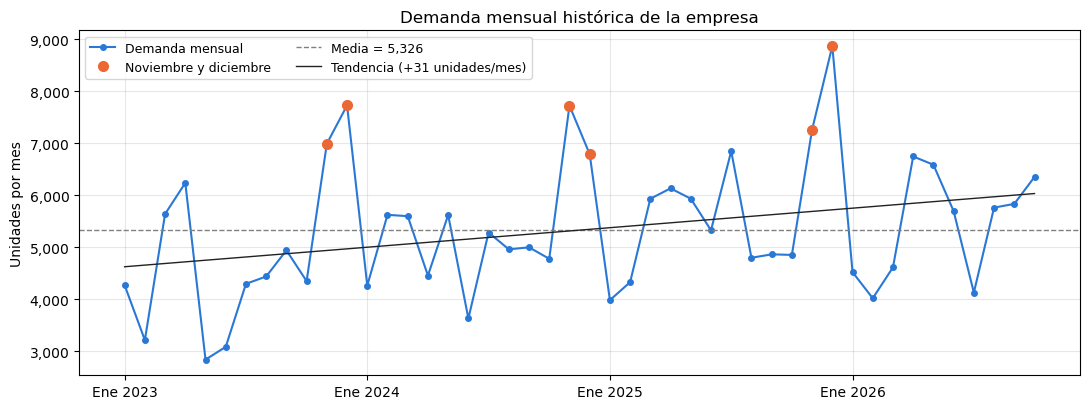

In [15]:
from scipy import stats                              # pruebas estadísticas: shapiro, ttest_ind, linregress

serie = np.array(demanda_historica)                  # la demanda como arreglo de numpy (permite filtrar y calcular fácil)
meses = np.arange(1, len(serie) + 1)                 # t = 1, 2, ..., 46
es_temporada = np.isin((meses - 1) % 12, [10, 11])   # True en noviembre y diciembre (% 12 da el mes del año, empezando en 0 = enero)

print(f"Media = {miles(serie.mean())}   Desviación = {miles(serie.std(ddof=1))}")   # media y desviación de toda la serie
print(f"Shapiro-Wilk (normalidad): p = {miles(stats.shapiro(serie).pvalue, 3)}")       # p > 0.05: no se rechaza que sea normal
print(f"Nov-dic: media {miles(serie[es_temporada].mean())}   |   resto del año: media {miles(serie[~es_temporada].mean())},"   # imprime la media de nov-dic frente al resto del año
      f" desviación {miles(serie[~es_temporada].std(ddof=1))}")                     # ~ significa "lo contrario" (los meses que no son nov-dic)
print(f"Prueba t nov-dic vs resto: p = {miles(stats.ttest_ind(serie[es_temporada], serie[~es_temporada], equal_var=False).pvalue, 5)}")   # ¿son distintas las medias?
regresion = stats.linregress(meses, serie)                                       # recta de tendencia: demanda contra el tiempo
print(f"Tendencia: {miles(regresion.slope, 1)} unidades más por mes (p = {miles(regresion.pvalue, 4)})")   # la pendiente = cuánto sube por mes

# Gráfica de la serie
figura, eje = plt.subplots(figsize=(11, 4.2))                                    # crea la figura y sus ejes
eje.plot(meses, serie, "o-", color="#2a78d6", markersize=4, label="Demanda mensual")   # la serie, con puntos unidos por línea
eje.plot(meses[es_temporada], serie[es_temporada], "o", color="#eb6834", markersize=7, label="Noviembre y diciembre")   # resalta nov y dic
eje.axhline(serie.mean(), color="gray", linestyle="--", linewidth=1, label=f"Media = {miles(serie.mean())}")   # línea horizontal en la media
eje.plot(meses, regresion.intercept + regresion.slope * meses, color="#222222", linewidth=1,
         label=f"Tendencia (+{miles(regresion.slope)} unidades/mes)")               # la recta de tendencia: a + b*t
eje.set_xticks(range(1, len(serie) + 1, 12), ["Ene 2023", "Ene 2024", "Ene 2025", "Ene 2026"])   # etiquetas del eje x cada 12 meses
eje.set_ylabel("Unidades por mes")                                               # título del eje y
eje.set_title("Demanda mensual histórica de la empresa")                         # título de la gráfica
eje.grid(alpha=0.3)                                                              # cuadrícula suave
eje.legend(fontsize=9, ncol=2)                                                   # leyenda en dos columnas
poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
plt.tight_layout()                                                               # ajusta márgenes para que nada se corte
plt.savefig(carpeta_graficas / "demanda_historica.png", dpi=200)                 # guarda la imagen en la carpeta de gráficas
plt.show()                                                                       # muestra la gráfica en pantalla

### 4.1 Nivel de inventario en el tiempo (las 6 políticas)

Son las gráficas de "serrucho": cómo sube y baja el inventario con cada política. Primero se resuelven los 6 modelos con los datos de la empresa. Para los modelos con descuento se usan los tramos del proveedor (descuento en todas las unidades):

| Pedido (unidades) | Descuento | Precio por unidad |
|---|---|---|
| [0, 4,000) | 0% | \$3,900 |
| [4,000, 9,000) | 2% | \$3,822 |
| [9,000, 15,000) | 5% | \$3,705 |
| [15,000, 20,000) | 8% | \$3,588 |

El último tramo llega hasta 20,000 unidades, que es la capacidad de la bodega; en el código se deja sin límite superior y la capacidad se revisa al final (sección de limitaciones).

In [16]:
# Tramos del proveedor (descuento en todas las unidades), como (desde, precio):
#   [0, 4000): 0%  |  [4000, 9000): 2%  |  [9000, 15000): 5%  |  [15000, 20000): 8% (20000 = capacidad)
precio_lista = datos_empresa["costo_unitario"]       # precio de lista (sin descuento)
tramos_empresa = [(0, precio_lista),                 # menos de 4,000 unidades: precio de lista
                  (4_000, precio_lista * (1 - 0.02)),    # desde 4,000: 2% de descuento
                  (9_000, precio_lista * (1 - 0.05)),    # desde 9,000: 5% de descuento
                  (15_000, precio_lista * (1 - 0.08))]   # desde 15,000: 8% de descuento

datos = datos_empresa                                # un nombre más corto para escribir menos
datos_sin_precio = dict(datos)                       # copia de los datos
del datos_sin_precio["costo_unitario"]               # para los modelos con descuento el precio lo dan los tramos

# EOQ
q_eoq, t_eoq, r_eoq, g_eoq = resolver_eoq_sin_desc_devuelve_Q_T_R_G(datos["demanda"], datos["costo_pedido"],   # EOQ sin descuentos: Q*, T*, R y G*
                                                datos["costo_unitario"], datos["tasa_manejo"],   # continúa los parámetros: precio, tasa de manejo y (abajo) lead time
                                                datos["lead_time"])               # EOQ sin descuentos
sol_eoq_con_desc, _ = resolver_eoq_con_desc_devuelve_mejor_y_candidatos(datos["demanda"], datos["costo_pedido"], tramos_empresa,   # EOQ con descuentos (el _ guarda los candidatos que no se usan aquí)
                                 datos["tasa_manejo"], datos["lead_time"])        # EOQ con descuentos
# (el _ es una variable que no se va a usar: aquí son los candidatos, que no necesitamos)

# (Q,R)
sol_qr_sin_desc = resolver_qr_sin_desc_devuelve_solucion_con_iteraciones(**datos)                                       # (Q,R) sin descuentos
sol_qr_con_desc, _ = resolver_qr_con_desc_devuelve_mejor_y_candidatos(tramos=tramos_empresa, **datos_sin_precio)  # (Q,R) con descuentos

# (S,T): T solo puede ser un número entero de días (1 día = 1/30 de mes)
sol_st_sin_desc = resolver_st_sin_desc_devuelve_solucion_con_T_probados(**datos, paso=1/30)                            # (S,T) sin descuentos
sol_st_con_desc, _ = resolver_st_con_desc_devuelve_mejor_y_candidatos(tramos=tramos_empresa, **datos_sin_precio, paso=1/30)   # (S,T) con descuentos

print(f"EOQ sin descuento:   Q = {miles(q_eoq)}   R = {miles(r_eoq)}   G = {pesos(g_eoq)}")   # imprime el resultado del EOQ sin descuentos
print(f"EOQ con descuento:   Q = {miles(sol_eoq_con_desc['Q'])}   R = {miles(sol_eoq_con_desc['R'])}   G = {pesos(sol_eoq_con_desc['costo'])}")   # imprime el resultado del EOQ con descuentos
print(f"(Q,R) sin descuento: Q = {miles(sol_qr_sin_desc['Q'])}   R = {miles(sol_qr_sin_desc['R'])}   G = {pesos(sol_qr_sin_desc['costos']['total'])}")   # imprime el resultado del (Q,R) sin descuentos
print(f"(Q,R) con descuento: Q = {miles(sol_qr_con_desc['Q'])}   R = {miles(sol_qr_con_desc['R'])}   G = {pesos(sol_qr_con_desc['costos']['total'])}")   # imprime el resultado del (Q,R) con descuentos
print(f"(S,T) sin descuento: T = {miles(sol_st_sin_desc['T'], 4)} meses   S = {miles(sol_st_sin_desc['S'])}   G = {pesos(sol_st_sin_desc['costos']['total'])}")   # imprime el resultado del (S,T) sin descuentos
print(f"(S,T) con descuento: T = {miles(sol_st_con_desc['T'], 4)} meses   S = {miles(sol_st_con_desc['S'])}   G = {pesos(sol_st_con_desc['costos']['total'])}")   # imprime el resultado del (S,T) con descuentos

EOQ sin descuento:   Q = 4,048   R = 888   G = $21,164,214
EOQ con descuento:   Q = 15,000   R = 888   G = $19,833,977
(Q,R) sin descuento: Q = 4,254   R = 1,917   G = $21,284,666
(Q,R) con descuento: Q = 15,000   R = 1,617   G = $19,921,138
(S,T) sin descuento: T = 0.6333 meses   S = 6,629   G = $21,443,455
(S,T) con descuento: T = 2.8333 meses   S = 19,064   G = $20,206,898


**Cómo se dibujan.** Los serruchos se hacen con el **valor esperado** de la demanda: se supone que el inventario baja siempre a ritmo $\lambda$, la demanda media. No hay nada aleatorio; son las mismas cuentas del modelo dibujadas en el tiempo, así que todos los ciclos son iguales:

- Se piden $q$ unidades: $Q$ en EOQ y (Q,R), y $\lambda T$ en (S,T).
- Cada ciclo dura $q/\lambda$.
- Cuando llega un pedido el inventario está en el inventario de seguridad $ss$ y sube a $ss+q$. Luego baja hasta volver a $ss$.
- El pedido se hace $\tau$ antes de que llegue. En ese momento el inventario vale $ss+\lambda\tau$, que en el (Q,R) es justo $R$.

| Política | Pedido $q$ | Inventario de seguridad $ss$ |
|---|---|---|
| EOQ | $Q$ | $0$ |
| (Q,R) | $Q$ | $R-\lambda\tau$ |
| (S,T) | $\lambda T$ | $S-\lambda(T+\tau)$ |

Se grafican dos curvas:
- **Inventario neto** (azul): lo que hay en bodega.
- **Posición de inventario** (naranja): inventario neto más lo que viene en camino. Es la que se compara con $R$ o se sube hasta $S$, y sube de golpe cuando se hace el pedido.

Todo está en **meses**, igual que los datos. Se dibujan 8 meses.

In [17]:
# -----------------------------------------------------------------------------
# Serrucho con el valor esperado de la demanda (sin simulación)
# El inventario baja siempre a ritmo lambda, así que todos los ciclos son iguales.
# La misma función sirve para las 3 políticas:
#   EOQ:   q = Q,          ss = 0
#   (Q,R): q = Q,          ss = R - lambda*tau
#   (S,T): q = lambda*T,   ss = S - lambda*(T + tau)
# -----------------------------------------------------------------------------
HORIZONTE_MESES = 8          # meses que se dibujan


def serrucho_esperado_devuelve_puntos_neto_posicion_y_pedidos(q, ss, demanda, lead_time, horizonte=HORIZONTE_MESES):   # calcula los puntos del serrucho
    """Puntos del inventario neto y de la posición de inventario con la demanda media.

    Cada ciclo dura q/lambda. Al empezar el ciclo llega un pedido y el inventario sube a ss + q;
    después baja en línea recta hasta ss. El pedido se hace tau antes de que llegue
    (se supone que tau es menor que el ciclo: un solo pedido en camino).
    Devuelve: tiempos y valores del neto, tiempos y valores de la posición, y los momentos de pedido.
    """
    ciclo = q / demanda                            # duración de un ciclo: lo que tarda en consumirse un pedido
    nivel_al_pedir = ss + demanda * lead_time      # inventario cuando se pide (= R en el (Q,R))
    t_neto, neto = [], []                          # puntos (tiempo, valor) del inventario neto
    t_posicion, posicion = [], []                  # puntos (tiempo, valor) de la posición de inventario
    momentos_pedido = []                           # tiempos en los que se hace un pedido
    inicio = 0                                     # el primer ciclo empieza en el tiempo 0
    while inicio < horizonte:                      # se dibujan ciclos hasta cubrir los 8 meses
        fin = inicio + ciclo                       # el ciclo termina cuando llega el siguiente pedido
        pedido = fin - lead_time                   # se pide tau antes de que llegue el siguiente pedido

        # Inventario neto: baja de ss + q a ss. Como el siguiente ciclo arranca en el mismo tiempo
        # con ss + q, al unir los puntos queda el salto vertical del serrucho.
        t_neto += [inicio, fin]                    # dos puntos: inicio y fin del ciclo
        neto += [ss + q, ss]                       # arranca en ss + q y baja hasta ss

        # Posición: igual al neto hasta que se pide; ahí sube q (lo que viene en camino)
        t_posicion += [inicio, pedido, pedido, fin]                        # el instante del pedido aparece dos veces para dibujar el salto
        posicion += [ss + q, nivel_al_pedir, nivel_al_pedir + q, ss + q]   # baja hasta el nivel de pedido, salta q, y sigue bajando

        momentos_pedido.append(pedido)             # guarda cuándo se pidió
        inicio = fin                               # el siguiente ciclo empieza donde termina este
    return t_neto, neto, t_posicion, posicion, momentos_pedido   # devuelve los cinco resultados

`graficar_serrucho_devuelve_momentos_de_pedido` dibuja el serrucho de una política en unos ejes: el inventario neto, la posición (si se pide) y la línea del inventario de seguridad. Devuelve los momentos en que se pide, que en el (S,T) son las revisiones. `poner_leyenda_abajo` pone una sola leyenda debajo de las dos gráficas para que no tape las curvas.

In [18]:
def graficar_serrucho_devuelve_momentos_de_pedido(eje, q, ss, titulo, con_posicion=True):   # dibuja el serrucho de una política en unos ejes
    """Dibuja el serrucho esperado de una política. Devuelve los momentos de pedido."""
    t_neto, neto, t_pos, posicion, momentos_pedido = serrucho_esperado_devuelve_puntos_neto_posicion_y_pedidos(q, ss, datos["demanda"],   # puntos del serrucho de esta política
                                                                       datos["lead_time"])   # calcula los puntos
    if con_posicion:                                                                     # (en el EOQ no se dibuja la posición)
        eje.plot(t_pos, posicion, color="#eb6834", linewidth=1.5, label="Posición de inventario")   # curva naranja
    eje.plot(t_neto, neto, color="#2a78d6", linewidth=2, label="Inventario neto")        # curva azul
    if ss > 0:                                                                           # si hay inventario de seguridad...
        eje.axhline(ss, color="#1baf7a", linestyle=":", linewidth=1.5, label="Inventario de seguridad ss")   # ...línea verde punteada en ss
    eje.axhline(0, color="black", linewidth=0.8)                                         # línea del cero
    eje.set_xlim(0, HORIZONTE_MESES)                                                     # el eje x va de 0 a 8 meses
    eje.set_title(titulo)                                                                # título de la gráfica
    eje.set_xlabel("Tiempo (meses)")                                                     # título del eje x
    eje.grid(alpha=0.3)                                                                  # cuadrícula suave
    return momentos_pedido                                                               # devuelve los momentos de pedido (en (S,T) son las revisiones)


def poner_leyenda_abajo(figura, *ejes):                                  # una sola leyenda para las gráficas de la figura
    """Una sola leyenda debajo de las gráficas, para que no tape las curvas. Junta las líneas de los ejes dados, sin repetir nombres."""
    lineas, nombres = [], []                                             # líneas y nombres que van en la leyenda
    for eje in ejes:                                                     # recorre los ejes dados
        for linea, nombre in zip(*eje.get_legend_handles_labels()):      # cada línea con nombre de ese eje
            if nombre not in nombres:                                    # si ese nombre todavía no está...
                lineas.append(linea); nombres.append(nombre)             # ...se agrega a la leyenda
    figura.legend(lineas, nombres, loc="lower center", ncol=len(nombres), frameon=False)   # la pone abajo, en una fila y sin marco
    plt.tight_layout(rect=(0, 0.07, 1, 1))     # deja espacio abajo para la leyenda

**EOQ.** El inventario baja a ritmo constante $\lambda$ y cuando llega a cero entra el pedido $Q$ (no hay inventario de seguridad). La línea punteada es $R=\lambda\tau$: cuando el inventario la cruza se hace el pedido, que llega justo al llegar a cero. Con descuento se pide más en cada pedido y los ciclos son más largos.

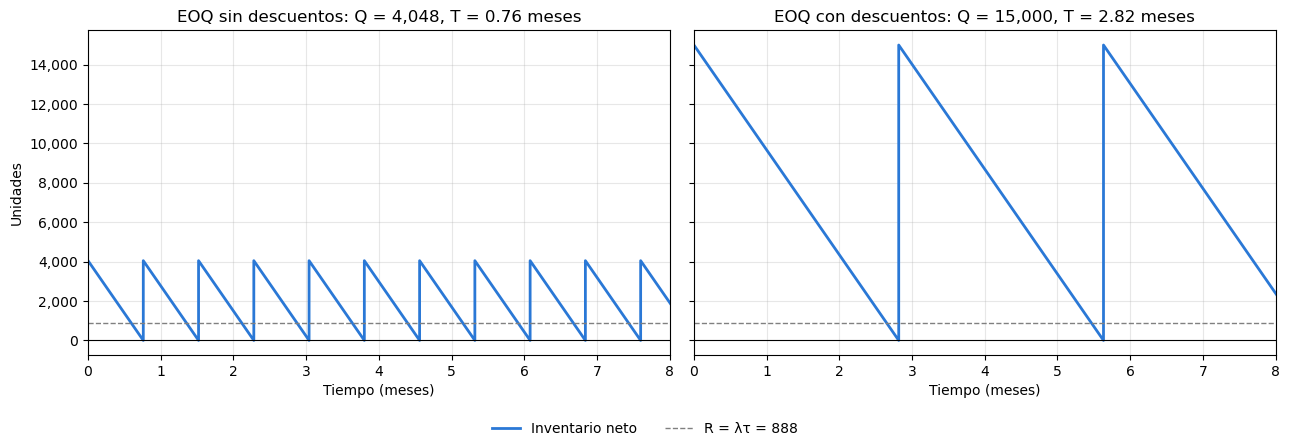

In [19]:
# --- EOQ: ss = 0; se pide cuando el inventario llega a R = lambda*tau ---
figura, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)   # 2 gráficas lado a lado (comparten el eje y)
casos = [("EOQ sin descuentos", q_eoq), ("EOQ con descuentos", sol_eoq_con_desc["Q"])]   # (título, Q) de cada gráfica
for eje, (titulo, Q) in zip(ejes, casos):                            # zip recorre los ejes y los casos al tiempo
    graficar_serrucho_devuelve_momentos_de_pedido(eje, Q, 0, f"{titulo}: Q = {miles(Q)}, T = {miles(Q / datos['demanda'], 2)} meses",   # dibuja el serrucho del EOQ
                      con_posicion=False)                            # en el EOQ: q = Q, ss = 0, sin posición
    eje.axhline(r_eoq, color="gray", linestyle="--", linewidth=1, label=f"R = λτ = {miles(r_eoq)}")   # línea gris en R

ejes[0].set_ylabel("Unidades")                                       # título del eje y (solo en la primera gráfica)
poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
poner_leyenda_abajo(figura, ejes[0])                                 # una sola leyenda abajo
plt.savefig(carpeta_graficas / "inventario_eoq.png", dpi=200)        # guarda la imagen
plt.show()                                                           # muestra la gráfica

**(Q,R).** El inventario neto (azul) baja a ritmo $\lambda$. Cuando la posición (naranja) llega a $R$ se piden $Q$ y la posición sube de golpe; $\tau$ después llega el pedido y sube el inventario neto. Justo antes de que llegue, el inventario neto está en el inventario de seguridad $ss=R-\lambda\tau$ (línea verde). Con descuento se pide un $Q$ más grande, así que los ciclos son más largos y el inventario promedio es más alto.

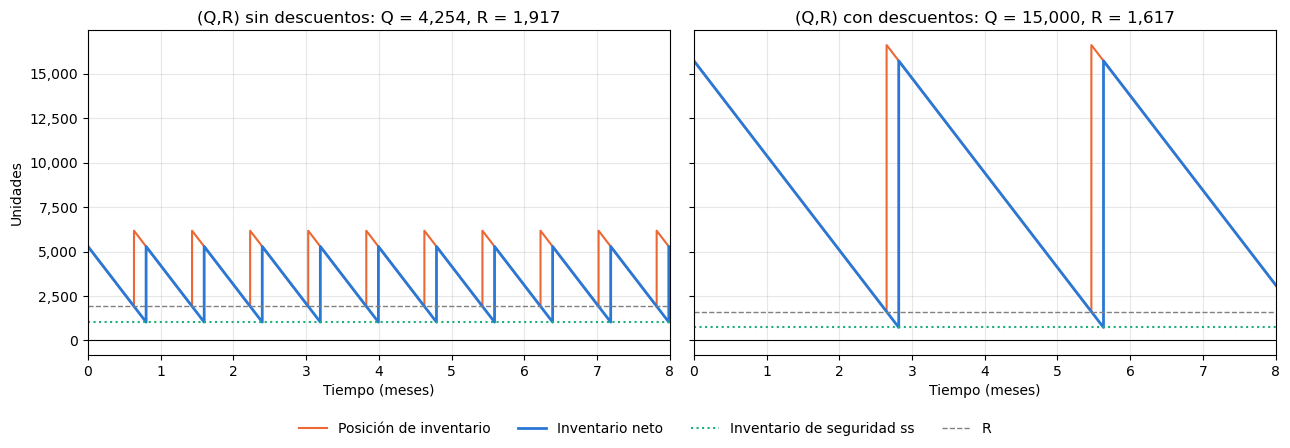

In [20]:
# --- (Q,R): cuando la posición llega a R se piden Q; el pedido llega tau después ---
figura, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)    # 2 gráficas lado a lado
casos = [("(Q,R) sin descuentos", sol_qr_sin_desc), ("(Q,R) con descuentos", sol_qr_con_desc)]   # (título, solución) de cada gráfica
for eje, (titulo, sol) in zip(ejes, casos):                          # recorre los dos casos
    graficar_serrucho_devuelve_momentos_de_pedido(eje, sol["Q"], sol["ss"], f"{titulo}: Q = {miles(sol['Q'])}, R = {miles(sol['R'])}")   # en el (Q,R): q = Q, ss = R - mu_tau
    eje.axhline(sol["R"], color="gray", linestyle="--", linewidth=1, label="R")   # línea gris en R

ejes[0].set_ylabel("Unidades")                                       # título del eje y
poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
poner_leyenda_abajo(figura, ejes[0])                                 # una sola leyenda abajo
plt.savefig(carpeta_graficas / "inventario_qr.png", dpi=200)         # guarda la imagen
plt.show()                                                           # muestra la gráfica

**(S,T).** Las líneas verticales grises son las revisiones (cada $T$). En cada revisión la posición sube hasta $S$; como la demanda es su media, siempre se piden $\lambda T$ unidades. El pedido llega $\tau$ después, cuando el inventario neto está en $ss=S-\lambda(T+\tau)$. Con descuento se revisa con menos frecuencia, se pide más y $S$ es más alto, porque debe cubrir un horizonte $T+\tau$ más largo.

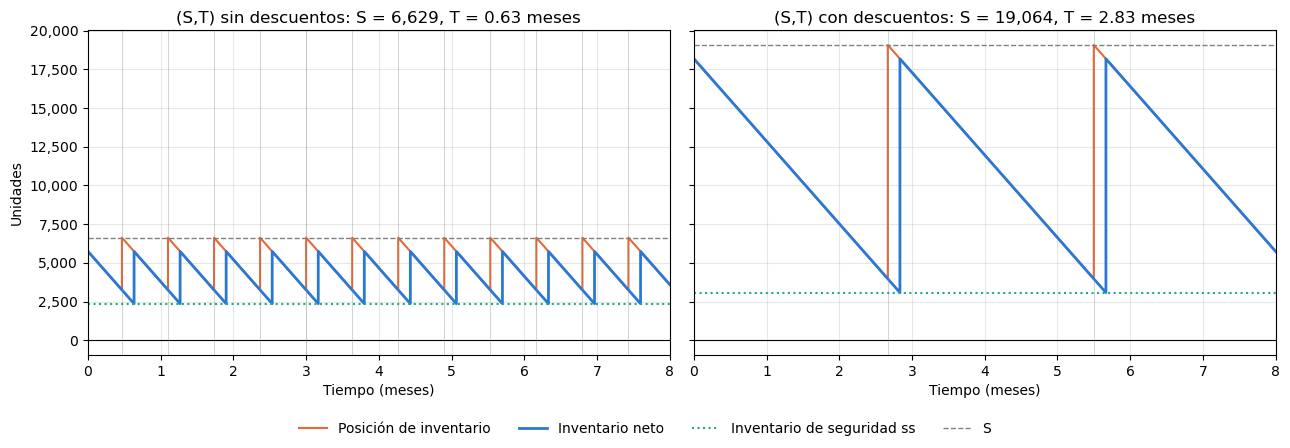

In [21]:
# --- (S,T): cada T se pide lo necesario para subir la posición a S (en promedio, lambda*T) ---
figura, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)    # 2 gráficas lado a lado
casos = [("(S,T) sin descuentos", sol_st_sin_desc), ("(S,T) con descuentos", sol_st_con_desc)]   # (título, solución) de cada gráfica
for eje, (titulo, sol) in zip(ejes, casos):                          # recorre los dos casos
    pedido = datos["demanda"] * sol["T"]                             # q = lambda * T: lo que se pide en promedio en cada revisión
    revisiones = graficar_serrucho_devuelve_momentos_de_pedido(eje, pedido, sol["ss"],   # dibuja el serrucho del (S,T) y guarda los momentos de revisión
                                   f"{titulo}: S = {miles(sol['S'])}, T = {miles(sol['T'], 2)} meses")   # en el (S,T): ss = S - mu_{T+tau}
    eje.axhline(sol["S"], color="gray", linestyle="--", linewidth=1, label="S")   # línea gris en S
    for revision in revisiones:                                      # líneas en cada revisión
        eje.axvline(revision, color="gray", linewidth=0.6, alpha=0.4)   # línea vertical gris suave

ejes[0].set_ylabel("Unidades")                                       # título del eje y
poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
poner_leyenda_abajo(figura, ejes[0])                                 # una sola leyenda abajo
plt.savefig(carpeta_graficas / "inventario_st.png", dpi=200)         # guarda la imagen
plt.show()                                                           # muestra la gráfica

### 4.2 Superficies de costo sin descuento: (Q,R) y (S,T)

Primero se resuelve el modelo con los datos de la empresa y se muestran las iteraciones.

In [22]:
resultado_empresa_qr = resolver_qr_sin_desc_devuelve_solucion_con_iteraciones(**datos_empresa)   # resuelve el (Q,R) sin descuentos con los datos de la empresa

print(" k |       Q |   F(R) |     z |       R")                   # encabezado de la tabla de iteraciones
for fila in resultado_empresa_qr["iteraciones"]:                  # una línea por iteración
    print(f"{fila['k']:2d} | {miles(fila['Q'], 1):>7} | {miles(fila['F(R)'], 4)} | {miles(fila['z'], 3)} | {miles(fila['R'], 1):>7}")   # imprime una fila de la tabla de iteraciones
r = resultado_empresa_qr                                          # un nombre más corto
print(f"\nQ* = {miles(r['Q'])} unidades   R* = {miles(r['R'])} unidades   ss = {miles(r['ss'])}")   # imprime el óptimo: Q*, R* y el inventario de seguridad
print(f"alfa = {miles(r['alfa'], 4)}   beta = {miles(r['beta'], 4)}")   # imprime los niveles de servicio alfa y beta
print(f"Costo total mensual = {pesos(r['costos']['total'])}")   # imprime el costo total

 k |       Q |   F(R) |     z |       R
 0 | 4,048.0 | 0.9753 | 1.965 | 1,928.2
 1 | 4,243.1 | 0.9741 | 1.945 | 1,917.5
 2 | 4,253.5 | 0.9740 | 1.944 | 1,916.9
 3 | 4,254.0 | 0.9740 | 1.944 | 1,916.9
 4 | 4,254.1 | 0.9740 | 1.944 | 1,916.9
 5 | 4,254.1 | 0.9740 | 1.944 | 1,916.9

Q* = 4,254 unidades   R* = 1,917 unidades   ss = 1,029
alfa = 0.9740   beta = 0.9988
Costo total mensual = $21,284,666


Para dibujar $G(Q,R)$ hay que calcular el costo en muchas combinaciones de $Q$ y $R$. Para cada $Q$ se calcula su mejor $R$ y se toman valores de $R$ desde 2 desviaciones por debajo hasta 2 por encima de ese mejor $R$ (una "franja"). La función `superficie_qr_devuelve_matrices_Q_R_G` arma esas combinaciones y se las pasa a `costo_en_rejilla_qr_devuelve_matriz_G`, que las recorre con dos `for` y guarda el costo de cada una en una matriz `G`, usando la función `costos_qr_devuelve_ordenar_adquirir_mantener_faltantes_total` de la sección 2. Para el (S,T) se hace exactamente lo mismo con `superficie_st_devuelve_matrices_T_S_G` y `costo_en_rejilla_st_devuelve_matriz_G`.

In [23]:
def costo_en_rejilla_qr_devuelve_matriz_G(Q, R, datos, precio):                        # calcula G en cada punto de dos matrices Q y R
    """G(Q,R) (en millones) en cada casilla de las matrices Q y R, con el precio dado."""
    h = h_costo_mantener_una_unidad(datos["tasa_manejo"], precio)          # h = i*c con el precio dado
    media_lead, desviacion_lead = demanda_horizonte_devuelve_media_y_desviacion(datos["demanda"], datos["desviacion"],   # mu_tau y sigma_tau (iguales para todos los puntos)
                                                       datos["lead_time"])   # mu_tau y sigma_tau (iguales para todos los puntos)
    G = np.zeros(Q.shape)                                     # matriz vacía (de ceros) del mismo tamaño para guardar los costos
    for i in range(Q.shape[0]):                               # recorre las filas...
        for j in range(Q.shape[1]):                           # ...y las columnas: casilla por casilla
            costos = costos_qr_devuelve_ordenar_adquirir_mantener_faltantes_total(Q[i, j], R[i, j], datos["demanda"], datos["costo_pedido"],   # costos desglosados de ese (Q,R)
                               precio, h, datos["costo_faltante"],
                               media_lead, desviacion_lead)   # G del par (Q,R) de esta casilla
            G[i, j] = costos["total"] / 1e6                   # se guarda el total, en millones de pesos
    return G   # devuelve la matriz de costos


def superficie_qr_devuelve_matrices_Q_R_G(datos, precio, valores_q, desfases_z):         # arma la rejilla (Q, R, G) en forma de franja
    """Rejilla (Q, R, G) con R = mejor R de cada Q + desfase * sigma_tau (los desfases se dan en desviaciones)."""
    h = h_costo_mantener_una_unidad(datos["tasa_manejo"], precio)             # h = i*c con el precio dado
    media_lead, desviacion_lead = demanda_horizonte_devuelve_media_y_desviacion(datos["demanda"], datos["desviacion"], datos["lead_time"])   # mu_tau y sigma_tau
    Q = np.zeros((len(desfases_z), len(valores_q)))              # matriz de Q (se llena abajo)
    R = np.zeros_like(Q)                                         # matriz de R, del mismo tamaño
    for j, q in enumerate(valores_q):                            # para cada Q
        r_centro, _, _ = punto_reorden_dado_q_devuelve_R_z_alfa(q, h, datos["demanda"], datos["costo_faltante"], media_lead, desviacion_lead)   # el mejor R de ese Q (el que da F(R) = 1 - Qh/(p*lambda)): el centro de la franja
        for i, desfase in enumerate(desfases_z):                 # para cada desfase (en desviaciones) alrededor del mejor R
            Q[i, j], R[i, j] = q, r_centro + desfase * desviacion_lead   # Q fijo en esta columna; R = mejor R + desfase * sigma_tau
    G = costo_en_rejilla_qr_devuelve_matriz_G(Q, R, datos, precio)   # costo en cada punto
    return Q, R, G   # devuelve las matrices Q, R y G


q_opt = resultado_empresa_qr["Q"]                             # Q* del (Q,R) sin descuentos
r_opt = resultado_empresa_qr["R"]                             # R*
g_opt = resultado_empresa_qr["costos"]["total"] / 1e6         # G* en millones (para marcar el óptimo en la gráfica)

**Superficie 3D.** Muestra $G(Q,R)$ como un "tazón": el punto más bajo es el óptimo $(Q^*,R^*)$. En el piso de la gráfica se proyectan las curvas de nivel y el óptimo, para ubicarlo mejor. $Q$ va de la mitad al doble de $Q^*$ y, para cada $Q$, $R$ va desde el mejor $R$ de ese $Q$ menos 2 desviaciones ($2\sigma_\tau$) hasta el mejor $R$ más 2 desviaciones. El ángulo de la cámara se cambia con `view_init(elev, azim)`; en VS Code se puede probar varios hasta que se vea bien.

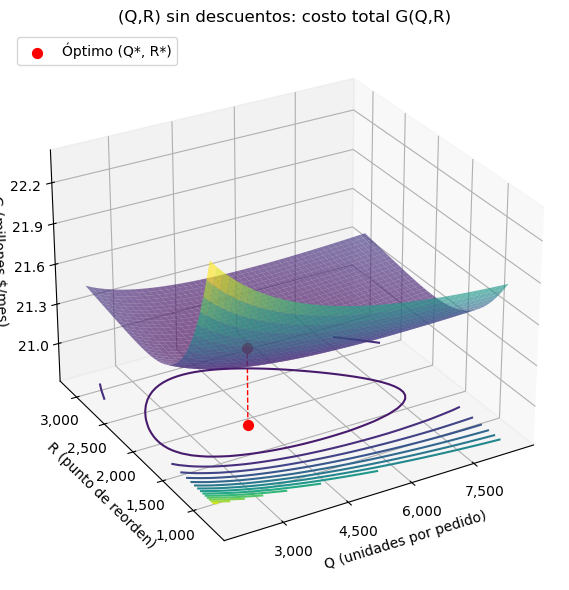

In [24]:
# --- Superficie 3D de G(Q,R) ---
# Q va de la mitad al doble de Q*. Para cada Q, R va desde el mejor R de ese Q menos 2 desviaciones hasta el mejor R más 2 desviaciones.
Q, R, G = superficie_qr_devuelve_matrices_Q_R_G(datos_empresa, datos_empresa["costo_unitario"],   # franja de 40 x 50 puntos (Q,R) con su costo G
                            np.linspace(q_opt / 2, 2 * q_opt, 50),   # 50 valores de Q entre Q*/2 y 2Q*
                            np.linspace(-2, 2, 40))   # 40 desfases de R: de -2 a +2 desviaciones respecto al mejor R de cada Q

figura = plt.figure(figsize=(8, 6))                        # crea la figura
ejes = figura.add_subplot(projection="3d")                 # ejes en 3D
ejes.plot_surface(Q, R, G, cmap="viridis", alpha=0.65)      # dibuja la superficie; cmap = escala de colores, alpha = transparencia (0.65 deja ver un poco el óptimo detrás)

# Curvas de nivel proyectadas en el "piso" de la gráfica (offset = altura del piso)
piso = G.min() - (G.max() - G.min()) * 0.5                 # altura del piso: 50% del rango de G por debajo del costo mínimo
ejes.contour(Q, R, G, levels=15, cmap="viridis", offset=piso)   # 15 curvas de nivel (G constante) dibujadas en el piso
ejes.scatter(q_opt, r_opt, piso, color="red", s=50)                         # óptimo en el piso
ejes.plot([q_opt, q_opt], [r_opt, r_opt], [piso, g_opt], "r--", linewidth=1)  # línea vertical punteada del piso a la superficie
ejes.scatter(q_opt, r_opt, g_opt, color="red", s=50, label="Óptimo (Q*, R*)")  # óptimo sobre la superficie

ejes.set_zlim(piso, G.max())                               # el eje z empieza en el piso
ejes.set_xlabel("Q (unidades por pedido)")                 # título del eje x
ejes.set_ylabel("R (punto de reorden)")                    # título del eje y
ejes.set_zlabel("G (millones $/mes)")                      # título del eje z
ejes.set_title("(Q,R) sin descuentos: costo total G(Q,R)") # título de la gráfica
ejes.view_init(elev=28, azim=-120)        # ángulo de la cámara (elev = qué tan alto mira, azim = cuánto gira)
ejes.legend(loc="upper left")                              # leyenda arriba a la izquierda
poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
plt.tight_layout()                                         # ajusta márgenes
plt.savefig(carpeta_graficas / "qr_superficie.png", dpi=200)   # guarda la imagen
plt.show()                                                 # muestra la gráfica

**Superficie 3D de $G(S,T)$ (sin descuento).** Para cada $T$ hay un solo $S$ bueno, y ese $S$ sube cuando $T$ sube porque hay que cubrir más demanda ($T+\tau$). Por eso no se dibuja un rectángulo fijo de $S$ (con $T$ grande y $S$ pequeño los faltantes se disparan y tapan todo), sino una **franja alrededor del mejor $S$ de cada $T$**: desde 2 desviaciones por debajo hasta 2 por encima ($\pm 2\sigma_{T+\tau}$). El punto rojo es el óptimo. $T$ va de la mitad al doble de $T^*$.

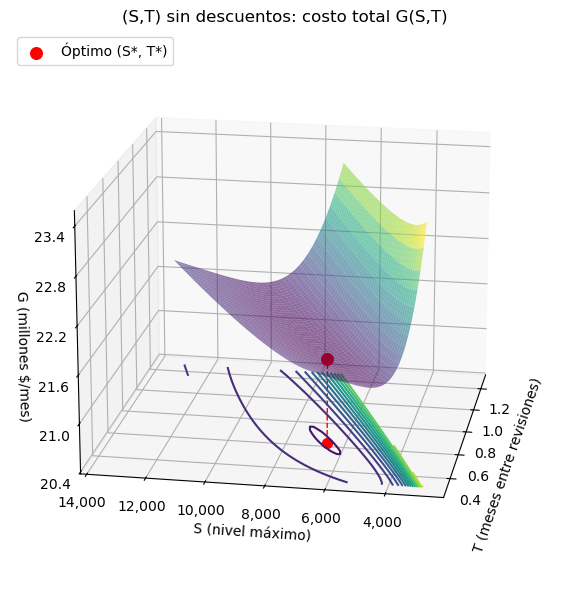

In [25]:
# --- Superficie 3D de G(S,T) sin descuento ---
# T va de la mitad al doble de T*.
# Para cada T se dibuja una franja de S alrededor de su mejor S (la que da F(S) = 1 - hT/p).
# Si se usara un rectángulo fijo de S, con T grande y S pequeño los faltantes se disparan
# y no se vería el "valle".
def costo_en_rejilla_st_devuelve_matriz_G(T, S, datos, precio):                        # calcula G en cada punto de dos matrices T y S
    """G(S,T) (en millones) en cada casilla de las matrices T y S, con el precio dado."""
    h = h_costo_mantener_una_unidad(datos["tasa_manejo"], precio)          # h = i*c con el precio dado
    G = np.zeros(T.shape)                                     # matriz vacía (de ceros) del mismo tamaño para guardar los costos
    for i in range(T.shape[0]):                               # recorre las filas...
        for j in range(T.shape[1]):                           # ...y las columnas: casilla por casilla
            media_h, desviacion_h = demanda_horizonte_devuelve_media_y_desviacion(datos["demanda"], datos["desviacion"], T[i, j] + datos["lead_time"])   # mu y sigma de la demanda en T + tau
            costos = costos_st_devuelve_ordenar_adquirir_mantener_faltantes_total(S[i, j], T[i, j], datos["demanda"], datos["costo_pedido"], precio, h,
                                datos["costo_faltante"], media_h, desviacion_h)   # costos desglosados de ese (S,T)
            G[i, j] = costos["total"] / 1e6                   # se guarda el total, en millones de pesos
    return G   # devuelve la matriz de costos


def superficie_st_devuelve_matrices_T_S_G(datos, precio, valores_t, desfases_z):         # arma la rejilla (T, S, G) en forma de franja
    """Rejilla (T, S, G) con S = mejor S de cada T + desfase * sigma_{T+tau} (los desfases se dan en desviaciones)."""
    T = np.zeros((len(desfases_z), len(valores_t)))              # matriz de T (se llena abajo)
    S = np.zeros_like(T)                                         # matriz de S, del mismo tamaño
    for j, t in enumerate(valores_t):                            # para cada T
        s_centro = mejor_s_dado_t_devuelve_solucion_o_None(t, **dict(datos, costo_unitario=precio))["S"]   # el mejor S de ese T (el que da F(S) = 1 - hT/p): el centro de la franja
        media_h, desviacion_h = demanda_horizonte_devuelve_media_y_desviacion(datos["demanda"], datos["desviacion"], t + datos["lead_time"])   # mu y sigma de la demanda en T + tau
        for i, desfase in enumerate(desfases_z):                 # para cada desfase (en desviaciones) alrededor del mejor S
            T[i, j], S[i, j] = t, s_centro + desfase * desviacion_h   # T fijo en esta columna; S = mejor S + desfase * sigma_{T+tau}
    G = costo_en_rejilla_st_devuelve_matriz_G(T, S, datos, precio)   # costo en cada punto
    return T, S, G   # devuelve las matrices T, S y G


valores_t = np.linspace(sol_st_sin_desc["T"] / 2, 2 * sol_st_sin_desc["T"], 50)   # 50 valores de T entre T*/2 y 2T*
T, S, G = superficie_st_devuelve_matrices_T_S_G(datos_empresa, datos_empresa["costo_unitario"], valores_t, np.linspace(-2, 2, 40))   # franja de ±2 desviaciones

figura = plt.figure(figsize=(8, 6))                            # crea la figura
ejes = figura.add_subplot(projection="3d")                     # ejes en 3D
ejes.plot_surface(T, S, G, cmap="viridis", alpha=0.6)          # dibuja la superficie (0.6 deja ver un poco el óptimo detrás)
piso = G.min() - (G.max() - G.min()) * 0.5                     # altura del piso: 50% del rango de G por debajo del costo mínimo
ejes.contour(T, S, G, levels=15, cmap="viridis", offset=piso)  # curvas de nivel en el piso
t_opt, s_opt, g_opt = sol_st_sin_desc["T"], sol_st_sin_desc["S"], sol_st_sin_desc["costos"]["total"] / 1e6   # el óptimo (S*, T*) y su costo en millones
ejes.plot([t_opt, t_opt], [s_opt, s_opt], [piso, g_opt], "r--", linewidth=1)   # línea vertical punteada del piso al óptimo
ejes.scatter(t_opt, s_opt, piso, color="red", s=50)            # óptimo en el piso
ejes.scatter(t_opt, s_opt, g_opt, color="red", s=70, label="Óptimo (S*, T*)", depthshade=False)   # óptimo sobre la superficie
ejes.set_zlim(piso, G.max())                                   # el eje z empieza en el piso
ejes.set_xlabel("T (meses entre revisiones)")                  # título del eje x
ejes.set_ylabel("S (nivel máximo)")                            # título del eje y
ejes.set_zlabel("G (millones $/mes)")                          # título del eje z
ejes.set_title("(S,T) sin descuentos: costo total G(S,T)")     # título de la gráfica
ejes.view_init(elev=18, azim=190)                             # ángulo de la cámara (el que se escogió mirando la gráfica interactiva)
ejes.legend(loc="upper left")                                  # leyenda arriba a la izquierda
poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
plt.tight_layout()                                             # ajusta márgenes
plt.savefig(carpeta_graficas / "st_superficie.png", dpi=200)   # guarda la imagen
plt.show()                                                     # muestra la gráfica

### 4.3 Costos vs Q (o vs T) de cada política

Para cada modelo (EOQ, (Q,R) y (S,T)) se hacen 4 gráficas:

- **a) Sin descuento:** cada costo por separado (ordenar, mantener y, si el modelo los tiene, faltantes) y su suma, como la gráfica clásica del EOQ. El costo de adquirir $\lambda c$ no se grafica porque es constante (no depende de $Q$) y es mucho más grande que los demás: si se pusiera, aplastaría las otras curvas.
- **b) Con descuento, una gráfica por tramo:** lo mismo, pero con el precio de cada tramo. La zona sombreada es donde ese precio sí aplica, el **círculo vacío** es el mínimo de la curva con ese precio (el EOQ de ese precio; en (Q,R) y (S,T), el Q o T óptimo del tramo) y la estrella es el candidato del tramo. Si el círculo cae **dentro** de la zona sombreada, la estrella queda en él (caso A); si cae **por debajo**, la estrella va al límite inferior de la zona (caso B); si cae **por encima**, el tramo se descarta (caso C).
- **c) Con descuento, costo total de cada tramo:** aquí sí se incluye el costo de adquirir, porque es lo que diferencia a los tramos. La parte gruesa de cada curva es donde aplica el precio; la punteada no se puede usar. La estrella roja es el óptimo.
- **d) Sin descuento vs con descuento:** el costo total de la política con precio fijo frente al de la política con descuento. La curva con descuento tiene saltos en los quiebres.

**Qué va en el eje x:**
- EOQ y (Q,R): $Q$. En el (Q,R) cada $Q$ usa su mejor $R$ (el de $F(R)=1-Qh/(p\lambda)$).
- (S,T): $T$, que es su variable de decisión, con su mejor $S$. Arriba se agrega un segundo eje con el pedido promedio $\lambda T$, para comparar con los quiebres de cantidad.

`costos_en_punto_devuelve_diccionario_o_None` calcula los costos de un modelo en un valor de x, y `curva_costos_devuelve_listas_en_millones` lo repite para todos los valores. `dibujar_curva_con_descuento` dibuja la curva del costo total con descuento (por pedazos, para no unir los saltos de los quiebres); la usan la gráfica d) y la de la política actual. Las funciones `miles` y `pesos` escriben los números con coma de miles y punto decimal (93,265,795).

In [26]:
from matplotlib.lines import Line2D     # para armar entradas de leyenda "a mano"




# -----------------------------------------------------------------------------
# Costos en un punto, para cualquiera de los 3 modelos
#   EOQ y (Q,R): el eje x es Q.   En (Q,R) se usa el mejor R para ese Q.
#   (S,T): el eje x es T.          Se usa el mejor S para ese T.
# Devuelve un diccionario con los costos separados, o None si el punto no es válido.
# -----------------------------------------------------------------------------
COLOR_COSTO = {"ordenar": "#2a78d6", "mantener": "#eb6834", "faltantes": "#1baf7a", "total": "#222222"}   # color de cada costo
COLOR_TRAMO = ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"]       # color de cada tramo de precio
NOMBRE_COSTO = {"ordenar": "Ordenar", "mantener": "Mantener", "faltantes": "Faltantes"}   # nombre que sale en las leyendas
TEXTO_CASO = {"A": "caso A (dentro)", "B": "caso B (por debajo)", "C": "caso C (por encima: se descarta)"}   # frase que explica dónde cae el mínimo de cada tramo


def costos_en_punto_devuelve_diccionario_o_None(modelo, x, precio, datos):                   # costos de un modelo en un valor x del eje
    h = h_costo_mantener_una_unidad(datos["tasa_manejo"], precio)             # h = i*c con el precio dado
    if modelo == "EOQ":                                          # EOQ: x es Q
        return costos_eoq_devuelve_ordenar_adquirir_mantener_total(x, datos["demanda"], datos["costo_pedido"], precio, h)   # costos del EOQ para ese Q
    if modelo == "QR":                                           # (Q,R): x es Q
        if x * h / (datos["costo_faltante"] * datos["demanda"]) >= 1:   # si no se cumple Qh/(p*lambda) < 1...
            return None                                          # ...el punto no es válido
        media_lead, desviacion_lead = demanda_horizonte_devuelve_media_y_desviacion(datos["demanda"], datos["desviacion"],   # mu_tau y sigma_tau (iguales para todos los puntos)
                                                           datos["lead_time"])   # mu_tau y sigma_tau
        punto_reorden, _, _ = punto_reorden_dado_q_devuelve_R_z_alfa(x, h, datos["demanda"], datos["costo_faltante"],   # el mejor R para ese Q
                                               media_lead, desviacion_lead)      # el mejor R para ese Q
        return costos_qr_devuelve_ordenar_adquirir_mantener_faltantes_total(x, punto_reorden, datos["demanda"], datos["costo_pedido"], precio, h,   # costos del (Q,R) con ese Q y su mejor R
                         datos["costo_faltante"], media_lead, desviacion_lead)   # costos del (Q,R) con ese Q y su mejor R
    if modelo == "ST":                                           # (S,T): x es T
        solucion = mejor_s_dado_t_devuelve_solucion_o_None(x, datos["demanda"], datos["desviacion"], datos["costo_pedido"],   # el mejor S para ese T
                              precio, datos["tasa_manejo"], datos["costo_faltante"], datos["lead_time"])   # el mejor S para ese T
        return None if solucion is None else solucion["costos"]  # si el T no es válido: None; si no, sus costos


def curva_costos_devuelve_listas_en_millones(modelo, valores_x, precio, datos):              # costos en todos los valores de x
    """Calcula los costos en todos los valores de x. Devuelve un diccionario de listas (en millones)."""
    curva = {"x": [], "ordenar": [], "mantener": [], "faltantes": [], "adquirir": [], "total": []}   # una lista vacía por cada costo
    for x in valores_x:                                          # para cada valor del eje x
        costos = costos_en_punto_devuelve_diccionario_o_None(modelo, x, precio, datos)       # costos en ese punto
        if costos is None:                                       # si el punto no es válido...
            continue                                             # ...se salta
        curva["x"].append(x)                                     # guarda el valor de x
        for nombre in ["ordenar", "mantener", "faltantes", "adquirir", "total"]:   # y cada costo, en millones
            curva[nombre].append(costos[nombre] / 1e6)   # guarda ese costo, en millones
    return curva   # devuelve el diccionario de listas


def rango_tramo_en_x_devuelve_desde_y_hasta(modelo, j, tramos, demanda):                # límites del tramo j, medidos en el eje x del modelo
    """Límites del tramo j en el eje x: en Q para EOQ y (Q,R), en T = Q/lambda para (S,T)."""
    desde, hasta = limites_tramo_devuelve_desde_y_hasta(j, tramos)                      # límites del tramo, en unidades pedidas
    if modelo == "ST":                                           # en (S,T) el eje x es T, no Q
        return desde / demanda, hasta / demanda                  # T = Q/lambda
    return desde, hasta                                          # en EOQ y (Q,R) el eje x es Q


def precio_en_x_devuelve_precio(modelo, x, tramos, demanda):                     # precio que le toca a un punto del eje x
    """Precio que corresponde a un punto del eje x (para (S,T) se usa el pedido promedio lambda*T)."""
    cantidad = demanda * x if modelo == "ST" else x              # en (S,T) la cantidad es lambda*T; en los otros es x
    return tramo_y_precio_devuelve_j_y_precio(cantidad, tramos)[1]                 # el precio del tramo donde cae esa cantidad


def dibujar_curva_con_descuento(eje, modelo, valores_x, tramos, datos, etiqueta):   # curva del costo total CON descuento
    """Dibuja el costo total con descuento: cada x usa el precio de su tramo (por eso la curva tiene saltos)."""
    x_con, g_con = [], []                                        # listas de x y de costo total
    for x in valores_x:                                          # para cada valor del eje x
        costos = costos_en_punto_devuelve_diccionario_o_None(modelo, x, precio_en_x_devuelve_precio(modelo, x, tramos, datos["demanda"]), datos)   # costos con el precio del tramo de x
        if costos is not None:                                   # si el punto es válido...
            x_con.append(x)                                      # ...se guarda x
            g_con.append(costos["total"] / 1e6)                  # ...y su costo total en millones
    for k in range(len(x_con) - 1):                              # se dibuja por pedazos para no unir los saltos
        mismo_tramo = (precio_en_x_devuelve_precio(modelo, x_con[k], tramos, datos["demanda"]) ==   # ¿los dos puntos vecinos tienen el mismo precio?
                       precio_en_x_devuelve_precio(modelo, x_con[k + 1], tramos, datos["demanda"]))   # ¿los dos puntos vecinos tienen el mismo precio?
        if mismo_tramo:                                          # solo se unen si están en el mismo tramo
            eje.plot(x_con[k:k + 2], g_con[k:k + 2], color="#2a78d6", linewidth=2.5,
                     label=etiqueta if k == 0 else None)         # la etiqueta se pone solo en el primer pedazo, para que la leyenda no se repita

`graficas_de_costo` hace las 4 gráficas de un modelo y las guarda en la carpeta `graficas`. Recibe el óptimo sin descuento y la lista de candidatos de cada tramo (o `None` si el tramo se descartó).

In [27]:
def graficas_de_costo(modelo, nombre_modelo, valores_x, datos, tramos, sol_sin, candidatos, minimos, casos):   # hace las 4 gráficas de un modelo
    """Hace las 4 gráficas de costo de un modelo:
       a) sin descuento: costos desglosados
       b) con descuento: costos desglosados de cada tramo (una gráfica por tramo)
       c) con descuento: costo total de cada tramo comparado
       d) costo total sin descuento vs con descuento
    sol_sin = (x*, G*) sin descuento. candidatos = lista de (j, x_candidato, G_candidato) o None.
    minimos = el x del mínimo de la curva de cada tramo (el EOQ de ese precio; en (Q,R) y (S,T), el Q o T óptimo del tramo).
    casos = el caso de cada tramo ("A" dentro, "B" por debajo, "C" por encima).
    """
    etiqueta_x = "T (meses entre revisiones)" if modelo == "ST" else "Q (unidades por pedido)"   # título del eje x según el modelo
    clave = modelo.lower()                                       # para el nombre del archivo: "qr", "st", "eoq"
    componentes = ["ordenar", "mantener"] + (["faltantes"] if modelo != "EOQ" else [])   # el EOQ no tiene faltantes

    def eje_q_arriba(eje):                                       # función DENTRO de otra: agrega el eje superior en (S,T)
        """En (S,T) agrega arriba un eje con el pedido promedio lambda*T."""
        if modelo == "ST":                                       # solo aplica a (S,T)
            arriba = eje.secondary_xaxis("top", functions=(lambda t: t * datos["demanda"],   # eje de arriba: convierte T en lambda*T (y de vuelta)
                                                           lambda q: q / datos["demanda"]))   # eje de arriba: convierte T en lambda*T (y de vuelta)
            arriba.set_xlabel("pedido promedio λT (unidades)", fontsize=9)   # título del eje de arriba

    def dibujar_desglose(eje, curva, titulo, marca=None):        # dibuja los costos desglosados y su suma
        for nombre in componentes:                               # una curva por costo
            eje.plot(curva["x"], curva[nombre], color=COLOR_COSTO[nombre], linewidth=2,   # una curva por cada costo
                     label=NOMBRE_COSTO[nombre])
        variable = [sum(curva[n][i] for n in componentes) for i in range(len(curva["x"]))]   # suma de los costos que dependen de la decisión (sin el costo de adquirir)
        eje.plot(curva["x"], variable, color=COLOR_COSTO["total"], linewidth=2.5,   # curva de la suma de los costos (sin el costo de adquirir)
                 label="Total (sin costo de adquirir)")                     # curva de la suma
        if marca is not None:                                    # si se pidió marcar el óptimo...
            eje.plot(marca[0], marca[1], "*", color="red", markersize=14, label="Óptimo")   # ...estrella roja
        eje.set_title(titulo, fontsize=11)                       # título
        eje.set_xlabel(etiqueta_x)                               # título del eje x
        eje.grid(alpha=0.3)                                      # cuadrícula suave
        eje_q_arriba(eje)                                        # eje de arriba (solo en (S,T))

    precio_base = datos["costo_unitario"]                        # precio sin descuento

    # ---------- a) sin descuento: desglose ----------
    curva = curva_costos_devuelve_listas_en_millones(modelo, valores_x, precio_base, datos)  # costos en todos los x, con el precio de lista
    x_opt, g_opt = sol_sin                                       # el óptimo sin descuento: (x*, G*)
    costo_variable_opt = (g_opt - datos["demanda"] * precio_base) / 1e6   # G* sin el costo de adquirir, en millones (es constante y no se grafica)
    figura, eje = plt.subplots(figsize=(8, 4.8))                 # crea la figura
    dibujar_desglose(eje, curva, f"{nombre_modelo} sin descuento: costos vs "   # dibuja el desglose y marca el óptimo
                                 f"{'T' if modelo == 'ST' else 'Q'}\n"
                                 f"(costo de adquirir = λc = {pesos(datos['demanda'] * precio_base)}/mes es constante y no se grafica)",
                     (x_opt, costo_variable_opt))                # dibuja el desglose y marca el óptimo
    eje.set_ylabel("Costo (millones $/mes)")                     # título del eje y
    eje.set_ylim(0, max(costo_variable_opt * 3, 1))              # el eje y llega a 3 veces el costo óptimo, para ver bien la zona del mínimo
    eje.legend()                                                 # leyenda
    poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
    plt.tight_layout()                                           # ajusta márgenes
    plt.savefig(carpeta_graficas / f"costos_{clave}_a_sin_descuento.png", dpi=200)   # guarda la imagen
    plt.show()                                                   # muestra la gráfica

    # ---------- b) con descuento: desglose por tramo ----------
    figura, ejes = plt.subplots(1, len(tramos), figsize=(5 * len(tramos), 4.6), sharey=True)   # una gráfica por tramo, lado a lado
    for j, eje in enumerate(ejes):                               # para cada tramo
        precio = tramos[j][1]                                    # precio del tramo
        curva = curva_costos_devuelve_listas_en_millones(modelo, valores_x, precio, datos)   # costos en todos los x con el precio del tramo
        desde, hasta = rango_tramo_en_x_devuelve_desde_y_hasta(modelo, j, tramos, datos["demanda"])   # dónde aplica este precio, en el eje x
        eje.axvspan(desde, min(hasta, valores_x[-1]), color=COLOR_TRAMO[j], alpha=0.08)   # zona sombreada = donde el precio sí aplica
        marca = None                                             # por defecto, no hay candidato que marcar
        if candidatos[j] is not None:                            # si el tramo tiene candidato (casos A o B)...
            _, x_c, g_c = candidatos[j]                          # ...se toma su x y su costo
            marca = (x_c, (g_c - datos["demanda"] * precio) / 1e6)   # la estrella va en el costo sin el costo de adquirir
        valor_minimo = (miles(minimos[j], 2) + " meses") if modelo == "ST" else miles(minimos[j])   # el x del mínimo, con coma de miles y punto decimal
        dibujar_desglose(eje, curva, f"Tramo {j + 1}: precio {pesos(precio)}\nMínimo: {valor_minimo} · {TEXTO_CASO[casos[j]]}", marca)   # dibuja el desglose del tramo
        costos_min = costos_en_punto_devuelve_diccionario_o_None(modelo, minimos[j], precio, datos)   # costos de la curva justo en su mínimo
        y_min = sum(costos_min[n] for n in componentes) / 1e6    # altura del mínimo: los costos que dependen de la decisión (sin el costo de adquirir), en millones
        eje.axvline(minimos[j], color="gray", linestyle=":", linewidth=1)   # línea punteada vertical en el mínimo
        eje.plot(minimos[j], y_min, "o", markerfacecolor="none", markeredgecolor="black", markersize=10)   # círculo vacío sobre el mínimo de la curva
        if marca is None:                                        # si el tramo se descartó (caso C)...
            eje.text(0.5, 0.92, "tramo descartado", transform=eje.transAxes, ha="center", color="gray")   # ...se avisa en la gráfica
    ejes[0].set_ylabel("Costo (millones $/mes)")                 # título del eje y (solo en la primera)
    ejes[0].set_ylim(0, max(costo_variable_opt * 3, 1))          # misma escala vertical que en (a)
    lineas = [Line2D([], [], color=COLOR_COSTO[n], linewidth=2) for n in componentes]   # entradas de leyenda hechas a mano (una por costo)
    nombres = [NOMBRE_COSTO[n] for n in componentes]             # sus nombres
    lineas += [Line2D([], [], color=COLOR_COSTO["total"], linewidth=2.5),   # entradas de leyenda hechas a mano para el total y la estrella
               Line2D([], [], marker="o", markerfacecolor="none", markeredgecolor="black", linestyle="none", markersize=9),   # círculo vacío: el mínimo de la curva
               Line2D([], [], marker="*", color="red", linestyle="none", markersize=12)]   # estrella: el candidato elegido
    nombres += ["Total (sin costo de adquirir)", "Mínimo con ese precio", "Candidato del tramo"]     # sus nombres
    figura.legend(lineas, nombres, loc="lower center", ncol=len(nombres), frameon=False)   # una sola leyenda abajo
    figura.suptitle(f"{nombre_modelo} con descuento: costos de cada tramo (zona sombreada = donde aplica el precio)",   # título general de la figura
                    fontsize=12)                                 # título general
    poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
    plt.tight_layout(rect=(0, 0.07, 1, 1))                       # deja espacio abajo para la leyenda
    plt.savefig(carpeta_graficas / f"costos_{clave}_b_tramos.png", dpi=200)   # guarda la imagen
    plt.show()                                                   # muestra la gráfica

    # ---------- c) con descuento: total de cada tramo comparado ----------
    figura, eje = plt.subplots(figsize=(8, 4.8))                 # crea la figura
    mejor = min((c for c in candidatos if c is not None), key=lambda c: c[2])   # el candidato de menor costo total (c[2])
    for j in range(len(tramos)):                                 # para cada tramo
        precio = tramos[j][1]                                    # precio del tramo
        curva = curva_costos_devuelve_listas_en_millones(modelo, valores_x, precio, datos)   # costos con el precio del tramo
        desde, hasta = rango_tramo_en_x_devuelve_desde_y_hasta(modelo, j, tramos, datos["demanda"])   # dónde aplica el precio
        eje.plot(curva["x"], curva["total"], color=COLOR_TRAMO[j], linewidth=1.2, linestyle="--", alpha=0.5)   # curva completa, punteada y suave (donde NO aplica)
        dentro = [i for i, x in enumerate(curva["x"]) if desde <= x < hasta]       # posiciones donde el precio sí aplica
        eje.plot([curva["x"][i] for i in dentro], [curva["total"][i] for i in dentro],   # parte gruesa: donde el precio sí aplica
                 color=COLOR_TRAMO[j], linewidth=3, label=f"Tramo {j + 1} ({pesos(precio)})")   # parte gruesa: donde el precio aplica
        if candidatos[j] is not None:                            # si el tramo tiene candidato...
            eje.plot(candidatos[j][1], candidatos[j][2] / 1e6, "o", color=COLOR_TRAMO[j], markersize=8)   # ...un punto en su candidato
    eje.plot(mejor[1], mejor[2] / 1e6, "*", color="red", markersize=18,   # estrella roja en el óptimo
             label=f"Óptimo: tramo {mejor[0] + 1}, G = {pesos(mejor[2])}")   # estrella roja en el óptimo
    eje.set_title(f"{nombre_modelo} con descuento: costo total G de cada tramo", fontsize=11)   # título
    eje.set_xlabel(etiqueta_x)                                   # título del eje x
    eje.set_ylabel("Costo total G (millones $/mes)")             # título del eje y
    eje.grid(alpha=0.3)                                          # cuadrícula suave
    eje.legend(fontsize=9)                                       # leyenda
    eje_q_arriba(eje)                                            # eje de arriba (solo en (S,T))
    poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
    plt.tight_layout()                                           # ajusta márgenes
    plt.savefig(carpeta_graficas / f"costos_{clave}_c_total_por_tramo.png", dpi=200)   # guarda la imagen
    plt.show()                                                   # muestra la gráfica

    # ---------- d) total sin descuento vs con descuento ----------
    figura, eje = plt.subplots(figsize=(8, 4.8))                 # crea la figura
    curva_sin = curva_costos_devuelve_listas_en_millones(modelo, valores_x, precio_base, datos)   # costos con el precio de lista
    eje.plot(curva_sin["x"], curva_sin["total"], color="#898781", linewidth=2.5, label="Sin descuento")   # curva sin descuento (gris)
    dibujar_curva_con_descuento(eje, modelo, valores_x, tramos, datos, "Con descuento")   # curva con descuento (azul, con saltos en los quiebres)
    eje.plot(x_opt, g_opt / 1e6, "*", color="#555555", markersize=16,
             label=f"Óptimo sin descuento: {pesos(g_opt)}")      # estrella gris: óptimo sin descuento
    eje.plot(mejor[1], mejor[2] / 1e6, "*", color="red", markersize=18,   # estrella roja en el óptimo
             label=f"Óptimo con descuento: {pesos(mejor[2])}")   # estrella roja: óptimo con descuento
    eje.set_title(f"{nombre_modelo}: costo total sin descuento vs con descuento "   # título con el ahorro mensual
                  f"(ahorro {pesos(g_opt - mejor[2])}/mes)", fontsize=11,   # título con el ahorro mensual
                  pad=18 if modelo == "ST" else 6)   # separación del título: en (S,T) más arriba para que no toque el eje de λT (en los otros queda igual)
    eje.set_xlabel(etiqueta_x)                                   # título del eje x
    eje.set_ylabel("Costo total G (millones $/mes)")             # título del eje y
    eje.grid(alpha=0.3)                                          # cuadrícula suave
    eje.legend(fontsize=9)                                       # leyenda
    eje_q_arriba(eje)                                            # eje de arriba (solo en (S,T))
    poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
    plt.tight_layout()                                           # ajusta márgenes
    plt.savefig(carpeta_graficas / f"costos_{clave}_d_sin_vs_con.png", dpi=200)   # guarda la imagen
    plt.show()                                                   # muestra la gráfica

**EOQ**

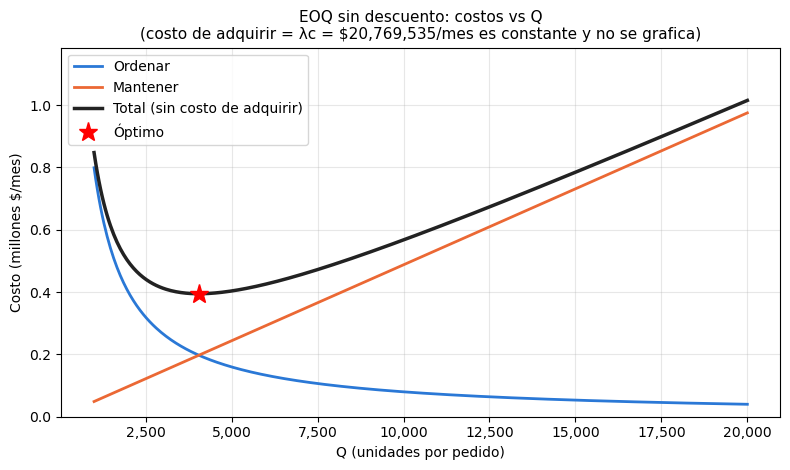

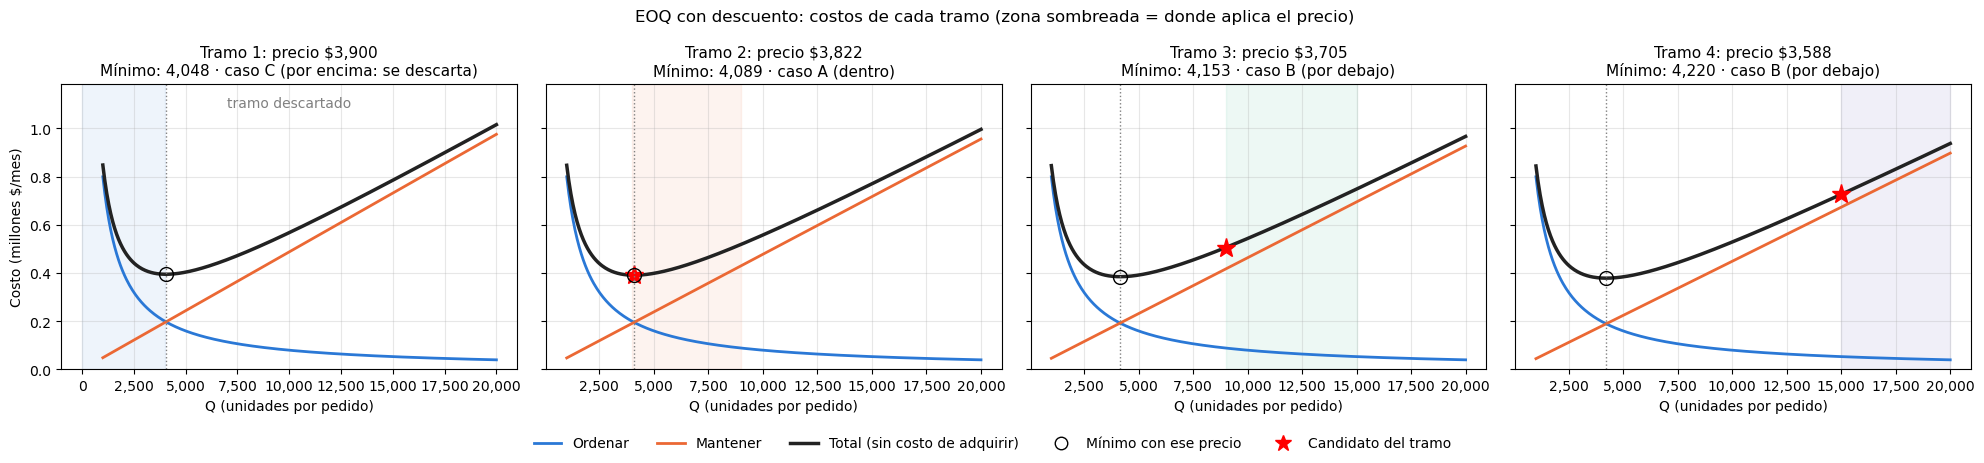

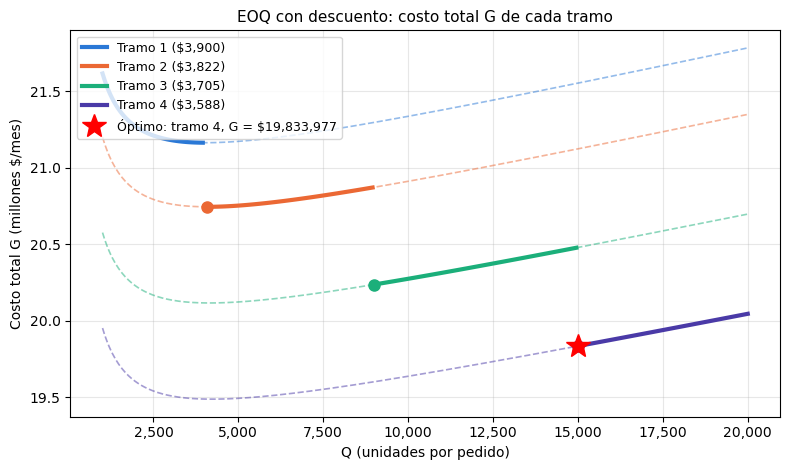

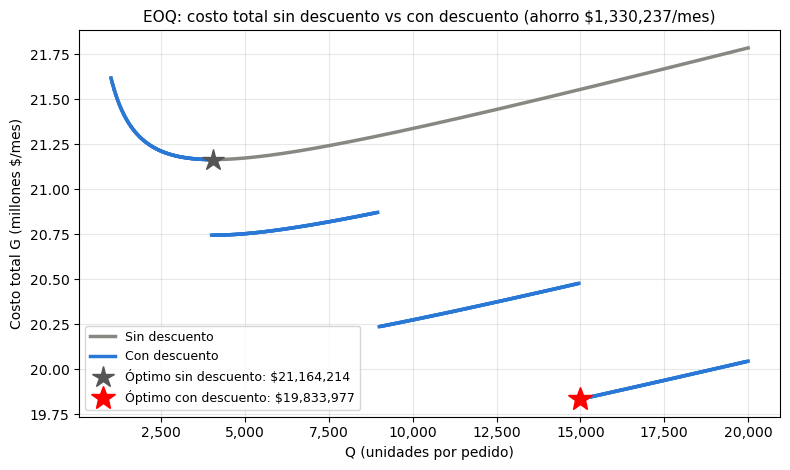

In [28]:
_, candidatos_eoq_raw = resolver_eoq_con_desc_devuelve_mejor_y_candidatos(datos["demanda"], datos["costo_pedido"], tramos_empresa,   # candidatos de cada tramo (el ganador no se necesita aquí)
                                           datos["tasa_manejo"], datos["lead_time"])   # candidatos de cada tramo (el ganador no se necesita aquí)
candidatos_eoq = [None if c["q_candidato"] is None else (c["tramo"], c["q_candidato"], c["costo"])   # pasa los candidatos a formato (tramo, Q, G), o None si el tramo se descartó
                  for c in candidatos_eoq_raw]                   # los pasa a formato (tramo, Q, G), o None si el tramo se descartó
graficas_de_costo("EOQ", "EOQ", np.linspace(1000, 20000, 400), datos, tramos_empresa,   # hace las 4 gráficas del modelo
                  (q_eoq, g_eoq), candidatos_eoq,
                  [c["q_tramo"] for c in candidatos_eoq_raw], [c["caso"] for c in candidatos_eoq_raw])   # el mínimo de cada tramo y su caso                # hace las 4 gráficas con 400 valores de Q entre 1,000 y 20,000

**(Q,R)**

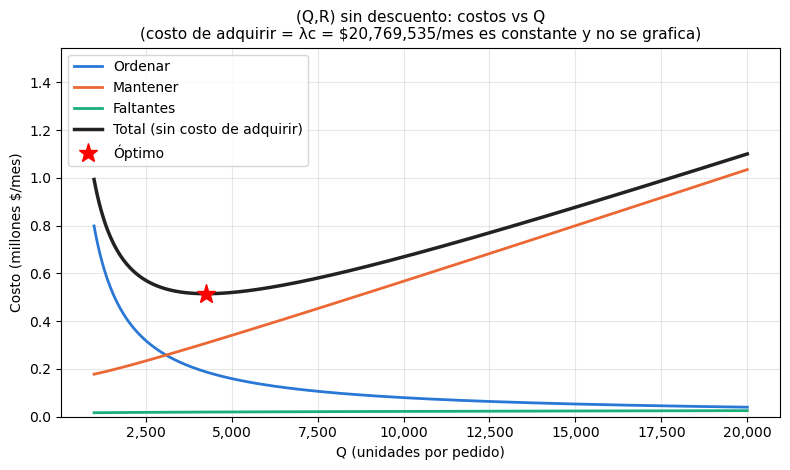

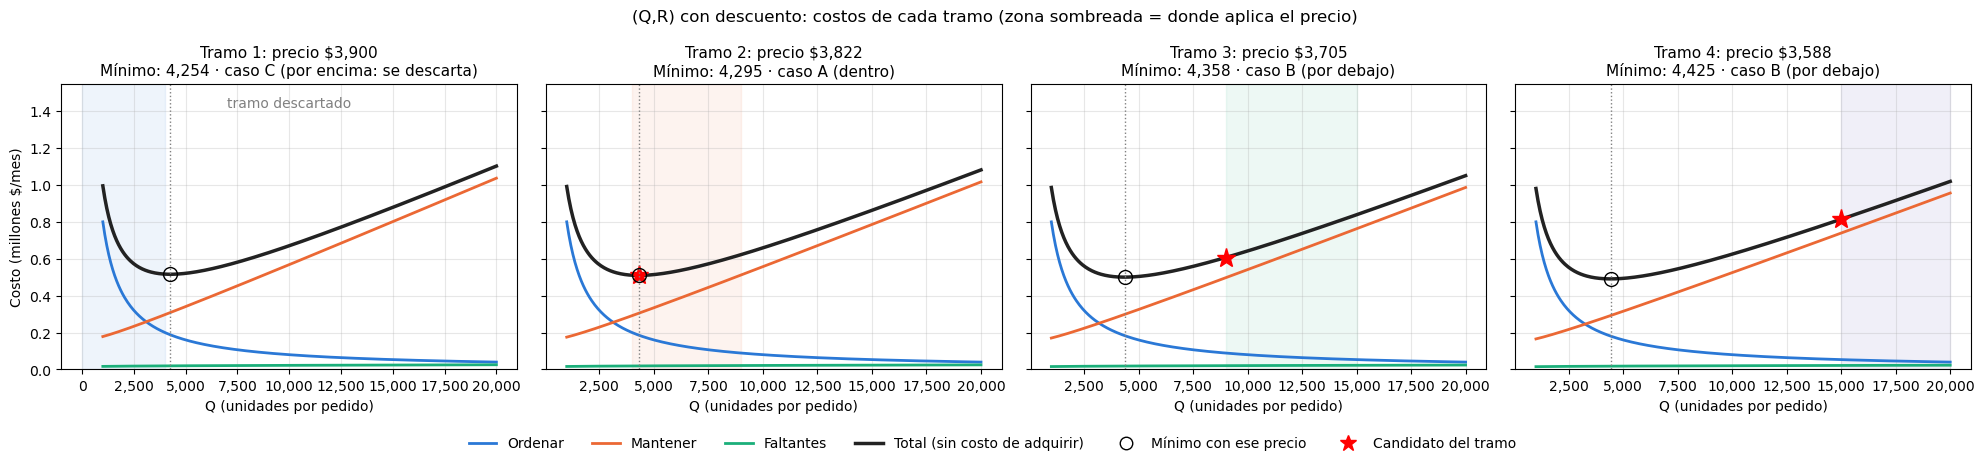

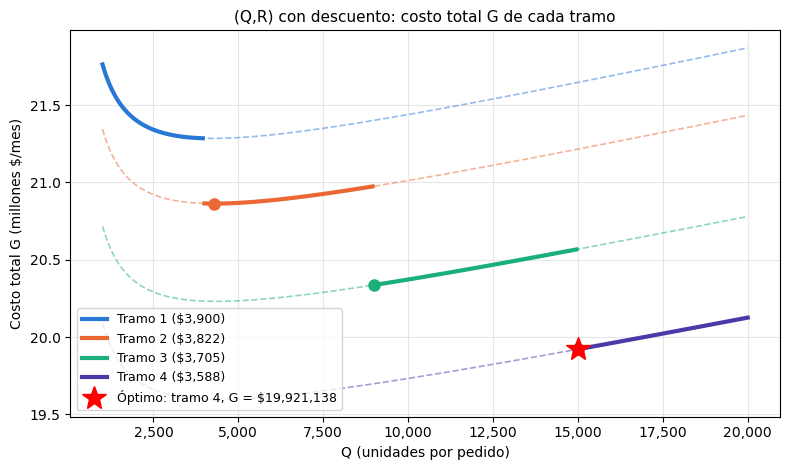

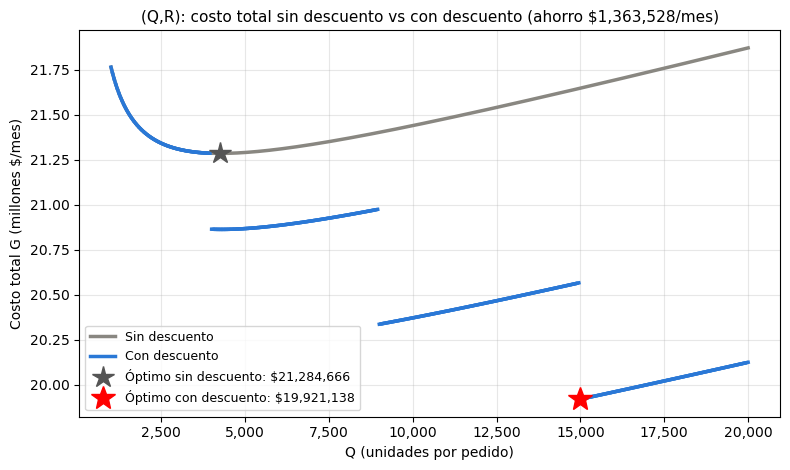

In [29]:
_, candidatos_qr_raw = resolver_qr_con_desc_devuelve_mejor_y_candidatos(tramos=tramos_empresa, **datos_sin_precio)   # candidatos de cada tramo
candidatos_qr = [None if c["solucion"] is None   # pasa los candidatos a formato (tramo, Q, G), o None si el tramo se descartó
                 else (c["tramo"], c["solucion"]["Q"], c["solucion"]["costos"]["total"])   # si no, (tramo, valor del candidato, costo total)
                 for c in candidatos_qr_raw]                     # los pasa a formato (tramo, Q, G), o None si el tramo se descartó
graficas_de_costo("QR", "(Q,R)", np.linspace(1000, 20000, 400), datos, tramos_empresa,   # hace las 4 gráficas del modelo
                  (sol_qr_sin_desc["Q"], sol_qr_sin_desc["costos"]["total"]), candidatos_qr,
                  [c["q_tramo"] for c in candidatos_qr_raw], [c["caso"] for c in candidatos_qr_raw])   # el mínimo de cada tramo y su caso   # hace las 4 gráficas

**(S,T)**

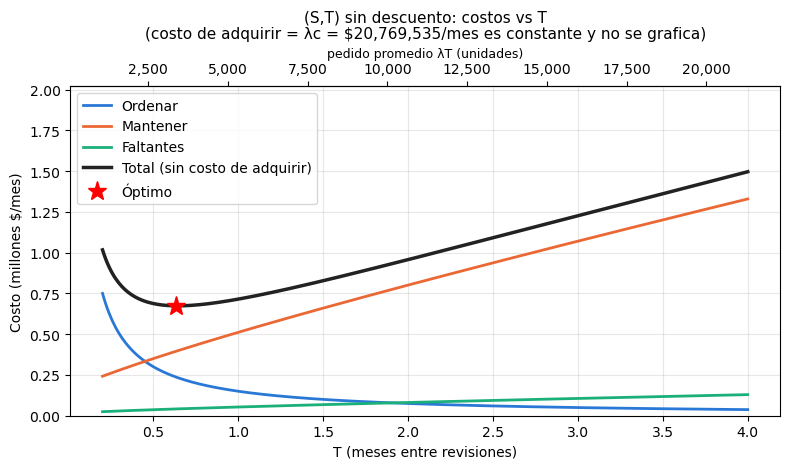

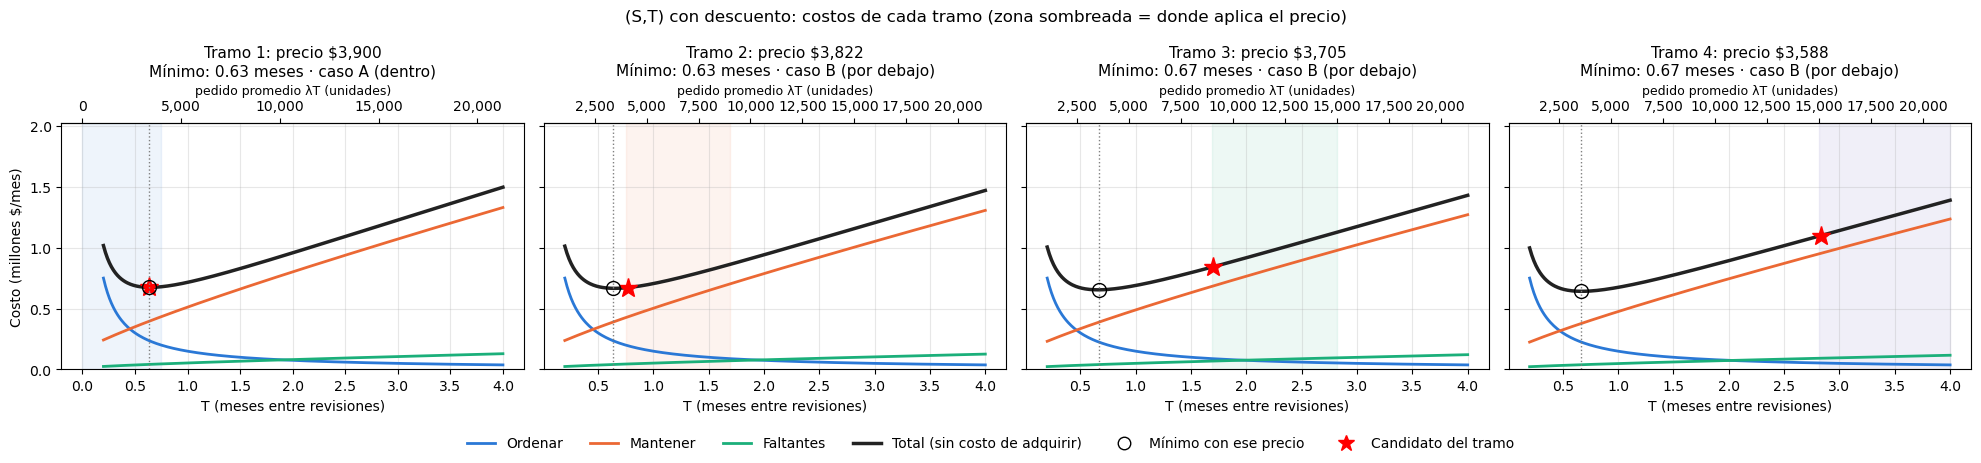

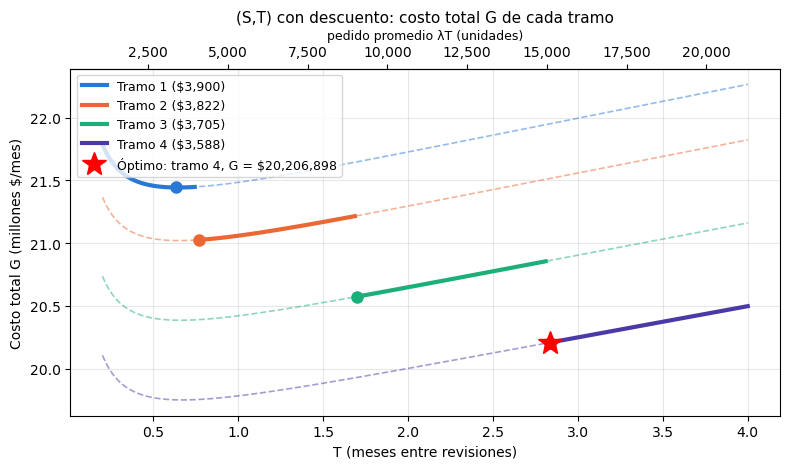

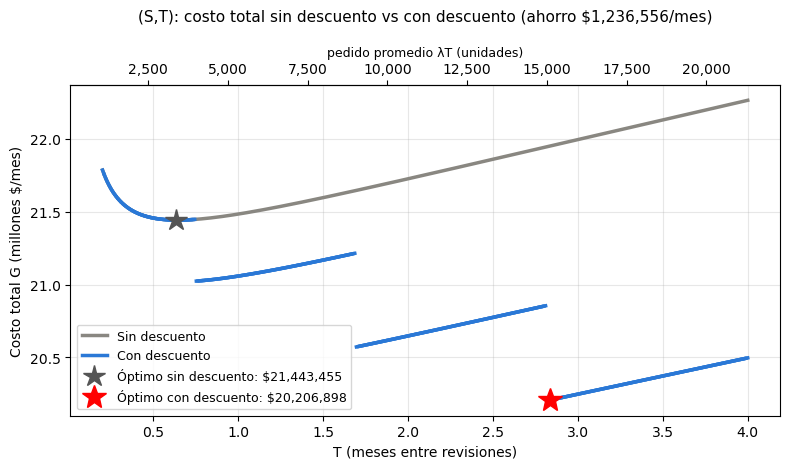

In [30]:
_, candidatos_st_raw = resolver_st_con_desc_devuelve_mejor_y_candidatos(tramos=tramos_empresa, **datos_sin_precio, paso=1/30)   # candidatos de cada tramo
candidatos_st = [None if c["solucion"] is None   # pasa los candidatos a formato (tramo, T, G), o None si el tramo se descartó
                 else (c["tramo"], c["solucion"]["T"], c["solucion"]["costos"]["total"])   # si no, (tramo, valor del candidato, costo total)
                 for c in candidatos_st_raw]                     # los pasa a formato (tramo, T, G), o None si el tramo se descartó
graficas_de_costo("ST", "(S,T)", np.linspace(0.2, 4.0, 400), datos, tramos_empresa,   # hace las 4 gráficas del modelo
                  (sol_st_sin_desc["T"], sol_st_sin_desc["costos"]["total"]), candidatos_st,
                  [c["t_tramo"] for c in candidatos_st_raw], [c["caso"] for c in candidatos_st_raw])   # el mínimo de cada tramo y su caso   # hace las 4 gráficas (el eje x es T, entre 0.2 y 4 meses)

**Superficies 3D por tramo (con descuento).** Una sola gráfica por modelo con un pedazo de superficie por tramo, cada uno de su color y dibujado solo donde aplica su precio. Se ve como una **escalera**: cada tramo más abajo que el anterior por el descuento, con saltos en los quiebres. El punto rojo es el óptimo. Como en el (S,T) sin descuento, cada pedazo es una franja alrededor del mejor $R$ (o $S$) de cada valor del eje.

`plot_surface(..., color=...)` pinta toda la superficie de un solo color; `Line2D` arma las entradas de la leyenda a mano porque las superficies 3D no las crean solas.

#### ¿Hasta dónde se grafica cada pedazo?

Cada superficie tiene tres ejes y cada uno se limita por una razón distinta.

**1. El eje del pedido ($Q$ en (Q,R), $T$ en (S,T)) lo limita el tramo.** El precio $c_j$ solo vale si el pedido está en $[Q_{j-1},Q_j)$, así que cada pedazo se dibuja solo en ese rango.
- En (Q,R) el eje es $Q$ y el rango es el del tramo: el tramo 2 va de 4,000 a 8,999 unidades.
- En (S,T) el eje es $T$ y el pedido promedio es $\lambda T$. Entonces $\lambda T\in[Q_{j-1},Q_j)$ equivale a $T\in[Q_{j-1}/\lambda,\ Q_j/\lambda)$. Con $\lambda=5{,}325.52$: el tramo 2 va de $4{,}000/5{,}325.52=0.751$ a $9{,}000/5{,}325.52=1.690$ meses.
- Por eso cada pedazo empieza justo donde termina el anterior: el quiebre de precio es el borde.
- Hay dos bordes que **no** vienen de un quiebre sino del dibujo, porque sin ellos el primer tramo llegaría hasta 0 y el último hasta $\infty$. En (Q,R) el piso es 1,000 unidades y el techo 20,000 (la capacidad de la bodega). En (S,T) el piso es $T=0.3$ meses y el techo $T=4$ meses (unas 21,300 unidades); son solo límites del dibujo.

**2. El eje del nivel de protección ($R$ en (Q,R), $S$ en (S,T)) no lo limita el tramo, lo limita una franja.** El precio no depende de $R$ ni de $S$, así que cualquier valor sería válido. Pero para cada valor del primer eje solo hay un $R$ (o $S$) bueno, el que sale de $F=1-Qh/(p\lambda)$ (o $F=1-hT/p$). Lejos de ese valor los faltantes (si $R$ o $S$ queda corto) o el inventario (si queda largo) disparan el costo y taparían el valle. Por eso, para cada $Q$ (o $T$) se calcula su mejor $R$ (o $S$) y se dibuja una franja alrededor:
- en (Q,R): $\pm2$ desviaciones, es decir $\pm2\sigma_\tau$ (unas 1,059 unidades), alrededor del mejor $R$;
- en (S,T): $\pm2$ desviaciones, es decir $\pm2\sigma_{T+\tau}$, alrededor del mejor $S$.

Como el mejor $S$ crece con $T$ (hay que cubrir más demanda), la franja sube y cada pedazo se ve inclinado. Con los datos de la empresa:

| Tramo | $T$ graficado (meses) | $S$ graficado (unidades) |
|---|---|---|
| 1 (\$3,900) | 0.30 a 0.74 | 2,783 a 9,748 |
| 2 (\$3,822) | 0.75 a 1.68 | 4,861 a 16,201 |
| 3 (\$3,705) | 1.69 a 2.81 | 9,223 a 23,353 |
| 4 (\$3,588) | 2.82 a 3.99 | 14,492 a 30,542 |

**3. El eje vertical $G$ no se limita:** es el resultado, la altura de la superficie en cada punto $(T,S)$ o $(Q,R)$.

En resumen: el **primer eje** se corta donde cambia el precio, el **segundo eje** es una ventana alrededor del mejor valor, y $G$ es lo que sale de evaluar el costo en cada punto. Cada pedazo es una parte de la superficie de $G$ de su propio precio, no toda la superficie.

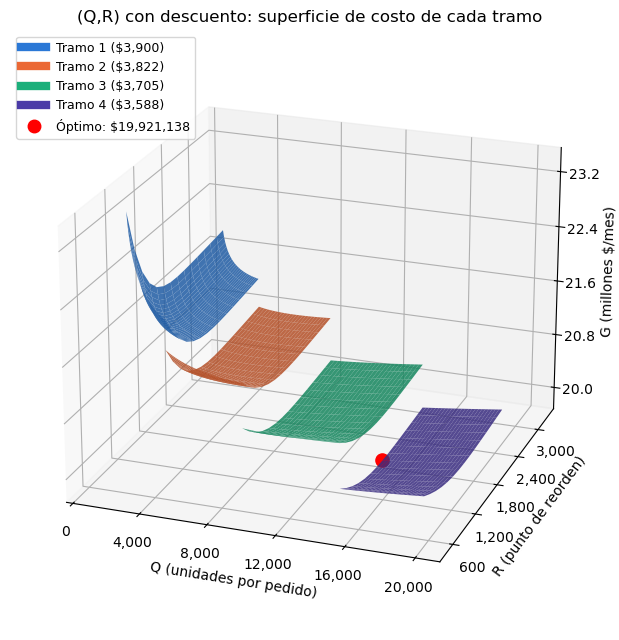

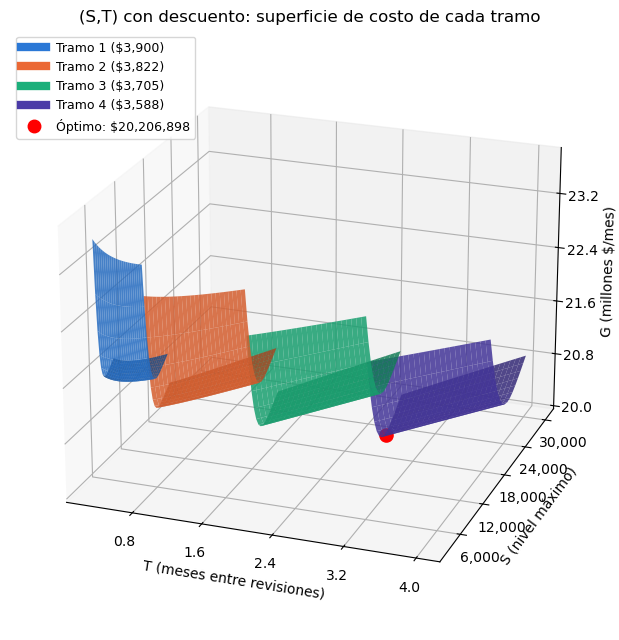

In [31]:
# --- Superficies 3D por tramo (con descuento) ---
# Cada tramo se dibuja solo en el rango donde aplica su precio, con su color.
# Así se ve la "escalera": cada tramo más abajo que el anterior, con saltos en los quiebres.
def grafica_tramos_3d(modelo, solucion, nombre_archivo, titulo): # una gráfica 3D con un pedazo de superficie por tramo
    figura = plt.figure(figsize=(9, 6.5))                        # crea la figura
    ejes = figura.add_subplot(projection="3d")                   # ejes en 3D
    lineas_leyenda = []                                          # entradas de leyenda hechas a mano
    # Cómo se decide hasta dónde se dibuja cada pedazo (un pedazo por tramo de precio):
    #   - Primer eje (Q en (Q,R); T en (S,T)): lo limita el TRAMO. El precio c_j solo vale si el pedido está en [Q_{j-1}, Q_j),
    #     así que el pedazo va exactamente de un quiebre al siguiente (en (S,T) los quiebres se pasan a T dividiendo por lambda).
    #     Solo el primer y el último tramo se cortan por el dibujo: en (Q,R) con piso 1,000 y techo 20,000 (capacidad); en (S,T) con piso T = 0.3 y techo T = 4 meses.
    #   - Segundo eje (R en (Q,R); S en (S,T)): NO lo limita el tramo. Para cada valor del primer eje se calcula su mejor R (o S)
    #     y se dibuja una franja alrededor (±2 desviaciones en (Q,R) y en (S,T)), porque lejos del mejor valor
    #     los faltantes o el inventario disparan el costo y taparían el valle.
    #   - Eje vertical (G): no se limita; es el costo calculado en cada punto.
    for j in range(len(tramos_empresa)):                         # para cada tramo
        precio = tramos_empresa[j][1]                            # precio del tramo
        desde, hasta = rango_tramo_en_x_devuelve_desde_y_hasta(modelo, j, tramos_empresa, datos_empresa["demanda"])   # límites del tramo en el eje x: en (Q,R) son Q_{j-1} y Q_j; en (S,T) son Q_{j-1}/lambda y Q_j/lambda (en meses)
        if modelo == "QR":                                       # superficie del (Q,R)
            x = np.linspace(max(desde, 1000), min(hasta, 20000) - 1, 25)   # eje Q: 25 valores desde el inicio del tramo hasta justo antes del siguiente (piso 1,000, techo 20,000 = capacidad)
            X, Y, G = superficie_qr_devuelve_matrices_Q_R_G(datos_empresa, precio, x, np.linspace(-2, 2, 15))   # eje R: franja de ±2 desviaciones alrededor del mejor R de cada Q; G se calcula en cada punto
        else:                                                    # superficie del (S,T)
            x = np.linspace(max(desde, 0.3), min(hasta, 4.0) - 0.01, 25)   # eje T: 25 valores desde el inicio del tramo hasta justo antes del siguiente (piso 0.3 y techo 4 meses solo por el dibujo)
            X, Y, G = superficie_st_devuelve_matrices_T_S_G(datos_empresa, precio, x, np.linspace(-2, 2, 15))   # eje S: franja de ±2 desviaciones alrededor del mejor S de cada T; G se calcula en cada punto
        ejes.plot_surface(X, Y, G, color=COLOR_TRAMO[j], alpha=0.85, edgecolor="none")   # pedazo de superficie del tramo, de su color
        lineas_leyenda.append(Line2D([], [], color=COLOR_TRAMO[j], linewidth=6))          # entrada de leyenda del tramo
    if modelo == "QR":                                           # coordenadas del óptimo según el modelo
        x_opt, y_opt = solucion["Q"], solucion["R"]   # coordenadas del óptimo en los ejes de esta gráfica
    else:   # en cualquier otro caso
        x_opt, y_opt = solucion["T"], solucion["S"]   # coordenadas del óptimo en los ejes de esta gráfica
    g_opt = solucion["costos"]["total"] / 1e6                    # costo del óptimo, en millones
    ejes.scatter(x_opt, y_opt, g_opt, color="red", s=90, depthshade=False)   # punto rojo en el óptimo
    lineas_leyenda.append(Line2D([], [], marker="o", color="red", linestyle="none", markersize=9))   # entrada de leyenda del óptimo
    nombres = [f"Tramo {j + 1} ({pesos(tramos_empresa[j][1])})" for j in range(len(tramos_empresa))]   # nombre de cada tramo
    ejes.legend(lineas_leyenda, nombres + [f"Óptimo: {pesos(solucion['costos']['total'])}"], loc="upper left", fontsize=9)   # leyenda
    if modelo == "QR":                                           # títulos de los ejes según el modelo
        ejes.set_xlabel("Q (unidades por pedido)")   # título del eje x
        ejes.set_ylabel("R (punto de reorden)")   # título del eje y
    else:   # en cualquier otro caso
        ejes.set_xlabel("T (meses entre revisiones)")   # título del eje x
        ejes.set_ylabel("S (nivel máximo)")   # título del eje y
    ejes.set_zlabel("G (millones $/mes)")                        # título del eje z
    ejes.set_title(titulo)                                       # título de la gráfica
    ejes.view_init(elev=22, azim=-70)                            # ángulo de la cámara
    poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
    plt.tight_layout()                                           # ajusta márgenes
    plt.savefig(carpeta_graficas / nombre_archivo, dpi=200)      # guarda la imagen
    plt.show()                                                   # muestra la gráfica


grafica_tramos_3d("QR", sol_qr_con_desc, "qr_superficie_tramos.png", "(Q,R) con descuento: superficie de costo de cada tramo")   # superficie por tramo del (Q,R)
grafica_tramos_3d("ST", sol_st_con_desc, "st_superficie_tramos.png", "(S,T) con descuento: superficie de costo de cada tramo")   # superficie por tramo del (S,T)

### 4.4 Comparación entre políticas y con la política actual

**Política actual.** La empresa revisa el inventario todo el tiempo y pide unas 1,500 unidades cuando quedan unas 1,488 (demanda del lead time + 600 de seguridad). Es un (Q,R) con valores fijos, así que su costo se calcula con `costos_qr_devuelve_ordenar_adquirir_mantener_faltantes_total` y su nivel de servicio con $\alpha = \Phi(z)$ y $\beta = 1 - n(R)/Q$. La **política recomendada** es la más barata de las cuatro que consideran faltantes ((Q,R) y (S,T), sin y con descuento). Si gana un (Q,R), encaja con la revisión continua que la empresa ya usa; si gana un (S,T), la empresa tendría que pasar a revisión periódica (revisar el inventario cada $T$).

In [32]:
# -----------------------------------------------------------------------------
# Política actual de la empresa
# Revisan el inventario todo el tiempo y piden ~1,500 unidades cuando quedan
# ~1,488 (demanda del lead time + 600 de seguridad): es un (Q,R) con valores fijos.
# -----------------------------------------------------------------------------
q_actual = 1500                 # dato aproximado de la empresa: cantidad que piden
inventario_seguridad_actual = 600   # inventario de seguridad que mantienen
media_lead, desviacion_lead = demanda_horizonte_devuelve_media_y_desviacion(datos["demanda"], datos["desviacion"], datos["lead_time"])   # mu_tau y sigma_tau
r_actual = media_lead + inventario_seguridad_actual             # R = demanda del lead time + inventario de seguridad
h_lista = h_costo_mantener_una_unidad(datos["tasa_manejo"], datos["costo_unitario"])   # h con el precio de lista

faltantes_actual = faltantes_esperados_n_por_ciclo(r_actual, media_lead, desviacion_lead)   # n(R) de la política actual
politica_actual = {                                             # mismo formato que las soluciones de los modelos
    "Q": q_actual,   # cantidad que se pide hoy
    "R": r_actual,   # punto de reorden de hoy
    "precio": datos["costo_unitario"],   # precio sin descuento
    "alfa": norm.cdf((r_actual - media_lead) / desviacion_lead),   # F(R) = Phi(z): probabilidad de no quedarse sin inventario
    "beta": 1 - faltantes_actual / q_actual,                    # nivel de servicio tipo 2 = 1 - n(R)/Q
    "costos": costos_qr_devuelve_ordenar_adquirir_mantener_faltantes_total(q_actual, r_actual, datos["demanda"], datos["costo_pedido"],   # costos de esa política, con la misma función de los modelos
                        datos["costo_unitario"], h_lista, datos["costo_faltante"],
                        media_lead, desviacion_lead),           # costos de esa política, con la misma función de costo de los modelos
}   # fin del diccionario


def decision_de_politica_devuelve_texto(sol):                            # texto con la decisión de una política, para títulos y leyendas
    """(Q,R): 'Q = 15,000, R = 1,617'.   (S,T): 'T = 85 días, S = 19,064'."""
    if "R" in sol:                                                       # (Q,R): cantidad a pedir y punto de reorden
        return f"Q = {miles(sol['Q'])}, R = {miles(sol['R'])}"          # texto del (Q,R)
    return f"T = {miles(sol['T'] * 30)} días, S = {miles(sol['S'])}"    # (S,T): periodo en días (1 mes = 30 días) y nivel máximo


# La política recomendada es la más barata de las cuatro que consideran faltantes ((Q,R) y (S,T), sin y con descuento).
# El EOQ no entra porque no tiene faltantes ni incertidumbre, así que su costo no es comparable.
candidatas = {"(Q,R) sin descuento": sol_qr_sin_desc, "(Q,R) con descuento": sol_qr_con_desc,   # las cuatro políticas que consideran faltantes
              "(S,T) sin descuento": sol_st_sin_desc, "(S,T) con descuento": sol_st_con_desc}   # nombre: solución
nombre_recomendada = min(candidatas, key=lambda nombre: candidatas[nombre]["costos"]["total"])   # el nombre de la de menor costo total
recomendada = candidatas[nombre_recomendada]                             # su solución, para usarla en las comparaciones
recomendada_es_qr = "R" in recomendada                                   # True si es un (Q,R): revisión continua, como la empresa hoy

print(f"Actual:      Q = {miles(q_actual)}  R = {miles(r_actual)}  G = {pesos(politica_actual['costos']['total'])}"   # imprime la política actual
      f"  alfa = {miles(politica_actual['alfa'], 3)}")
print(f"Recomendada ({nombre_recomendada}): {decision_de_politica_devuelve_texto(recomendada)}  G = {pesos(recomendada['costos']['total'])}"   # imprime la política recomendada
      f"  alfa = {miles(recomendada['alfa'], 3)}")

Actual:      Q = 1,500  R = 1,488  G = $21,796,127  alfa = 0.871
Recomendada ((Q,R) con descuento): Q = 15,000, R = 1,617  G = $19,921,138  alfa = 0.916


**Comparación de las 6 políticas.** Dos gráficas:
- Barras con los costos de cada política: a la izquierda los costos que dependen de la decisión (ordenar, mantener, faltantes), apilados; a la derecha el costo total, que incluye el costo de adquirir. `barh` hace barras horizontales y `left=` indica dónde empieza cada pedazo para apilarlos.
- Costo total contra el nivel de servicio $\alpha$ que resulta de cada política. El EOQ no aparece porque no tiene faltantes.

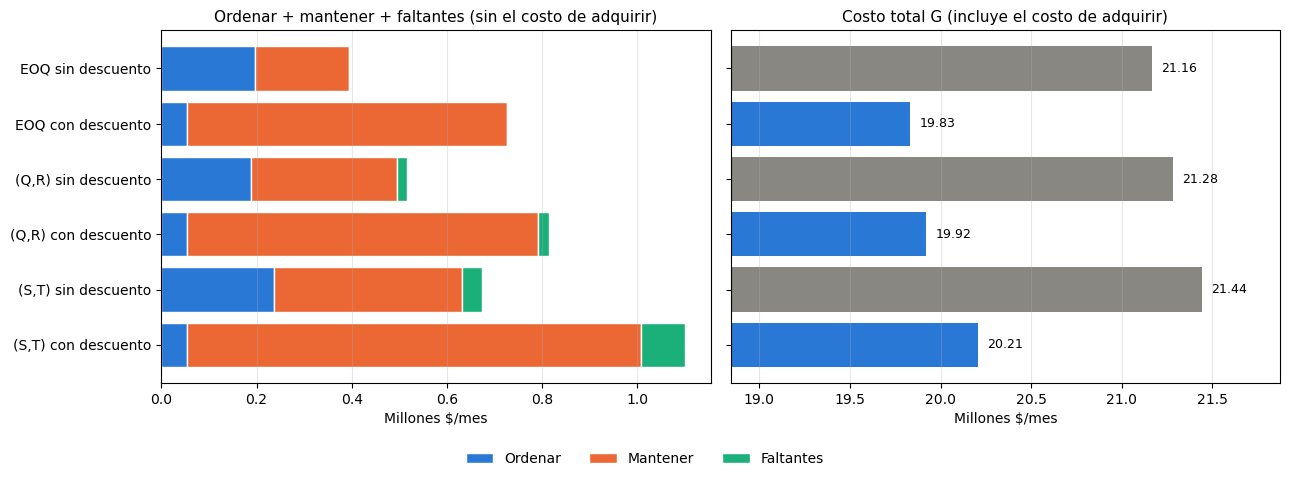

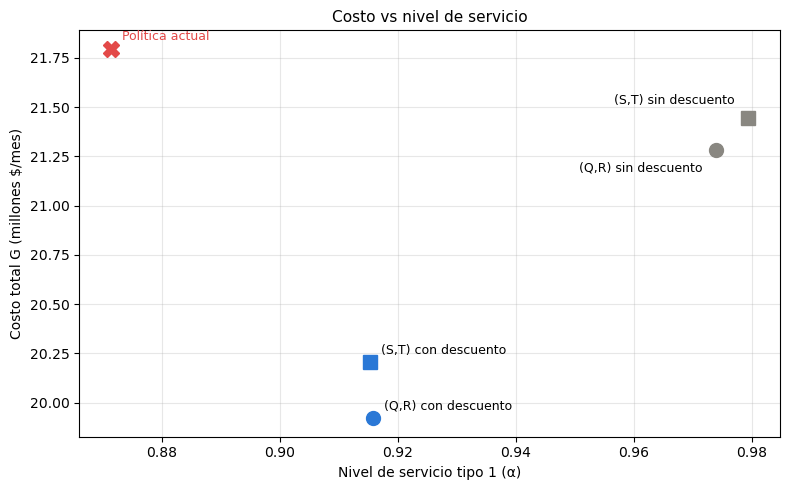

In [33]:
# --- Costos de las 6 políticas ---
politicas = [   # (nombre, costos, alfa)
    ("EOQ sin descuento",   # nombre, costos desglosados y alfa (None: el EOQ no tiene faltantes)
     costos_eoq_devuelve_ordenar_adquirir_mantener_total(q_eoq, datos["demanda"], datos["costo_pedido"], datos["costo_unitario"], h_lista), None),   # el EOQ no tiene alfa (no hay faltantes)
    ("EOQ con descuento",   # nombre, costos desglosados y alfa (None: el EOQ no tiene faltantes)
     costos_eoq_devuelve_ordenar_adquirir_mantener_total(sol_eoq_con_desc["Q"], datos["demanda"], datos["costo_pedido"], sol_eoq_con_desc["precio"],   # costos del EOQ con el precio del tramo ganador
                h_costo_mantener_una_unidad(datos["tasa_manejo"], sol_eoq_con_desc["precio"])), None),   # h con el precio del tramo ganador
    ("(Q,R) sin descuento", sol_qr_sin_desc["costos"], sol_qr_sin_desc["alfa"]),   # nombre, costos desglosados y alfa
    ("(Q,R) con descuento", sol_qr_con_desc["costos"], sol_qr_con_desc["alfa"]),   # nombre, costos desglosados y alfa
    ("(S,T) sin descuento", sol_st_sin_desc["costos"], sol_st_sin_desc["alfa"]),   # nombre, costos desglosados y alfa
    ("(S,T) con descuento", sol_st_con_desc["costos"], sol_st_con_desc["alfa"]),   # nombre, costos desglosados y alfa
]   # fin de la lista
nombres = [p[0] for p in politicas]                  # lista con los nombres de las políticas
posiciones = np.arange(len(politicas))               # 0, 1, 2, ..., 5: la posición de cada barra

figura, (eje1, eje2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)   # dos gráficas lado a lado
izquierda = np.zeros(len(politicas))           # donde empieza cada barra (para apilar)
for componente in ["ordenar", "mantener", "faltantes"]:                     # un pedazo de barra por cada costo
    valores = np.array([p[1][componente] / 1e6 for p in politicas])         # ese costo en cada política, en millones
    eje1.barh(posiciones, valores, left=izquierda, color=COLOR_COSTO[componente],   # barras horizontales; left= indica dónde empieza cada pedazo
              label=NOMBRE_COSTO[componente], edgecolor="white")            # barras horizontales; left= indica dónde empieza cada una
    izquierda += valores                                                    # el siguiente pedazo empieza donde termina este
eje1.set_yticks(posiciones, nombres)                 # pone los nombres de las políticas en el eje y
eje1.invert_yaxis()                            # la primera política arriba
eje1.set_xlabel("Millones $/mes")                    # título del eje x
eje1.set_title("Ordenar + mantener + faltantes (sin el costo de adquirir)", fontsize=11)   # título
eje1.grid(axis="x", alpha=0.3)                       # cuadrícula vertical suave

totales = np.array([p[1]["total"] / 1e6 for p in politicas])                # costo total de cada política, en millones
colores = ["#898781" if "sin" in n else "#2a78d6" for n in nombres]         # gris si es sin descuento, azul si es con descuento
eje2.barh(posiciones, totales, color=colores)        # una barra por política
for y, valor in zip(posiciones, totales):            # escribe el valor al lado de cada barra
    eje2.text(valor + 0.05, y, f"{miles(valor, 2)}", va="center", fontsize=9)   # escribe el valor al lado de cada barra
eje2.set_xlim(totales.min() * 0.95, totales.max() * 1.02)    # empezar cerca del mínimo para ver diferencias
eje2.set_xlabel("Millones $/mes")                    # título del eje x
eje2.set_title("Costo total G (incluye el costo de adquirir)", fontsize=11)   # título
eje2.grid(axis="x", alpha=0.3)                       # cuadrícula vertical suave
poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
poner_leyenda_abajo(figura, eje1)                    # una sola leyenda abajo
plt.savefig(carpeta_graficas / "comparacion_costos.png", dpi=200)   # guarda la imagen
plt.show()                                           # muestra la gráfica

# --- Costo vs nivel de servicio ---
figura, eje = plt.subplots(figsize=(8, 5))           # crea la figura
puntos = [("(Q,R) sin descuento", sol_qr_sin_desc, (-10, -16)), ("(Q,R) con descuento", sol_qr_con_desc, (8, 6)),   # (nombre, solución, desplazamiento de la etiqueta) de cada política
          ("(S,T) sin descuento", sol_st_sin_desc, (-10, 10)), ("(S,T) con descuento", sol_st_con_desc, (8, 6))]   # nombre, costos desglosados y alfa
# el tercer valor es dónde poner el texto respecto al punto, para que no se monten las etiquetas
for nombre, sol, desplazamiento in puntos:           # un punto por política
    color = "#898781" if "sin" in nombre else "#2a78d6"          # gris sin descuento, azul con descuento
    marcador = "o" if "(Q,R)" in nombre else "s"                 # círculo para (Q,R), cuadrado para (S,T)
    eje.plot(sol["alfa"], sol["costos"]["total"] / 1e6, marcador, color=color, markersize=10)   # el punto: (alfa, costo)
    eje.annotate(nombre, (sol["alfa"], sol["costos"]["total"] / 1e6), textcoords="offset points",   # etiqueta junto al punto
                 xytext=desplazamiento, fontsize=9, ha="right" if desplazamiento[0] < 0 else "left")   # etiqueta junto al punto
eje.plot(politica_actual["alfa"], politica_actual["costos"]["total"] / 1e6, "X", color="#e34948", markersize=12)   # la política actual (X roja)
eje.annotate("Política actual", (politica_actual["alfa"], politica_actual["costos"]["total"] / 1e6),   # etiqueta junto al punto
             textcoords="offset points", xytext=(8, 6), fontsize=9, color="#e34948")   # su etiqueta
eje.set_xlabel("Nivel de servicio tipo 1 (α)")       # título del eje x
eje.set_ylabel("Costo total G (millones $/mes)")     # título del eje y
eje.set_title("Costo vs nivel de servicio", fontsize=11)   # título
eje.grid(alpha=0.3)                                  # cuadrícula suave
poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
plt.tight_layout()                                   # ajusta márgenes
plt.savefig(carpeta_graficas / "costo_vs_servicio.png", dpi=200)   # guarda la imagen
plt.show()                                           # muestra la gráfica

**Política actual frente a la recomendada.** Tres gráficas:
- La política actual como un punto sobre las curvas de costo del (Q,R), para ver qué tan lejos está del óptimo. Las curvas usan el mejor $R$ de cada $Q$; por eso se marca también el mismo $Q$ con su mejor $R$ (círculo vacío) y la diferencia de costo por usar otro $R$. La estrella roja de la recomendada solo aparece si la recomendada es un (Q,R).
- Barras de costos y de nivel de servicio, actual frente a recomendada (`bar_label` escribe el valor encima de cada barra).
- El serrucho de las dos, con la demanda media (si la recomendada fuera un (S,T), se dibuja con sus revisiones cada $T$).

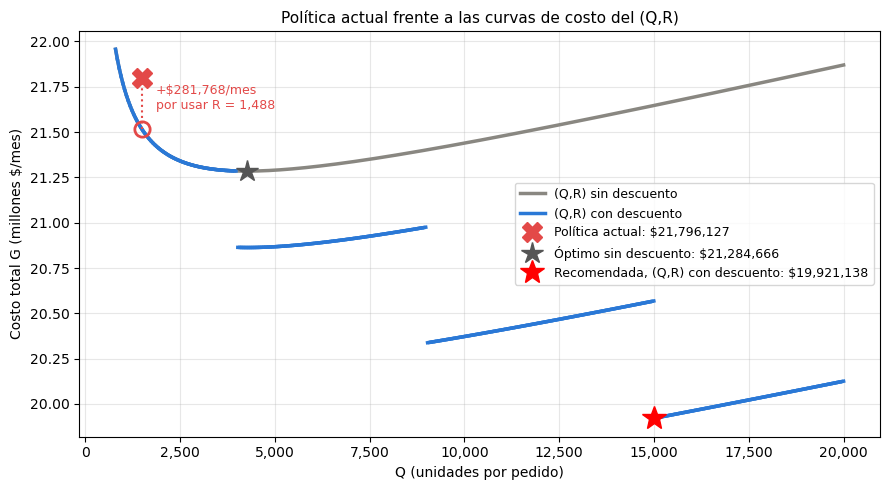

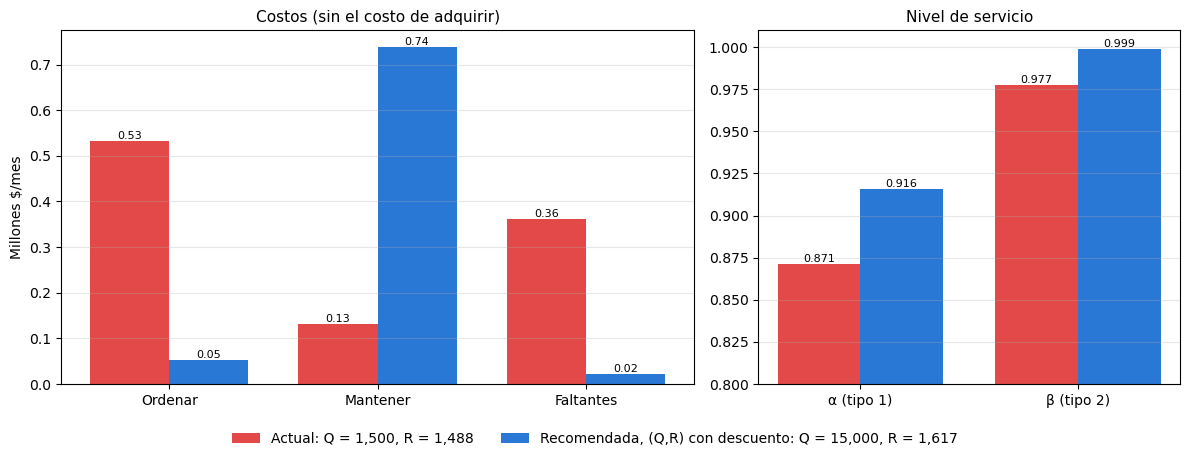

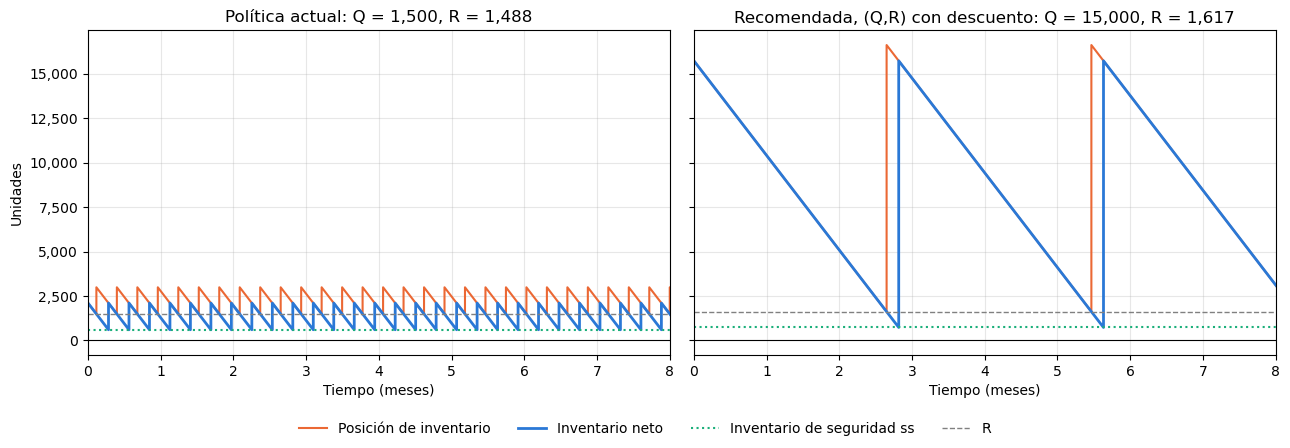

In [34]:
# --- Dónde está la empresa hoy: punto actual sobre las curvas de costo del (Q,R) ---
valores_q = np.linspace(800, 20000, 400)             # 400 valores de Q entre 800 y 20,000
curva_sin = curva_costos_devuelve_listas_en_millones("QR", valores_q, datos["costo_unitario"], datos)   # costos del (Q,R) con el precio de lista
figura, eje = plt.subplots(figsize=(9, 5))           # crea la figura
eje.plot(curva_sin["x"], curva_sin["total"], color="#898781", linewidth=2.5, label="(Q,R) sin descuento")   # curva sin descuento (gris)
dibujar_curva_con_descuento(eje, "QR", valores_q, tramos_empresa, datos, "(Q,R) con descuento")   # curva con descuento (azul, con saltos en los quiebres)
g_curva = costos_en_punto_devuelve_diccionario_o_None("QR", q_actual, datos["costo_unitario"], datos)["total"]   # costo sobre la curva en el Q actual (con el mejor R)
g_hoy = politica_actual["costos"]["total"]                       # costo de la política actual (con su R)
eje.plot([q_actual, q_actual], [g_curva / 1e6, g_hoy / 1e6], color="#e34948", linestyle=":", linewidth=1.5)   # línea punteada: la diferencia entre usar el mejor R y el R actual
eje.plot(q_actual, g_curva / 1e6, "o", markerfacecolor="none", markeredgecolor="#e34948", markeredgewidth=2, markersize=11)   # círculo vacío sobre la curva: el mismo Q con su mejor R (sin entrada en la leyenda)
eje.plot(q_actual, g_hoy / 1e6, "X", color="#e34948", markersize=14,
         label=f"Política actual: {pesos(g_hoy)}")   # X roja: la política actual
eje.annotate(f"+{pesos(g_hoy - g_curva)}/mes\npor usar R = {miles(r_actual)}", (q_actual, (g_curva + g_hoy) / 2 / 1e6),   # cuánto cuesta de más usar el R actual
             textcoords="offset points", xytext=(10, -4), fontsize=9, color="#e34948")   # texto a la derecha de la línea punteada
eje.plot(sol_qr_sin_desc["Q"], sol_qr_sin_desc["costos"]["total"] / 1e6, "*", color="#555555", markersize=16,
         label=f"Óptimo sin descuento: {pesos(sol_qr_sin_desc['costos']['total'])}")       # estrella gris: óptimo sin descuento
if recomendada_es_qr:                                # la estrella de la recomendada solo va si es un (Q,R) (estas curvas son del (Q,R))
    eje.plot(recomendada["Q"], recomendada["costos"]["total"] / 1e6, "*", color="red", markersize=18,   # estrella roja: la política recomendada
             label=f"Recomendada, {nombre_recomendada}: {pesos(recomendada['costos']['total'])}")   # estrella roja: la recomendada
eje.set_xlabel("Q (unidades por pedido)")            # título del eje x
eje.set_ylabel("Costo total G (millones $/mes)")     # título del eje y
eje.set_title("Política actual frente a las curvas de costo del (Q,R)", fontsize=11)   # título
eje.grid(alpha=0.3)                                  # cuadrícula suave
eje.legend(fontsize=9)                               # leyenda
poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
plt.tight_layout()                                   # ajusta márgenes
plt.savefig(carpeta_graficas / "actual_en_curva.png", dpi=200)   # guarda la imagen
plt.show()                                           # muestra la gráfica

# --- Actual vs recomendada: costos y nivel de servicio ---
figura, (eje1, eje2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [3, 2]})   # dos gráficas; la izquierda más ancha
componentes = ["ordenar", "mantener", "faltantes"]   # los costos que se comparan (sin el costo de adquirir)
x = np.arange(len(componentes))                      # posición de cada grupo de barras
ancho = 0.38                                         # ancho de cada barra
for desplazamiento, sol, nombre, color in [(-ancho / 2, politica_actual, f"Actual: Q = {miles(q_actual)}, R = {miles(r_actual)}", "#e34948"),   # nombre de la actual, con sus valores
                                           (ancho / 2, recomendada, f"Recomendada, {nombre_recomendada}: {decision_de_politica_devuelve_texto(recomendada)}", "#2a78d6")]:   # nombre de la recomendada: el modelo y sus valores
    valores = [sol["costos"][c] / 1e6 for c in componentes]              # sus costos, en millones
    barras = eje1.bar(x + desplazamiento, valores, ancho, color=color, label=nombre)   # dibuja las barras
    eje1.bar_label(barras, labels=[miles(v, 2) for v in barras.datavalues], fontsize=8)          # escribe el valor encima de cada barra
eje1.set_xticks(x, [NOMBRE_COSTO[c] for c in componentes])  # nombres de los costos en el eje x
eje1.set_ylabel("Millones $/mes")                    # título del eje y
eje1.set_title("Costos (sin el costo de adquirir)", fontsize=11)   # título
eje1.grid(axis="y", alpha=0.3)                       # cuadrícula horizontal suave

niveles = ["α (tipo 1)", "β (tipo 2)"]               # los dos niveles de servicio
x2 = np.arange(len(niveles))                         # posición de cada grupo de barras
for desplazamiento, sol, color in [(-ancho / 2, politica_actual, "#e34948"), (ancho / 2, recomendada, "#2a78d6")]:   # actual y recomendada
    barras = eje2.bar(x2 + desplazamiento, [sol["alfa"], sol["beta"]], ancho, color=color)   # barras de alfa y beta
    eje2.bar_label(barras, labels=[miles(v, 3) for v in barras.datavalues], fontsize=8)   # valor encima de cada barra
eje2.set_xticks(x2, niveles)                         # nombres de los niveles en el eje x
eje2.set_ylim(0.8, 1.01)                             # el eje y va de 0.8 a 1.01 para ver las diferencias
eje2.set_title("Nivel de servicio", fontsize=11)     # título
eje2.grid(axis="y", alpha=0.3)                       # cuadrícula horizontal suave
poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
poner_leyenda_abajo(figura, eje1)                 # una sola leyenda abajo (esta función también ajusta los márgenes)
plt.savefig(carpeta_graficas / "actual_vs_recomendada.png", dpi=200)   # guarda la imagen
plt.show()                                           # muestra la gráfica

# --- Nivel de inventario: actual vs recomendada (serrucho con la demanda media) ---
figura, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)   # 2 gráficas lado a lado
for eje, (titulo, sol) in zip(ejes, [("Política actual", politica_actual), (f"Recomendada, {nombre_recomendada}", recomendada)]):   # (título, solución) de cada una
    texto_titulo = f"{titulo}: {decision_de_politica_devuelve_texto(sol)}"   # título con la decisión de la política
    if "R" in sol:                                   # (Q,R): cuando la posición llega a R se piden Q
        graficar_serrucho_devuelve_momentos_de_pedido(eje, sol["Q"], sol["R"] - media_lead, texto_titulo)   # q = Q, ss = R - mu_tau
        eje.axhline(sol["R"], color="gray", linestyle="--", linewidth=1, label="R")   # línea gris en R
    else:                                            # (S,T): cada T se sube la posición hasta S
        revisiones = graficar_serrucho_devuelve_momentos_de_pedido(eje, datos["demanda"] * sol["T"], sol["ss"], texto_titulo)   # q = lambda*T, ss = S - mu_{T+tau}
        eje.axhline(sol["S"], color="gray", linestyle="--", linewidth=1, label="S")   # línea gris en S
        for revision in revisiones:                  # líneas en cada revisión
            eje.axvline(revision, color="gray", linewidth=0.6, alpha=0.4)   # línea vertical gris suave
ejes[0].set_ylabel("Unidades")                       # título del eje y
poner_coma_de_miles_en_ejes(plt.gcf())   # coma de miles en los números de los ejes (antes de ajustar márgenes)
poner_leyenda_abajo(figura, *ejes)                   # una sola leyenda abajo, con los nombres de las dos gráficas
plt.savefig(carpeta_graficas / "inventario_actual_vs_recomendada.png", dpi=200)   # guarda la imagen
plt.show()                                           # muestra la gráfica

---
## 5. Reporte de resultados (HTML)

Esta celda arma `reporte_resultados.html` (junto al cuaderno), organizado por secciones: datos del caso, EOQ, (Q,R), (S,T), comparación de las 6 políticas, comparación con la política actual y limitaciones. Cada gráfica tiene un subtítulo y un análisis corto que **se escribe con los resultados**, así que si cambian los datos el texto cambia solo. Una gráfica nueva que no esté ubicada en ninguna sección sale al final en "Otras gráficas".

Las imágenes van dentro del mismo HTML (codificadas con `base64`), así que el archivo se puede abrir o enviar solo.

In [35]:
# -----------------------------------------------------------------------------
# Reporte de resultados en HTML, organizado por política.
# Cada gráfica lleva un subtítulo y un análisis corto que se arma con los
# resultados (si cambian los datos, el texto cambia solo).
# -----------------------------------------------------------------------------
# base64 convierte una imagen en texto, para poder meterla dentro del HTML
import base64
# datetime da la fecha y hora actual
from datetime import datetime

# un nombre más corto para los datos de la empresa
d = datos
# función corta: pasa meses a semanas (1 mes = 4 semanas)
mes_a_semanas = lambda t: t * 4          # 1 mes = 4 semanas
# frase que explica cada caso (A, B o C) de los tramos; se usa en los análisis
CASO = {"A": "cae dentro del tramo, así que se usa tal cual",
        "B": "cae por debajo del tramo, así que se pide el mínimo del tramo",
        "C": "cae por encima del tramo, así que el tramo se descarta"}


# arma una tabla HTML a partir de los encabezados y las filas
def tabla_html_devuelve_texto_html(encabezados, filas, clase=""):
    # empieza la tabla: abre el contenedor, la tabla y la fila de encabezados
    html = f'<div class="tabla"><table class="{clase}"><thead><tr>'
    # agrega una celda de encabezado por cada título
    html += "".join(f"<th>{e}</th>" for e in encabezados) + "</tr></thead><tbody>"
    # recorre las filas de datos
    for fila in filas:
        # si la fila empieza con "mejor" se usa como clase CSS (para resaltarla) y se quita de la fila
        clase_fila = fila.pop(0) if fila and fila[0] in ("mejor", "") else ""
        # agrega la fila con una celda por cada valor
        html += f'<tr class="{clase_fila}">' + "".join(f"<td>{celda}</td>" for celda in fila) + "</tr>"
    # cierra la tabla y la devuelve
    return html + "</tbody></table></div>"


# contador de figuras (va en una lista para poder cambiarlo dentro de la función)
numero_figura = [0]
# conjunto con los nombres de las gráficas ya puestas en el reporte
usadas = set()


# arma el bloque de una gráfica: subtítulo, imagen y análisis
def figura_devuelve_bloque_html(archivo, subtitulo, analisis):
    """Bloque de una gráfica: subtítulo arriba, imagen y análisis abajo."""
    # ruta de la imagen dentro de la carpeta de gráficas
    ruta = carpeta_graficas / f"{archivo}.png"
    # si la imagen no existe...
    if not ruta.exists():
        # ...no se pone nada
        return ""
    # se anota que esta gráfica ya se usó
    usadas.add(archivo)
    # se suma 1 al número de figura
    numero_figura[0] += 1
    # se lee la imagen y se convierte a texto base64
    imagen = base64.b64encode(ruta.read_bytes()).decode()
    # devuelve el bloque HTML: título, imagen (incrustada) y análisis
    return (f'<article class="figura"><h3>Figura {numero_figura[0]}. {subtitulo}</h3>'
            f'<img src="data:image/png;base64,{imagen}" alt="{subtitulo}">'
            f'<p class="analisis"><b>Qué muestra:</b> {analisis}</p></article>')


# tabla pequeña de resumen: sin descuento frente a con descuento
def resumen_devuelve_tabla_html(filas):
    # devuelve la tabla de resumen dentro de su contenedor
    return '<div class="resumen">' + tabla_html_devuelve_texto_html(["", "Sin descuento", "Con descuento"], filas) + "</div>"


# describe en una frase lo que pasó en cada tramo
def texto_tramos_devuelve_frase(candidatos_raw, clave_x, unidad):
    # aquí se guarda la frase de cada tramo
    partes = []
    # recorre los tramos
    for c in candidatos_raw:
        # el óptimo del tramo (Q en EOQ y (Q,R); T en (S,T))
        valor = c[clave_x]
        # agrega la frase del tramo: su precio, su óptimo y qué caso fue
        partes.append(f"tramo {c['tramo'] + 1} ({pesos(c['precio'])}): el óptimo del tramo es "
                      f"{miles(valor, 2 if unidad == 'meses' else 0)} {unidad} y {CASO[c['caso']]}")
    # une las frases con punto y coma y termina con un punto
    return "; ".join(partes) + "."


# devuelve el candidato de menor costo (c[2] es el costo)
def ganador_devuelve_candidato_mas_barato(candidatos):
    # ignora los tramos descartados (None) y toma el más barato
    return min((c for c in candidatos if c is not None), key=lambda c: c[2])


# ---------- valores que se usan en los análisis ----------
# ahorro mensual del EOQ al pasar a la versión con descuento
ahorro_eoq = g_eoq - sol_eoq_con_desc["costo"]
# ahorro mensual del (Q,R)
ahorro_qr = sol_qr_sin_desc["costos"]["total"] - sol_qr_con_desc["costos"]["total"]
# ahorro mensual del (S,T)
ahorro_st = sol_st_sin_desc["costos"]["total"] - sol_st_con_desc["costos"]["total"]
# costo mensual de la política actual
g_actual = politica_actual["costos"]["total"]
# ahorro mensual de pasar de la política actual a la recomendada
ahorro_actual = g_actual - recomendada["costos"]["total"]
# cómo se pide con la recomendada, en palabras ((Q,R): se piden Q cuando la posición llega a R; (S,T): cada T se sube la posición hasta S)
como_pedir_recomendada = (f"pedir {miles(recomendada['Q'])} unidades cuando la posición de inventario llegue a {miles(recomendada['R'])}"
                          if recomendada_es_qr else
                          f"revisar el inventario cada {miles(recomendada['T'] * 30)} días y subir la posición hasta {miles(recomendada['S'])}, "
                          f"con pedidos de unas {miles(d['demanda'] * recomendada['T'])} unidades en promedio")
# unidades que se pagan en cada pedido de la recomendada (en el (S,T), en promedio lambda*T)
pedido_recomendada = recomendada["Q"] if recomendada_es_qr else d["demanda"] * recomendada["T"]
# la demanda histórica como arreglo de numpy
serie = np.array(demanda_historica)
# True en noviembre y diciembre
es_temp = np.isin((np.arange(len(serie))) % 12, [10, 11])
# pendiente de la tendencia (unidades más por mes)
pendiente = stats.linregress(np.arange(1, len(serie) + 1), serie).slope
# valor p de la prueba de normalidad
p_shapiro = stats.shapiro(serie).pvalue
# número de iteraciones que tardó el (Q,R)
iteraciones_qr = len(resultado_empresa_qr["iteraciones"])
# las 6 políticas más la actual (queda disponible por si se necesita)
todas = politicas + [("Política actual", politica_actual["costos"], politica_actual["alfa"])]
# la política de menor costo total
mas_barata = min(politicas, key=lambda p: p[1]["total"])

# ---------- 1. Datos ----------
# filas de la tabla de parámetros: nombre, símbolo, valor entregado, valor en meses y fuente
parametros = [
    ["Demanda media", "λ", f"{miles(d['demanda'])} unidades/mes", f"{miles(d['demanda'])}", "Registro: 46 meses de ventas"],
    ["Desviación de la demanda", "σ", f"{miles(d['desviacion'])} unidades/mes", f"{miles(d['desviacion'])}", "Registro (las unidades no entregadas son aproximadas)"],
    ["Costo de pedir", "K", pesos(d["costo_pedido"]) + " por pedido", pesos(d["costo_pedido"]), "Aproximado: horas estimadas × $25,000"],
    ["Costo unitario (sin descuento)", "c", pesos(d["costo_unitario"]), pesos(d["costo_unitario"]), "Registro: precio del proveedor"],
    ["Tasa de manejo", "i", f"{miles(d['tasa_manejo'] * 1200)}% anual", f"{miles(d['tasa_manejo'] * 100, 2)}% mensual",
     "Aproximado: valor de referencia que usa la empresa"],
    ["Costo de mantener", "h = i·c", pesos(h_lista * 12) + " por unidad al año", pesos(h_lista) + " por unidad al mes", "Cálculo"],
    ["Costo de faltante", "p", pesos(d["costo_faltante"]) + " por unidad", pesos(d["costo_faltante"]), "Dato de la empresa: descuento por demora"],
    ["Lead time", "τ", f"{miles(d['lead_time'] * 30)} días", f"{miles(d['lead_time'], 3)} meses", "Registro (variación 0 días)"]
]
# aquí se guardan las filas de la tabla de tramos
filas_tramos = []
# un renglón por cada tramo de descuento
for j in range(len(tramos_empresa)):
    # límites del tramo
    desde, hasta = limites_tramo_devuelve_desde_y_hasta(j, tramos_empresa)
    # texto del rango; el último tramo llega hasta la capacidad de 20,000
    rango = f"[{miles(desde)}, 20,000) (hasta la capacidad)" if hasta == math.inf else f"[{miles(desde)}, {miles(hasta)})"
    # porcentaje de descuento frente al precio de lista
    descuento = 1 - tramos_empresa[j][1] / tramos_empresa[0][1]
    # agrega la fila del tramo
    filas_tramos.append([str(j + 1), rango, f"{miles(descuento * 100)}%", pesos(tramos_empresa[j][1])])

# sección 1 del reporte: se arma pegando tablas, textos y la gráfica de la demanda
seccion_datos = (
    '<section id="datos"><h2>1. Datos del caso</h2>'
    '<h3 class="sub">1.1 Parámetros de entrada</h3>'
    + tabla_html_devuelve_texto_html(["Parámetro", "Símbolo", "Valor entregado", "Valor en meses (modelo)", "Fuente / calidad del dato"],
                 [[p[0], f'<span class="simbolo">{p[1]}</span>', p[2], p[3], p[4]] for p in parametros])
    + '<h3 class="sub">1.2 Tramos de descuento del proveedor (en todas las unidades)</h3>'
    + tabla_html_devuelve_texto_html(["Tramo", "Unidades por pedido", "Descuento", "Precio por unidad"], filas_tramos)
    + '<h3 class="sub">1.3 Calidad de la información</h3>'
    '<p>La demanda, los precios, los tramos de descuento y el tiempo de entrega vienen de registros de la empresa. '
    'Varios costos no se llevan de forma controlada y la empresa los estimó de manera aproximada: el costo de pedir (a partir de horas '
    'estimadas), la tasa de manejo, las unidades no entregadas y la política actual (cantidad y frecuencia de pedido). Por eso los resultados tienen un margen '
    'de error y deben leerse como una aproximación.</p>'
    '<p><b>Tasa de manejo.</b> La empresa trabaja con una tasa de manejo aproximada de <b>i = 30% anual</b>. No lleva el costo de '
    'mantener desglosado y controlado por componente (capital, almacenamiento, seguros, deterioro), así que es un valor de referencia '
    'y no un dato medido. Está dentro de lo usual para alimentos refrigerados (entre 25% y 40% anual).</p>'
    + figura_devuelve_bloque_html("demanda_historica", "Demanda mensual histórica",
             f"La demanda promedio es {miles(serie.mean())} unidades al mes y cumple normalidad (Shapiro-Wilk p = {miles(p_shapiro, 2)}). "
             f"Pero noviembre y diciembre promedian {miles(serie[es_temp].mean())} unidades, contra {miles(serie[~es_temp].mean())} el resto del año, "
             f"y hay una tendencia de unas {miles(pendiente)} unidades más por mes. El modelo supone demanda estacionaria; se usan la media y la "
             "desviación de toda la serie, así que el inventario de seguridad que resulta es conservador.")
    + "</section>"
)

# ---------- 2. EOQ ----------
# tramo ganador del EOQ
g_eoq_cand = ganador_devuelve_candidato_mas_barato(candidatos_eoq)
# sección 2 del reporte: EOQ (cada análisis se escribe con los resultados calculados)
seccion_eoq = (
    '<section id="eoq"><h2>2. EOQ</h2>'
    '<p class="intro">Demanda determinística y constante (solo se usa la media λ), sin faltantes. Se decide cuánto pedir (Q).</p>'
    + figura_devuelve_bloque_html("costos_eoq_a_sin_descuento", "Costos sin descuento",
             f"El costo de ordenar baja al pedir más y el de mantener sube. Se igualan en Q* = {miles(q_eoq)} unidades, donde el costo "
             f"(sin el costo de adquirir) es mínimo.")
    + figura_devuelve_bloque_html("costos_eoq_b_tramos", "Costos de cada tramo con descuento",
             "Cada tramo tiene la misma forma de curva, un poco más baja porque h = i·c baja con el precio. "
             + texto_tramos_devuelve_frase(candidatos_eoq_raw, "q_tramo", "unidades"))
    + figura_devuelve_bloque_html("costos_eoq_c_total_por_tramo", "Costo total por tramo",
             f"Al sumar el costo de adquirir, cada tramo queda en un nivel distinto. Gana el tramo {g_eoq_cand[0] + 1}, pidiendo "
             f"{miles(g_eoq_cand[1])} unidades, con G = {pesos(g_eoq_cand[2])}: el ahorro en el costo de adquirir pesa más que el inventario extra.")
    + figura_devuelve_bloque_html("costos_eoq_d_sin_vs_con", "Sin descuento frente a con descuento",
             f"Con descuento el costo baja de {pesos(g_eoq)} a {pesos(sol_eoq_con_desc['costo'])} al mes: un ahorro de {pesos(ahorro_eoq)} "
             f"al mes ({pesos(ahorro_eoq * 12)} al año). Q pasa de {miles(q_eoq)} a {miles(sol_eoq_con_desc['Q'])} unidades.")
    + figura_devuelve_bloque_html("inventario_eoq", "Nivel de inventario en el tiempo",
             "Con descuento se pide en cantidades más grandes y el inventario promedio es más alto.")
    + resumen_devuelve_tabla_html([["Q*", miles(q_eoq), miles(sol_eoq_con_desc["Q"])],
               ["Precio", pesos(d["costo_unitario"]), pesos(sol_eoq_con_desc["precio"])],
               ["Costo total G (mes)", pesos(g_eoq), pesos(sol_eoq_con_desc["costo"])]])
    + "</section>"
)

# ---------- 3. (Q,R) ----------
# tramo ganador del (Q,R)
g_qr_cand = ganador_devuelve_candidato_mas_barato(candidatos_qr)
# sección 3 del reporte: (Q,R)
seccion_qr = (
    '<section id="qr"><h2>3. (Q,R) iterativo</h2>'
    '<p class="intro">Revisión continua: cuando la posición de inventario llega a R se piden Q unidades. La demanda en el lead time es normal '
    'y hay faltantes (backorders). Q y R dependen uno del otro, por eso se itera.</p>'
    + figura_devuelve_bloque_html("qr_superficie", "Superficie de costo G(Q,R) sin descuento",
             "El costo total forma un \"tazón\" con un único punto más bajo, que es el óptimo (Q*, R*). En el piso se proyectan las curvas de nivel. "
             f"La iteración arranca en el EOQ y llega a Q* = {miles(sol_qr_sin_desc['Q'])} y R* = {miles(sol_qr_sin_desc['R'])} en {iteraciones_qr} iteraciones.")
    + figura_devuelve_bloque_html("costos_qr_a_sin_descuento", "Costos sin descuento",
             f"Además de ordenar y mantener aparece el costo de faltantes, que es pequeño porque R cubre la demanda del lead time "
             f"con un inventario de seguridad de {miles(sol_qr_sin_desc['ss'])} unidades. El mínimo está en Q* = {miles(sol_qr_sin_desc['Q'])}.")
    + figura_devuelve_bloque_html("costos_qr_b_tramos", "Costos de cada tramo con descuento", texto_tramos_devuelve_frase(candidatos_qr_raw, "q_tramo", "unidades"))
    + figura_devuelve_bloque_html("costos_qr_c_total_por_tramo", "Costo total por tramo",
             f"Gana el tramo {g_qr_cand[0] + 1}, con Q = {miles(g_qr_cand[1])} y G = {pesos(g_qr_cand[2])}. "
             f"Al pedir más, R baja de {miles(sol_qr_sin_desc['R'])} a {miles(sol_qr_con_desc['R'])}: con menos ciclos al año conviene menos inventario de seguridad.")
    + figura_devuelve_bloque_html("qr_superficie_tramos", "Superficie de costo de cada tramo",
             "Cada tramo es un pedazo de superficie dibujado solo donde aplica su precio. Forman una escalera: cada tramo queda más abajo "
             "que el anterior por el descuento. El óptimo (punto rojo) está en el borde del tramo más barato.")
    + figura_devuelve_bloque_html("costos_qr_d_sin_vs_con", "Sin descuento frente a con descuento",
             f"El descuento ahorra {pesos(ahorro_qr)} al mes ({pesos(ahorro_qr * 12)} al año). "
             f"El nivel de servicio pasa de α = {miles(sol_qr_sin_desc['alfa'], 3)} a α = {miles(sol_qr_con_desc['alfa'], 3)}.")
    + figura_devuelve_bloque_html("inventario_qr", "Nivel de inventario en el tiempo (valor esperado)",
             "Serrucho con la demanda media λ. Cada vez que la posición de inventario (naranja) llega a R se pide Q; el inventario neto (azul) "
             "sube τ después, cuando está en el inventario de seguridad. "
             "Con descuento se pide menos veces y el inventario se mantiene más alto.")
    + resumen_devuelve_tabla_html([["Q*", miles(sol_qr_sin_desc["Q"]), miles(sol_qr_con_desc["Q"])],
               ["R*", miles(sol_qr_sin_desc["R"]), miles(sol_qr_con_desc["R"])],
               ["Precio", pesos(sol_qr_sin_desc["precio"]), pesos(sol_qr_con_desc["precio"])],
               ["Costo total G (mes)", pesos(sol_qr_sin_desc["costos"]["total"]), pesos(sol_qr_con_desc["costos"]["total"])],
               ["α / β", f"{miles(sol_qr_sin_desc['alfa'], 3)} / {miles(sol_qr_sin_desc['beta'], 4)}", f"{miles(sol_qr_con_desc['alfa'], 3)} / {miles(sol_qr_con_desc['beta'], 4)}"]])
    + "</section>"
)

# ---------- 4. (S,T) ----------
# tramo ganador del (S,T)
g_st_cand = ganador_devuelve_candidato_mas_barato(candidatos_st)
# sección 4 del reporte: (S,T)
seccion_st = (
    '<section id="st"><h2>4. (S,T) iterativo</h2>'
    '<p class="intro">Revisión periódica: cada T se pide lo necesario para subir la posición de inventario hasta S. '
    'Se busca el mejor T y para cada T el S sale directo.</p>'
    + figura_devuelve_bloque_html("st_superficie", "Superficie de costo G(S,T) sin descuento",
             f"El costo forma un \"canal\" inclinado: para cada T hay un solo S bueno (la línea naranja), y ese S sube con T porque "
             f"hay que cubrir la demanda de T + τ. El algoritmo recorre esa línea buscando el T más barato: T* = {miles(sol_st_sin_desc['T'], 2)} meses "
             f"con S* = {miles(sol_st_sin_desc['S'])}.")
    + figura_devuelve_bloque_html("costos_st_a_sin_descuento", "Costos sin descuento",
             f"El eje es T (meses entre revisiones); arriba está el pedido promedio λT. El mínimo está en T* = {miles(sol_st_sin_desc['T'], 2)} meses "
             f"({miles(mes_a_semanas(sol_st_sin_desc['T']), 1)} semanas), con S* = {miles(sol_st_sin_desc['S'])}.")
    + figura_devuelve_bloque_html("costos_st_b_tramos", "Costos de cada tramo con descuento", texto_tramos_devuelve_frase(candidatos_st_raw, "t_tramo", "meses"))
    + figura_devuelve_bloque_html("costos_st_c_total_por_tramo", "Costo total por tramo",
             f"Gana el tramo {g_st_cand[0] + 1}, revisando cada {miles(g_st_cand[1], 2)} meses (pedido promedio de "
             f"{miles(d['demanda'] * g_st_cand[1])} unidades), con G = {pesos(g_st_cand[2])}.")
    + figura_devuelve_bloque_html("st_superficie_tramos", "Superficie de costo de cada tramo",
             "Igual que en el (Q,R): cada tramo es un pedazo de superficie en el rango de T donde aplica su precio (según el pedido promedio λT). "
             "La escalera muestra por qué el tramo de mayor descuento resulta el más barato.")
    + figura_devuelve_bloque_html("costos_st_d_sin_vs_con", "Sin descuento frente a con descuento",
             f"El descuento ahorra {pesos(ahorro_st)} al mes ({pesos(ahorro_st * 12)} al año). S sube de {miles(sol_st_sin_desc['S'])} "
             f"a {miles(sol_st_con_desc['S'])} porque debe cubrir un horizonte T + τ más largo.")
    + figura_devuelve_bloque_html("inventario_st", "Nivel de inventario en el tiempo (valor esperado)",
             "Serrucho con la demanda media λ. Las líneas verticales son las revisiones: en cada una la posición sube hasta S y se piden λT unidades.")
    + resumen_devuelve_tabla_html([["T*", f"{miles(mes_a_semanas(sol_st_sin_desc['T']), 1)} semanas", f"{miles(mes_a_semanas(sol_st_con_desc['T']), 1)} semanas"],
               ["S*", miles(sol_st_sin_desc["S"]), miles(sol_st_con_desc["S"])],
               ["Precio", pesos(sol_st_sin_desc["precio"]), pesos(sol_st_con_desc["precio"])],
               ["Costo total G (mes)", pesos(sol_st_sin_desc["costos"]["total"]), pesos(sol_st_con_desc["costos"]["total"])],
               ["α / β", f"{miles(sol_st_sin_desc['alfa'], 3)} / {miles(sol_st_sin_desc['beta'], 4)}", f"{miles(sol_st_con_desc['alfa'], 3)} / {miles(sol_st_con_desc['beta'], 4)}"]])
    + "</section>"
)

# ---------- 5. Comparación de las 6 ----------
# aquí se guardan las filas de la tabla comparativa
filas_resultado = []
# una fila por política
for nombre, costos, alfa in politicas:
    # la fila de la política más barata lleva "mejor" para resaltarla
    filas_resultado.append(["mejor" if nombre == mas_barata[0] else "", nombre, pesos(costos["ordenar"]), pesos(costos["adquirir"]),
                            pesos(costos["mantener"]), pesos(costos["faltantes"]), pesos(costos["total"]),
                            miles(alfa, 3) if alfa is not None else "—"])
# la política más barata entre las que sí consideran faltantes (las que tienen alfa)
mejor_con_faltantes = min((p for p in politicas if p[2] is not None), key=lambda p: p[1]["total"])
# sección 5 del reporte: comparación de las 6 políticas
seccion_comp = (
    '<section id="comparacion"><h2>5. Comparación de las 6 políticas</h2>'
    + tabla_html_devuelve_texto_html(["Política", "Ordenar", "Adquirir", "Mantener", "Faltantes", "Costo total", "α"], filas_resultado, "resultados")
    + figura_devuelve_bloque_html("comparacion_costos", "Costos de cada política",
             f"A la izquierda, los costos que dependen de la política: con descuento sube el costo de mantener (se guarda más) pero baja el de "
             f"ordenar. A la derecha, el costo total: las tres políticas con descuento son más baratas por el ahorro en el costo de adquirir. La más barata es "
             f"{mas_barata[0]} ({pesos(mas_barata[1]['total'])}), pero supone que no hay incertidumbre; entre las que sí la consideran, "
             f"la mejor es {mejor_con_faltantes[0]} ({pesos(mejor_con_faltantes[1]['total'])}).")
    + figura_devuelve_bloque_html("costo_vs_servicio", "Costo frente a nivel de servicio",
             "Cada punto es el nivel de servicio α que resulta de minimizar costos (todavía no se exige un mínimo). "
             f"La política actual queda con α = {miles(politica_actual['alfa'], 3)} y un costo de {pesos(g_actual)} al mes.")
    + "</section>"
)

# ---------- 6. Política actual ----------
# mejor punto de reorden para el Q actual (el que daría la curva del (Q,R))
r_mejor_actual = punto_reorden_dado_q_devuelve_R_z_alfa(q_actual, h_lista, d["demanda"], d["costo_faltante"], media_lead, desviacion_lead)[0]
# sección 6 del reporte: comparación con la política actual y conclusión
seccion_actual = (
    '<section id="actual"><h2>6. Comparación con la política actual de la empresa</h2>'
    f'<p class="intro">Hoy la empresa revisa el inventario todo el tiempo y pide unas {miles(q_actual)} unidades cuando quedan unas '
    f'{miles(r_actual)} (demanda del lead time + {miles(inventario_seguridad_actual)} de seguridad). Es un (Q,R) con valores fijos. '
    f'La política recomendada es la más barata de las cuatro que consideran faltantes: el {nombre_recomendada}. '
    + ('Encaja con la forma en que la empresa trabaja hoy, porque las dos son de revisión continua.</p>' if recomendada_es_qr else
       f'Para usarla, la empresa tendría que pasar a revisión periódica: revisar el inventario cada {miles(recomendada["T"] * 30)} días.</p>')
    + figura_devuelve_bloque_html("actual_en_curva", "Dónde está la empresa hoy",
             f"La política actual (Q = {miles(q_actual)}) está muy a la izquierda del óptimo: pide demasiado poco cada vez. "
             f"Su costo es {pesos(g_actual)} al mes, frente a {pesos(sol_qr_sin_desc['costos']['total'])} del óptimo sin descuento y "
             f"{pesos(recomendada['costos']['total'])} de la recomendada. Además usa un punto de reorden bajo (R = {miles(r_actual)}; "
             f"el mejor para ese Q sería {miles(r_mejor_actual)}), lo que le cuesta unos {pesos(g_actual - g_curva)} al mes, casi todo en faltantes.")
    + figura_devuelve_bloque_html("actual_vs_recomendada", "Política actual frente a la recomendada",
             f"Hoy se gastan {pesos(politica_actual['costos']['ordenar'])} al mes en pedir; "
             f"con la recomendada serían {pesos(recomendada['costos']['ordenar'])}. El costo de mantener sube, "
             f"pero el nivel de servicio pasa de α = {miles(politica_actual['alfa'], 3)} a α = {miles(recomendada['alfa'], 3)}.")
    + figura_devuelve_bloque_html("inventario_actual_vs_recomendada", "Nivel de inventario: actual frente a recomendada",
             "Con la demanda media, la política actual pide muchas veces cantidades pequeñas; "
             "la recomendada pide menos veces y mantiene más inventario.")
    + f'<div class="conclusion"><b>Conclusión:</b> pasar de la política actual a la recomendada ({nombre_recomendada}) ahorraría unos '
      f'<b>{pesos(ahorro_actual)} al mes ({pesos(ahorro_actual * 12)} al año)</b> y el nivel de servicio pasaría del '
      f'{miles(politica_actual["alfa"] * 100)}% al {miles(recomendada["alfa"] * 100)}%. A la pregunta de la empresa, '
      + (f'"¿pedir más para tener el descuento o no?", la respuesta con estos datos es sí: {como_pedir_recomendada} '
         f'(tramo de {pesos(recomendada["precio"])}).</div>'
         if recomendada["precio"] < d["costo_unitario"] else
         f'"¿pedir más para tener el descuento o no?", la respuesta con estos datos es no: conviene {como_pedir_recomendada}, '
         'sin descuento.</div>')
    + "</section>"
)

# ---------- 7. Limitaciones ----------
# Nivel máximo de inventario FÍSICO en bodega (en promedio, justo cuando llega un pedido).
# La posición (R + Q o S) incluye lo que viene en camino; mientras llega el pedido se consume
# en promedio la demanda del lead time (mu_tau), así que en bodega se alcanza:
#   EOQ: Q      (Q,R): Q + R - mu_tau      (S,T): S - mu_tau
# demanda media del lead time
mu_tau_rep, _ = demanda_horizonte_devuelve_media_y_desviacion(d["demanda"], d["desviacion"], d["lead_time"])
# inventario máximo que llega a haber en bodega con cada política
niveles_maximos = {"EOQ con descuento": sol_eoq_con_desc["Q"],
                   "(Q,R) con descuento": sol_qr_con_desc["Q"] + sol_qr_con_desc["R"] - mu_tau_rep,
                   "(S,T) con descuento": sol_st_con_desc["S"] - mu_tau_rep,
                   "(Q,R) sin descuento": sol_qr_sin_desc["Q"] + sol_qr_sin_desc["R"] - mu_tau_rep,
                   "(S,T) sin descuento": sol_st_sin_desc["S"] - mu_tau_rep}
# la política con el mayor inventario en bodega
nombre_maximo = max(niveles_maximos, key=niveles_maximos.get)
# ese inventario máximo
nivel_maximo = niveles_maximos[nombre_maximo]

# sección 7 del reporte: limitaciones
seccion_lim = (
    '<section id="limitaciones"><h2>7. Limitaciones</h2><ul>'
    '<li>La demanda tiene temporada en noviembre y diciembre y tendencia creciente; el modelo la supone estacionaria.</li>'
    '<li>Varios datos son aproximados: costo de pedir, tasa de manejo (30% anual), unidades no entregadas y política actual.</li>'
    '<li>Las gráficas de inventario en el tiempo usan la demanda media (valor esperado): muestran el comportamiento promedio, '
    'no la variación de un mes a otro.</li>'
    '<li>Todavía no se exige el nivel de servicio mínimo de 95% de la empresa: α es el que resulta de minimizar costos.</li>'
    + f'<li>La capacidad de 20,000 unidades no está en el modelo. El mayor inventario en bodega (en promedio, al llegar un pedido) es {miles(nivel_maximo)} unidades '
      f'({nombre_maximo}); {"no se supera la capacidad" if nivel_maximo <= 20000 else "SE SUPERA la capacidad, así que esa política no es factible"}.</li>'
    + f'<li>Ese nivel equivale a {miles(nivel_maximo / d["demanda"] * 30)} días de demanda, frente a una vida útil de 180 días.</li>'
    + f'<li><b>Liquidez:</b> el modelo no considera el dinero disponible. Pagar un pedido de {miles(pedido_recomendada)} unidades '
      f'cuesta unos {pesos(pedido_recomendada * recomendada["precio"])} de una vez. Si la empresa no tiene esa liquidez o tiene que '
      'endeudarse a una tasa alta, el costo de capital real (y por lo tanto i) sería mayor que el usado, y el descuento sería menos atractivo.</li>'
    + '<li><b>Tramos por encima de 20,000:</b> el proveedor ofrece tramos de descuento adicionales para pedidos de más de 20,000 unidades, '
      'pero no se incluyen en el estudio porque la empresa no los puede tomar por la capacidad de su bodega. Con más espacio '
      '(o con entregas parciales) podrían generar un ahorro adicional.</li>'
    + '<li><b>Otros costos que el modelo no ve:</b> espacio adicional en frío si se necesitara, y el riesgo de que la demanda baje y quede '
      'inventario de más.</li>'
    '</ul></section>'
)

# ---------- otras gráficas que estén en la carpeta y no se hayan usado ----------
# las gráficas que están en la carpeta pero no se usaron en ninguna sección
otras = "".join(figura_devuelve_bloque_html(a.stem, a.stem, "Gráfica adicional.") for a in sorted(carpeta_graficas.glob("*.png"))
                if a.stem not in usadas)
# sección con esas gráficas (queda vacía si no hay ninguna)
seccion_otras = f'<section id="otras"><h2>Otras gráficas</h2>{otras}</section>' if otras else ""

# lista (ancla, título) para el menú lateral
indice = [("datos", "1. Datos del caso"), ("eoq", "2. EOQ"), ("qr", "3. (Q,R) iterativo"), ("st", "4. (S,T) iterativo"),
          ("comparacion", "5. Comparación de las 6 políticas"), ("actual", "6. Comparación con la política actual"),
          ("limitaciones", "7. Limitaciones")]

# estilos CSS del reporte (colores, tablas, modo oscuro); no son código Python
ESTILO = """
<style>
:root{
  --fondo:#f6f7f5; --papel:#ffffff; --tinta:#1d2420; --tinta-2:#55605a; --linea:#dde2dd;
  --acento:#2f6b4f; --acento-suave:#e5f0ea; --resalte:#fbf3dc; --nota:#eef4f0;
  font-family:"IBM Plex Sans",system-ui,"Segoe UI",sans-serif;
}
@media (prefers-color-scheme: dark){
  :root:not([data-theme="light"]){color-scheme:dark;
    --fondo:#151a17; --papel:#1d2420; --tinta:#e9eee9; --tinta-2:#a9b4ad; --linea:#2f3833;
    --acento:#7cc4a0; --acento-suave:#22332a; --resalte:#3a3420; --nota:#1f2b24;}
}
:root[data-theme="dark"]{color-scheme:dark;
  --fondo:#151a17; --papel:#1d2420; --tinta:#e9eee9; --tinta-2:#a9b4ad; --linea:#2f3833;
  --acento:#7cc4a0; --acento-suave:#22332a; --resalte:#3a3420; --nota:#1f2b24;}
body{background:var(--fondo);color:var(--tinta);font-size:15px;line-height:1.55;}
.layout{display:grid;grid-template-columns:230px minmax(0,1fr);gap:36px;max-width:1300px;margin:0 auto;padding-inline:20px;padding-block:28px 64px;}
.pagina{max-width:1000px;min-width:0;display:grid;gap:40px;}
header{display:grid;gap:6px;border-bottom:2px solid var(--acento);padding-bottom:14px;}
.etiqueta{font-size:12px;letter-spacing:.08em;text-transform:uppercase;color:var(--acento);font-weight:600;}
h1{font-size:30px;line-height:1.15;margin:0;text-wrap:balance;}
h2{font-size:23px;margin:0;padding-bottom:6px;border-bottom:1px solid var(--linea);text-wrap:balance;}
h3{font-size:16px;margin:0;text-wrap:balance;}
h3.sub{color:var(--tinta-2);font-size:15px;}
p{margin:0;max-width:75ch;color:var(--tinta-2);}
p.intro{font-size:15.5px;}
section{display:grid;gap:18px;scroll-margin-top:16px;}
nav{background:var(--papel);border:1px solid var(--linea);border-radius:6px;padding:14px 16px;position:sticky;top:calc(env(safe-area-inset-top, 0px) + 16px);align-self:start;max-height:calc(100vh - 32px);overflow-y:auto;}
nav a{display:block;padding:4px 8px;border-radius:4px;border-left:3px solid transparent;}
nav a.activa{color:var(--acento);font-weight:600;background:var(--acento-suave);border-left-color:var(--acento);text-decoration:none;}
@media (max-width:860px){.layout{grid-template-columns:1fr;gap:24px;}nav{position:static;max-height:none;}}
nav b{display:block;margin-bottom:6px;font-size:13px;letter-spacing:.06em;text-transform:uppercase;color:var(--acento);}
nav ol{margin:0;padding-left:0;list-style:none;display:grid;gap:4px;}
nav a{color:var(--tinta);text-decoration:none;}
nav a:hover,nav a:focus-visible{color:var(--acento);text-decoration:underline;}
.tabla{overflow-x:auto;background:var(--papel);border:1px solid var(--linea);border-radius:6px;}
table{border-collapse:collapse;width:100%;font-variant-numeric:tabular-nums;font-size:14px;}
th,td{padding:7px 12px;border-bottom:1px solid var(--linea);text-align:left;white-space:nowrap;}
th{font-size:12.5px;color:var(--tinta-2);font-weight:600;background:var(--acento-suave);}
tr:last-child td{border-bottom:none;}
.resultados td:not(:first-child),.resultados th:not(:first-child){text-align:right;}
.resultados td:nth-child(6){font-weight:600;}
tr.mejor td{background:var(--resalte);}
.simbolo{font-family:"IBM Plex Mono",ui-monospace,monospace;color:var(--acento);}
.figura{display:grid;gap:10px;}
.figura img{width:100%;height:auto;display:block;background:#ffffff;border:1px solid var(--linea);border-radius:6px;padding:8px;box-sizing:border-box;}
.analisis{background:var(--nota);border-radius:6px;padding:10px 14px;max-width:none;color:var(--tinta);font-size:14.5px;}
.resumen h4{margin:0 0 6px;}
.resumen td:not(:first-child),.resumen th:not(:first-child){text-align:right;}
.conclusion{background:var(--resalte);border-radius:6px;padding:14px 16px;font-size:15.5px;}
ul{margin:0;padding-left:20px;color:var(--tinta-2);display:grid;gap:6px;}
</style>
"""

# resalta en el panel la sección que se está viendo
# pequeño script que resalta en el menú la sección que se está viendo
SCRIPT_NAV = '<script>(function(){var enlaces=[].slice.call(document.querySelectorAll("nav a"));var marcar=function(id){enlaces.forEach(function(a){a.classList.toggle("activa",a.getAttribute("href")==="#"+id);});};if(!("IntersectionObserver" in window))return;var obs=new IntersectionObserver(function(es){es.forEach(function(e){if(e.isIntersecting)marcar(e.target.id);});},{rootMargin:"-20% 0px -70% 0px"});enlaces.forEach(function(a){var s=document.querySelector(a.getAttribute("href"));if(s)obs.observe(s);});})();</script>'

# fecha y hora de generación
fecha = datetime.now().strftime("%d/%m/%Y %H:%M")
# se pega todo: estilos, menú lateral, encabezado y las secciones
html = (
    '<title>Inventario Buden.co</title>\n'
    '<link rel="stylesheet" href="https://fonts.googleapis.com/css2?family=IBM+Plex+Mono&'
    'family=IBM+Plex+Sans:wght@400;600&display=swap">\n' + ESTILO +
    '<div class="layout">'
    # panel de navegación a la izquierda (se queda fijo al bajar; en celular pasa arriba)
    '<nav><b>Contenido</b><ol>' + "".join(f'<li><a href="#{a}">{t}</a></li>' for a, t in indice) + '</ol></nav>'
    '<main class="pagina">'
    '<header><span class="etiqueta">Reporte de resultados · tesis</span>'
    '<h1>Inventario Buden.co: salchicha alemana</h1>'
    f'<p>EOQ, (Q,R) iterativo y (S,T) iterativo, sin y con descuento por cantidad, y comparación con la política actual. '
    f'Generado el {fecha} desde <i>modelos_inventario.ipynb</i>.</p></header>'
    + seccion_datos + seccion_eoq + seccion_qr + seccion_st + seccion_comp + seccion_actual + seccion_lim + seccion_otras
    + '</main></div>'
    + SCRIPT_NAV
)
# nombre del archivo de salida
archivo_reporte = Path("reporte_resultados.html")
# escribe el HTML en el archivo
archivo_reporte.write_text(html, encoding="utf-8")
# avisa dónde quedó guardado el reporte
print(f"Reporte guardado en {archivo_reporte.resolve()} ({numero_figura[0]} gráficas)")

Reporte guardado en C:\Users\Mapa\Pictures\OCTAVO SEMESTRE\Tesis\Material modelos de control de producción\Codigo python\reporte_resultados.html (25 gráficas)
